In [1]:
# Setup for the RSA / decoding sections. (The old language-only GLM that used to live here was replaced by cell 6.)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from scipy.special import gamma

# Base path of ONE subject's Results folder. Cell 9 derives DATA_ROOT from it (three folders up), so it must follow
# <DATA_ROOT>/<subject_id>/MNINonLinear/Results
subject_dir = "/Users/shwetharao/Downloads/103414/MNINonLinear/Results"

TR = 0.72      # HCP TR in seconds (the CIFTI header wrongly reports 1.0)
DT = 0.01


def double_gamma_hrf(t, peak_delay=6.0, undershoot_delay=16.0, peak_disp=1.0, undershoot_disp=1.0, ratio=1/6):
    a1, b1 = peak_delay / peak_disp, peak_disp
    a2, b2 = undershoot_delay / undershoot_disp, undershoot_disp
    peak_gamma = (t ** (a1 - 1) * np.exp(-t / b1)) / (gamma(a1) * (b1 ** a1))
    undershoot_gamma = (t ** (a2 - 1) * np.exp(-t / b2)) / (gamma(a2) * (b2 ** a2))
    hrf = peak_gamma - ratio * undershoot_gamma
    hrf[t < 0] = 0.0
    max_val = np.max(hrf)
    return hrf / max_val if max_val > 0 else hrf


def generate_dct_basis(n_trs=316, tr=0.72, hp_cutoff=128.0):
    k_max = int(np.floor(2 * n_trs * tr / hp_cutoff))
    t = np.arange(n_trs)
    cols = {f"cosine_drift_{k}": np.cos(np.pi * k * (2 * t + 1) / (2 * n_trs)) for k in range(1, k_max + 1)}
    return pd.DataFrame(cols, index=np.arange(n_trs))


WM_LR: 405 frames x 91282 grayordinates | header TR = 1.000 s | using HCP_TR = 0.72 s
WM_RL: 405 frames x 91282 grayordinates | header TR = 1.000 s | using HCP_TR = 0.72 s
LANGUAGE_LR: 316 frames x 91282 grayordinates | header TR = 1.000 s | using HCP_TR = 0.72 s
  solver check on 500 random grayordinates: r(binned, exact) = 1.00000, max |dt| = 0.014
LANGUAGE_RL: 316 frames x 91282 grayordinates | header TR = 1.000 s | using HCP_TR = 0.72 s

=== Grayordinates above threshold (uncorrected) ===
       map source  positive  negative  pct_pos  pct_neg
WM 2bk>0bk     LR      1062       486     1.16     0.53
WM 2bk>0bk     RL      1178       590     1.29     0.65
WM 2bk>0bk    FFX      2331      1090     2.55     1.19
Story>Math     LR      2873      5798     3.15     6.35
Story>Math     RL       269      1007     0.29     1.10
Story>Math    FFX      3229      6970     3.54     7.64

Spin test skipped: no *.sphere.32k_fs_LR.surf.gii found in /Users/shwetharao/Downloads/103414/MNINonLinear/fs

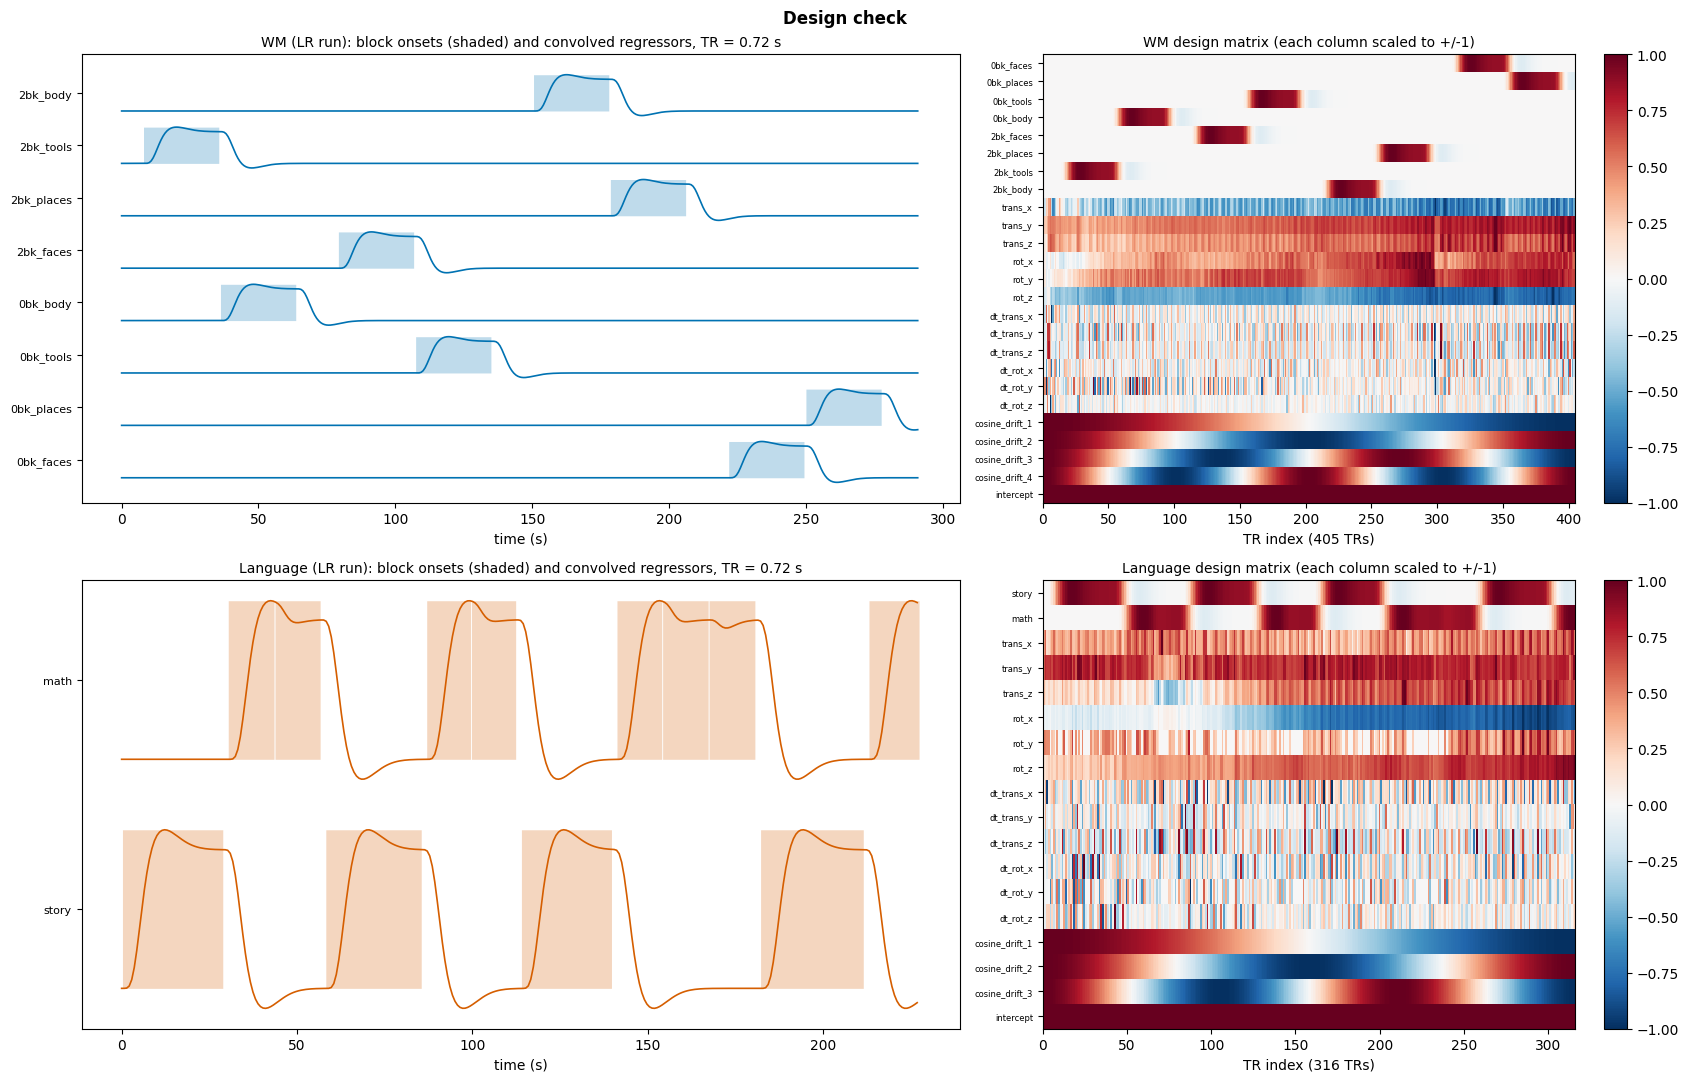

saved /Users/shwetharao/Downloads/figures_cell6/fig1_design_check.png


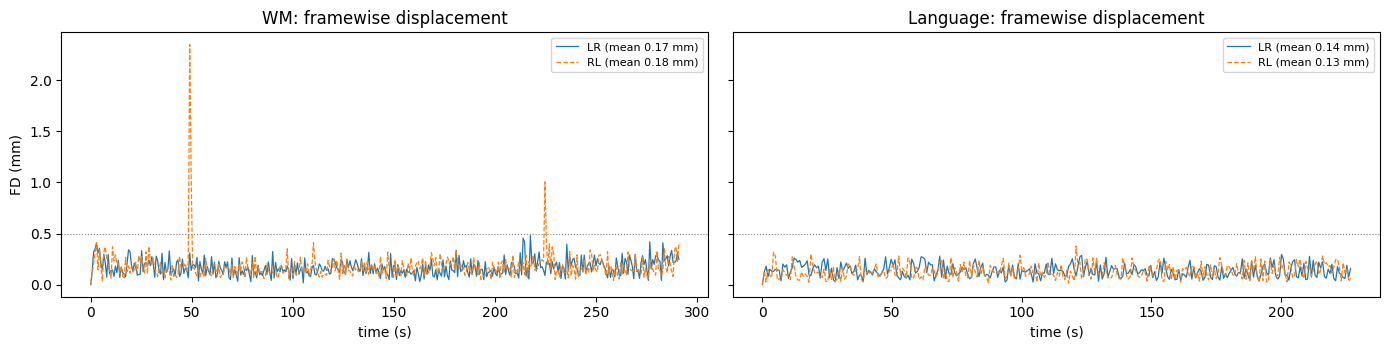

saved /Users/shwetharao/Downloads/figures_cell6/fig2_motion.png


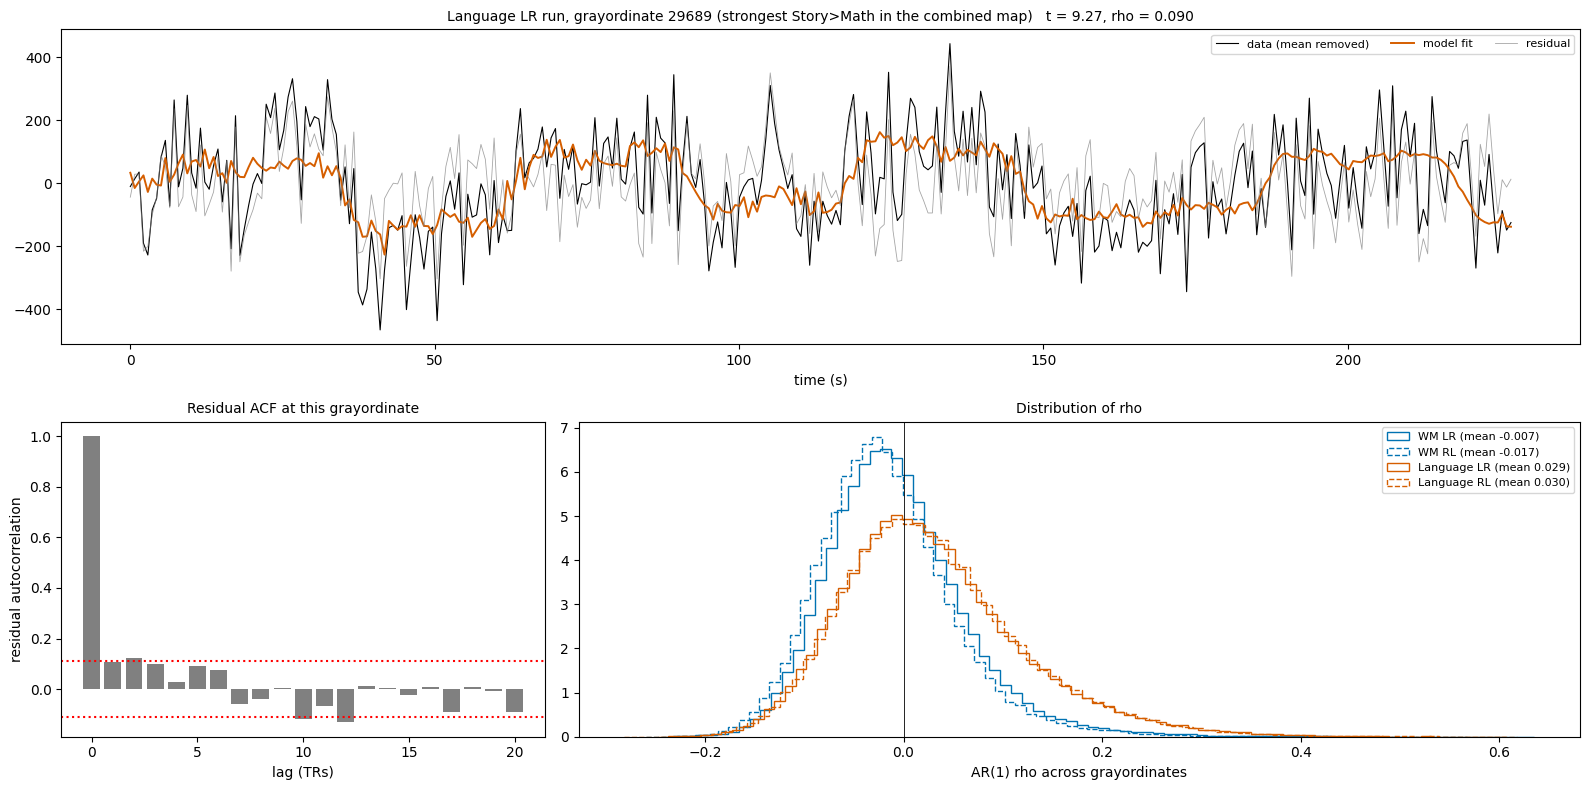

saved /Users/shwetharao/Downloads/figures_cell6/fig3_timecourse_and_rho.png


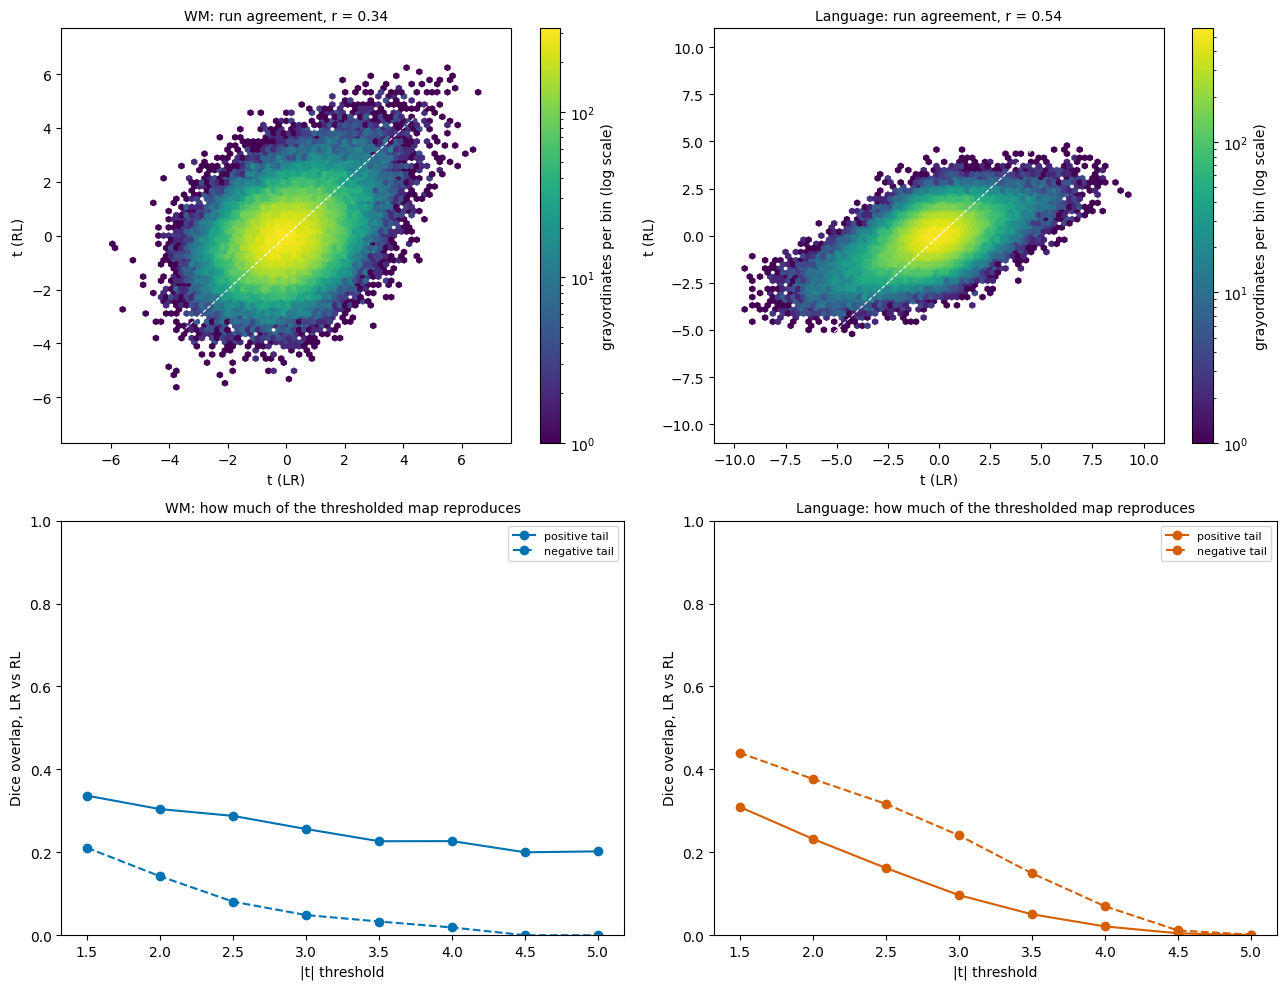

saved /Users/shwetharao/Downloads/figures_cell6/fig4_run_reproducibility.png


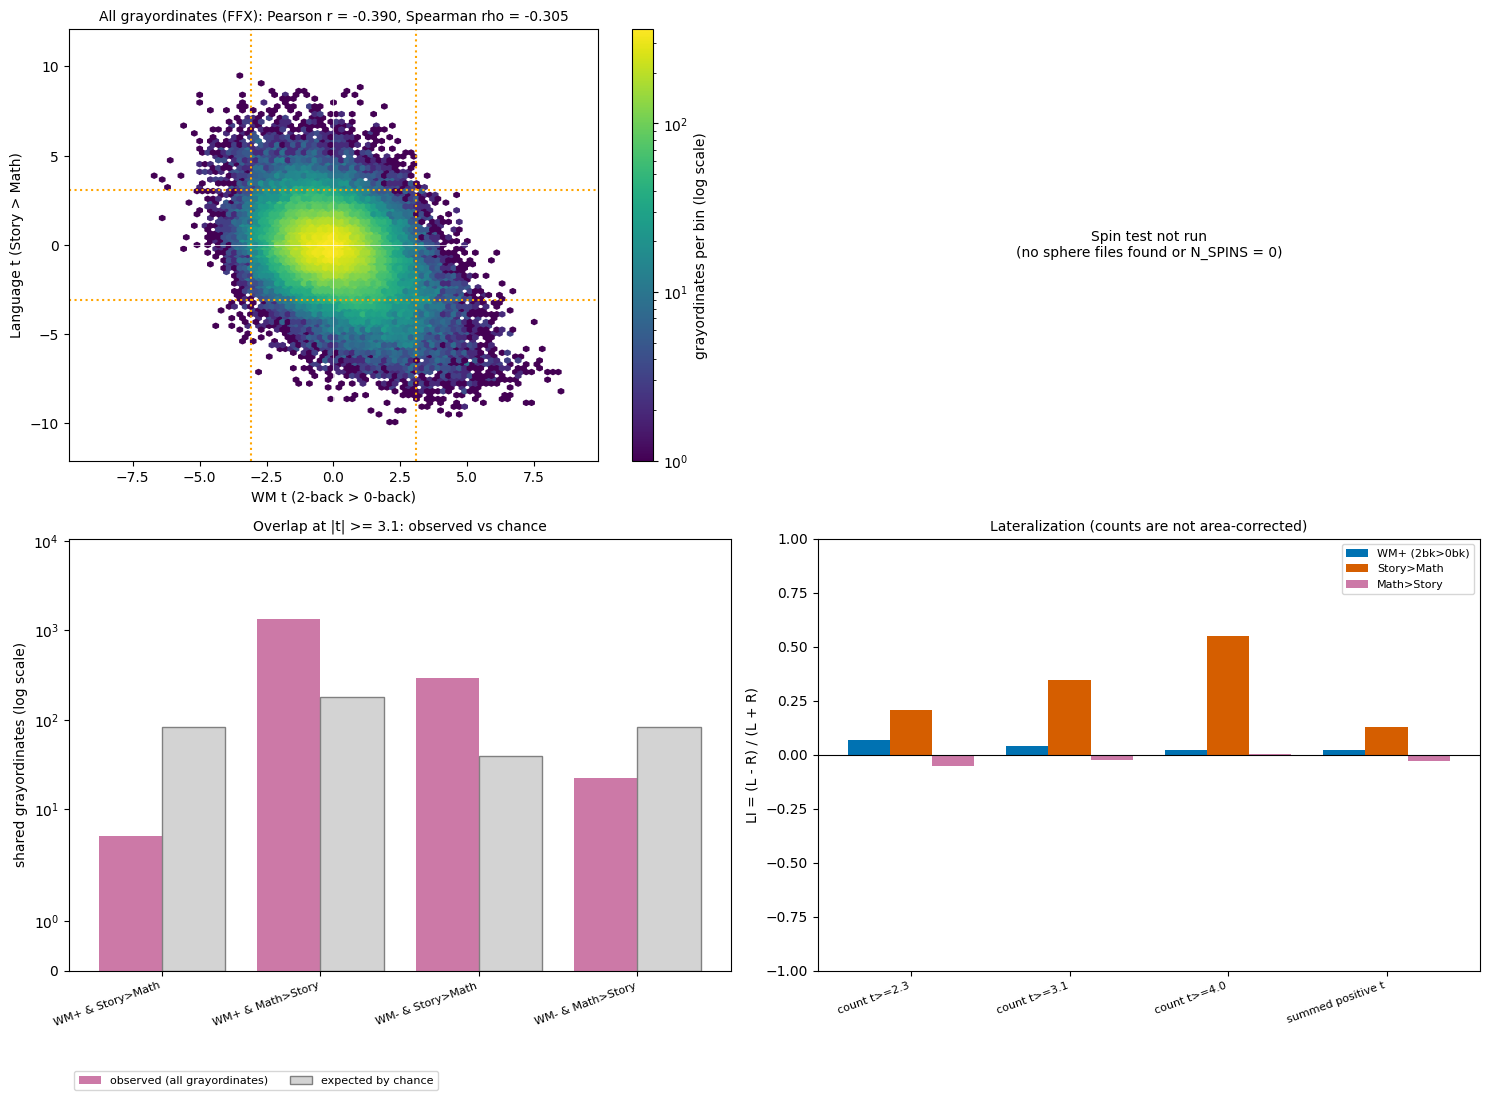

saved /Users/shwetharao/Downloads/figures_cell6/fig5_cross_task.png

Brain-surface maps skipped: no inflated 32k_fs_LR surfaces found in /Users/shwetharao/Downloads/103414/MNINonLinear/fsaverage_LR32k. Set SURFACE_PATHS in the config block.


In [ ]:
# ==============================================================================
# CELL 6 (REVISED): WM (2-back > 0-back) vs Language (Story > Math), first level
# Replaces the old cell 6 completely. Self-contained: needs no other cell.
#
# What changed compared with the old cell (item numbers refer to the review doc):
#   1  TR is one constant, HCP_TR = 0.72, used for every design matrix and label
#   2  Missing EV / motion / CIFTI files raise an error. No zero fill, no synthetic data
#   5  The printed report contains only numbers computed from the data (no fixed conclusions)
#   6  No p-values from treating 91,282 grayordinates as independent. Spin-test p-values instead
#   7  Overlap table: WM+/- against Story>Math and Math>Story, observed vs chance, spin p
#   8  Lateralization index at several thresholds + a threshold-free version
#   9  Both runs (LR, RL) fitted; fixed-effects (inverse-variance) combination
#  10  One shared GLM solver (rho-binned), checked against an exact per-voxel solver
# ==============================================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from scipy.special import gamma
from scipy.stats import pearsonr, spearmanr
from scipy.spatial import cKDTree
from scipy.spatial.transform import Rotation

# ------------------------------------------------------------------------------
# CONFIG  (edit only this block)
# ------------------------------------------------------------------------------
SUBJECT_ID = "103414"
RESULTS_DIR = "/Users/shwetharao/Downloads/103414/MNINonLinear/Results"   # contains tfMRI_WM_LR, ...
HCP_TR = 0.72                    # seconds. The CIFTI header of these files reports 1.0, which is wrong.
RUNS = ("LR", "RL")
T_THRESH = 3.1                   # uncorrected |t| threshold used for counts and overlaps
LI_THRESHOLDS = (2.3, 3.1, 4.0)  # thresholds for the lateralization index
N_SPINS = 1000                   # spin-test permutations; 0 switches the spin test off
SEED = 2026
FIG_DIR = "figures_cell6"        # every figure is also saved here as PNG
SPHERE_PATHS = None              # optional {'L': path, 'R': path} to *.sphere.32k_fs_LR.surf.gii
SURFACE_PATHS = None             # optional {'L': path, 'R': path} to *.inflated*.32k_fs_LR.surf.gii

WM_CONDS = ["0bk_faces", "0bk_places", "0bk_tools", "0bk_body",
            "2bk_faces", "2bk_places", "2bk_tools", "2bk_body"]
LANG_CONDS = ["story", "math"]
CIFTI_SUFFIX = "Atlas_MSMAll_hp0_clean_rclean_tclean.dtseries.nii"
EXPECTED_TRS = {"WM": 405, "LANGUAGE": 316}

COL_WM, COL_LANG, COL_BOTH = "#0072B2", "#D55E00", "#CC79A7"    # colour-blind-safe palette

try:                                   # the notebook's working folder may have been deleted or moved
    os.getcwd()
except FileNotFoundError:
    os.chdir(os.path.expanduser("~"))
    print("Working directory no longer existed; switched to", os.getcwd())
FIG_DIR = os.path.abspath(FIG_DIR)
os.makedirs(FIG_DIR, exist_ok=True)


def _loadtxt(path):
    """np.loadtxt on an open file handle (avoids numpy's DataSource, which needs a valid working directory)."""
    with open(path) as fh:
        return np.loadtxt(fh)


def _finish(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print("saved", path)


# ------------------------------------------------------------------------------
# 1. DESIGN MATRIX  (HRF, drift, motion, task regressors). Missing files raise errors.
# ------------------------------------------------------------------------------
def double_gamma_hrf(t, peak_delay=6.0, undershoot_delay=16.0,
                     peak_disp=1.0, undershoot_disp=1.0, ratio=1 / 6):
    a1, b1 = peak_delay / peak_disp, peak_disp
    a2, b2 = undershoot_delay / undershoot_disp, undershoot_disp
    with np.errstate(divide="ignore", invalid="ignore"):
        g1 = (t ** (a1 - 1) * np.exp(-t / b1)) / (gamma(a1) * (b1 ** a1))
        g2 = (t ** (a2 - 1) * np.exp(-t / b2)) / (gamma(a2) * (b2 ** a2))
    hrf = np.nan_to_num(g1 - ratio * g2)
    hrf[t < 0] = 0.0
    m = np.max(hrf)
    return hrf / m if m > 0 else hrf


def generate_dct_basis(n_trs, tr, hp_cutoff=128.0):
    k_max = int(np.floor(2 * n_trs * tr / hp_cutoff))
    t = np.arange(n_trs)
    cols = {f"cosine_drift_{k}": np.cos(np.pi * k * (2 * t + 1) / (2 * n_trs)) for k in range(1, k_max + 1)}
    return pd.DataFrame(cols, index=np.arange(n_trs))


MOTION_COLS = ["trans_x", "trans_y", "trans_z", "rot_x", "rot_y", "rot_z",
               "dt_trans_x", "dt_trans_y", "dt_trans_z", "dt_rot_x", "dt_rot_y", "dt_rot_z"]


def load_motion_regressors(filepath, n_trs):
    if not os.path.isfile(filepath):
        raise FileNotFoundError(filepath)
    data = _loadtxt(filepath)
    if data.shape[0] < n_trs or data.shape[1] < 12:
        raise ValueError(f"{filepath}: shape {data.shape}, need at least ({n_trs}, 12)")
    return pd.DataFrame(data[:n_trs, :12], columns=MOTION_COLS, index=np.arange(n_trs))


def build_task_regressors(evs_dir, cond_names, n_trs, tr, dt=0.01):
    """Block boxcar (from EV files: onset, duration, amplitude) convolved with the HRF, sampled at the TR grid.
    Returns the regressors and the high-resolution boxcars (used by the timing plot)."""
    t_high = np.arange(0, n_trs * tr, dt)
    t_tr = np.arange(n_trs) * tr
    hrf = double_gamma_hrf(np.arange(0, 32.0, dt))
    regs, boxes = {}, {"t_high": t_high}
    for name in cond_names:
        f = os.path.join(evs_dir, name + ".txt")
        if not (os.path.isfile(f) and os.path.getsize(f) > 0):
            raise FileNotFoundError(f)
        ev = np.atleast_2d(_loadtxt(f))
        box = np.zeros_like(t_high)
        for onset, dur, amp in ev[:, :3]:
            box[(t_high >= onset) & (t_high < onset + dur)] = amp
        conv = np.convolve(box, hrf)[:len(t_high)] * dt
        regs[name] = np.interp(t_tr, t_high, conv)
        boxes[name] = box
    return pd.DataFrame(regs, index=np.arange(n_trs)), boxes


def assemble_design(run_dir, cond_names, n_trs, tr):
    X_task, boxes = build_task_regressors(os.path.join(run_dir, "EVs"), cond_names, n_trs, tr)
    X_motion = load_motion_regressors(os.path.join(run_dir, "Movement_Regressors.txt"), n_trs)
    X_drift = generate_dct_basis(n_trs, tr)
    X_int = pd.DataFrame({"intercept": np.ones(n_trs)}, index=np.arange(n_trs))
    return pd.concat([X_task, X_motion, X_drift, X_int], axis=1), boxes


def make_contrast(columns, weights):
    """Contrast vector built from column names, so it cannot silently point at the wrong column."""
    c = np.zeros(len(columns))
    for name, w in weights.items():
        c[list(columns).index(name)] = w
    return c


WM_WEIGHTS = {**{c: -0.25 for c in WM_CONDS[:4]}, **{c: +0.25 for c in WM_CONDS[4:]}}   # 2-back > 0-back
LANG_WEIGHTS = {"story": +1.0, "math": -1.0}                                              # Story > Math


# ------------------------------------------------------------------------------
# 2. GLM: ONE shared AR(1)-prewhitened solver + an exact per-voxel reference for checking it
# ------------------------------------------------------------------------------
def fit_glm_ar1_binned(Y, X, C, rho_step=0.005):
    """AR(1)-prewhitened GLM; grayordinates grouped by rounded rho so each whitening matrix is inverted once per group.
    Y: (T, V); X: (T, P); C: (K, P). Returns cope, varcope, t of shape (K, V), and rho (V,)."""
    n_t, p = X.shape
    dof = n_t - p
    C = np.atleast_2d(C)
    xtx_inv = np.linalg.pinv(X.T @ X)
    res = Y - X @ (xtx_inv @ (X.T @ Y))
    rho = np.clip((res[1:] * res[:-1]).sum(0) / ((res ** 2).sum(0) + 1e-12), -0.99, 0.99)
    rho_bin = np.round(rho / rho_step) * rho_step
    cope = np.zeros((C.shape[0], Y.shape[1]))
    varcope = np.zeros_like(cope)
    for r in np.unique(rho_bin):
        idx = np.where(rho_bin == r)[0]
        s0 = np.sqrt(1 - r ** 2)
        Ys = np.vstack([Y[:1, idx] * s0, Y[1:, idx] - r * Y[:-1, idx]])
        Xs = np.vstack([X[:1] * s0, X[1:] - r * X[:-1]])
        xi = np.linalg.pinv(Xs.T @ Xs)
        B = xi @ (Xs.T @ Ys)
        sigma2 = ((Ys - Xs @ B) ** 2).sum(0) / dof
        cope[:, idx] = C @ B
        varcope[:, idx] = sigma2[None, :] * np.einsum("ij,jk,ik->i", C, xi, C)[:, None]
    t = cope / np.sqrt(varcope + 1e-12)
    return dict(cope=cope, varcope=varcope, t=t, rho=rho, dof=dof)


def fit_glm_ar1_single(y, X, c):
    """Exact (unbinned) AR(1) fit for ONE grayordinate. Used to validate the binned solver and for the time-course plot."""
    n_t, p = X.shape
    dof = n_t - p
    y = np.asarray(y, float)
    b0 = np.linalg.pinv(X.T @ X) @ (X.T @ y)
    r0 = y - X @ b0
    rho = float(np.clip((r0[1:] * r0[:-1]).sum() / ((r0 ** 2).sum() + 1e-12), -0.99, 0.99))
    s0 = np.sqrt(1 - rho ** 2)
    ys = np.concatenate([[y[0] * s0], y[1:] - rho * y[:-1]])
    Xs = np.vstack([X[:1] * s0, X[1:] - rho * X[:-1]])
    xi = np.linalg.pinv(Xs.T @ Xs)
    b = xi @ (Xs.T @ ys)
    sigma2 = ((ys - Xs @ b) ** 2).sum() / dof
    cope = float(c @ b)
    var = float(sigma2 * (c @ xi @ c))
    fit = X @ b
    return dict(beta=b, rho=rho, cope=cope, varcope=var, t=cope / np.sqrt(var + 1e-12), fit=fit, resid=y - fit)


def validate_solver(Y, X, C, n_check=500, seed=0):
    """Compare binned vs exact solver on random grayordinates."""
    rng = np.random.default_rng(seed)
    idx = rng.choice(Y.shape[1], size=min(n_check, Y.shape[1]), replace=False)
    fit = fit_glm_ar1_binned(Y[:, idx], X, C)
    ref = np.array([fit_glm_ar1_single(Y[:, i], X, C[0])["t"] for i in idx])
    r = np.corrcoef(fit["t"][0], ref)[0, 1]
    return dict(n=len(idx), corr=float(r), max_abs_diff=float(np.max(np.abs(fit["t"][0] - ref))))


def combine_fixed_effects(copes, varcopes):
    """Inverse-variance weighted fixed-effects combination across runs."""
    w = np.stack([1.0 / np.maximum(v, 1e-12) for v in varcopes])
    W = w.sum(0)
    cope = (w * np.stack(copes)).sum(0) / W
    var = 1.0 / W
    return cope, var, cope / np.sqrt(var + 1e-12)


# ------------------------------------------------------------------------------
# 3. CIFTI helpers
# ------------------------------------------------------------------------------
def load_cifti(path):
    if not os.path.isfile(path):
        raise FileNotFoundError(path)
    img = nib.load(path)
    series_axis, bm_axis = img.header.get_axis(0), img.header.get_axis(1)
    Y = np.asarray(img.dataobj, dtype=np.float32)          # float32 keeps memory about 1 GB for all four runs
    return Y, float(series_axis.step), bm_axis


def get_cortex_maps(bm_axis):
    """Where each hemisphere's cortical grayordinates sit, and which surface vertex each one is."""
    names = {"CIFTI_STRUCTURE_CORTEX_LEFT": "L", "CIFTI_STRUCTURE_CORTEX_RIGHT": "R"}
    out = {}
    for name, slc, bm in bm_axis.iter_structures():
        if name in names:
            out[names[name]] = dict(slice=slc, vertex=np.asarray(bm.vertex), nvert=int(bm.nvertices[name]))
    if set(out) != {"L", "R"}:
        raise ValueError("Could not find both cortical hemispheres in the CIFTI brain-model axis")
    return out


def cortex_vec(vec, cortex):
    """Cortical grayordinates only, left then right."""
    return np.concatenate([vec[cortex["L"]["slice"]], vec[cortex["R"]["slice"]]])


def to_surface(vec, cortex, hemi, fill=0.0):
    c = cortex[hemi]
    full = np.full(c["nvert"], fill, float)
    full[c["vertex"]] = vec[c["slice"]]
    return full


# ------------------------------------------------------------------------------
# 4. SPIN TEST (valid null for spatial correlations and overlaps on the cortex)
# ------------------------------------------------------------------------------
class SpinTester:
    """Rotates the sphere, reassigns each valid vertex the value of the nearest valid vertex (Alexander-Bloch style).
    Hemispheres are rotated independently. The medial wall is excluded, so spun maps never contain missing values."""

    def __init__(self, cortex, sphere_coords, n_spins, seed):
        self.cortex, self.n = cortex, n_spins
        self.idx = {}
        for k, h in enumerate("LR"):
            coords = np.asarray(sphere_coords[h], float)[cortex[h]["vertex"]]
            tree = cKDTree(coords)
            rng = np.random.default_rng(seed + k)
            idx = np.empty((n_spins, len(coords)), dtype=np.int32)
            for s in range(n_spins):
                q = rng.normal(size=4)
                R = Rotation.from_quat(q / np.linalg.norm(q)).as_matrix()     # uniform random rotation
                idx[s] = tree.query(coords @ R.T)[1]
            self.idx[h] = idx

    def chunks(self, vec, size=100):
        """Yield spun copies of a grayordinate vector: arrays of shape (<=size, n_cortex)."""
        parts = {h: vec[self.cortex[h]["slice"]] for h in "LR"}
        for a in range(0, self.n, size):
            yield np.concatenate([parts[h][self.idx[h][a:a + size]] for h in "LR"], axis=1)

    def corr_null(self, a_cx, vec_b):
        out = []
        for S in self.chunks(vec_b):
            out.extend(np.corrcoef(np.vstack([a_cx, s]))[0, 1] for s in S)
        return np.array(out)

    def overlap_null(self, A_cx, vec_mask_b):
        out = []
        for S in self.chunks(vec_mask_b.astype(float)):
            out.extend(((S > 0.5) & A_cx[None, :]).sum(1))
        return np.array(out)


def load_sphere_coords(paths):
    return {h: nib.load(paths[h]).darrays[0].data for h in "LR"}


def find_hcp_surfaces(results_dir, subject):
    """Looks for the 32k fs_LR surfaces that ship with every HCP subject (MNINonLinear/fsaverage_LR32k)."""
    d = os.path.join(os.path.dirname(os.path.normpath(results_dir)), "fsaverage_LR32k")
    found = {"sphere": {}, "surf": {}}
    for h in "LR":
        p = os.path.join(d, f"{subject}.{h}.sphere.32k_fs_LR.surf.gii")
        if os.path.isfile(p):
            found["sphere"][h] = p
        for kind in ("inflated_MSMAll", "inflated", "very_inflated", "midthickness"):
            p = os.path.join(d, f"{subject}.{h}.{kind}.32k_fs_LR.surf.gii")
            if os.path.isfile(p):
                found["surf"][h] = p
                break
    return found, d


# ------------------------------------------------------------------------------
# 5. ANALYSES: overlap table, lateralization, reliability
# ------------------------------------------------------------------------------
def overlap_table(t_wm, t_lang, cortex, spin, thr=T_THRESH):
    """WM +/- against Story>Math and Math>Story. Observed shared grayordinates vs the count expected by chance
    (all grayordinates), plus a spin-test null on the cortex."""
    N = len(t_wm)
    masks = {"WM+": t_wm >= thr, "WM-": t_wm <= -thr, "Story>Math": t_lang >= thr, "Math>Story": t_lang <= -thr}
    pairs = [("WM+", "Story>Math"), ("WM+", "Math>Story"), ("WM-", "Story>Math"), ("WM-", "Math>Story")]
    rows = []
    for a, b in pairs:
        A, B = masks[a], masks[b]
        obs, exp = int((A & B).sum()), A.sum() * B.sum() / N
        row = dict(pair=f"{a} & {b}", n_A=int(A.sum()), n_B=int(B.sum()), observed=obs, expected_chance=round(exp, 1),
                   obs_over_exp=obs / exp if exp > 0 else np.nan, dice=2 * obs / max(A.sum() + B.sum(), 1))
        A_cx, B_cx = cortex_vec(A, cortex), cortex_vec(B, cortex)
        row["cortex_observed"] = int((A_cx & B_cx).sum())
        if spin is not None:
            null = spin.overlap_null(A_cx, B)
            row["spin_null_mean"] = null.mean()
            row["spin_null_lo"], row["spin_null_hi"] = np.percentile(null, [2.5, 97.5])
            row["p_enriched"] = (1 + (null >= row["cortex_observed"]).sum()) / (len(null) + 1)
            row["p_depleted"] = (1 + (null <= row["cortex_observed"]).sum()) / (len(null) + 1)
        rows.append(row)
    return pd.DataFrame(rows), masks


def lateralization_table(maps, cortex, thresholds=LI_THRESHOLDS):
    """maps: {name: (t_vector, sign)}. LI = (L - R) / (L + R) from counts at each threshold, and from summed positive t
    (threshold-free). Not area-corrected (hemispheres have nearly equal vertex counts)."""
    rows = []
    for name, (t, sign) in maps.items():
        L, R = sign * t[cortex["L"]["slice"]], sign * t[cortex["R"]["slice"]]
        for thr in thresholds:
            nl, nr = int((L >= thr).sum()), int((R >= thr).sum())
            rows.append(dict(map=name, measure=f"count t>={thr}", left=nl, right=nr, LI=(nl - nr) / max(nl + nr, 1)))
        ml, mr = np.clip(L, 0, None).sum(), np.clip(R, 0, None).sum()
        rows.append(dict(map=name, measure="summed positive t", left=ml, right=mr, LI=(ml - mr) / max(ml + mr, 1e-12)))
    return pd.DataFrame(rows)


def framewise_displacement(X):
    """FD (mm). HCP motion columns: translations in mm, rotations in degrees (converted to a 50 mm sphere)."""
    d = np.abs(np.diff(X[MOTION_COLS[:6]].values, axis=0, prepend=X[MOTION_COLS[:6]].values[:1]))
    d[:, 3:] = np.deg2rad(d[:, 3:]) * 50.0
    return d.sum(1)


# ------------------------------------------------------------------------------
# 6. PLOTS
# ------------------------------------------------------------------------------
def plot_design_check(task_runs):
    """Fig 1. Block onsets and convolved regressors in SECONDS, plus the design matrices. Misalignment is visible here."""
    fig, axes = plt.subplots(2, 2, figsize=(17, 11), gridspec_kw=dict(width_ratios=[1.5, 1]))
    for row, (label, run, conds, color) in enumerate([("WM", task_runs["WM"]["LR"], WM_CONDS, COL_WM),
                                                      ("Language", task_runs["LANGUAGE"]["LR"], LANG_CONDS, COL_LANG)]):
        X, box = run["X"], run["boxcars"]
        t = np.arange(len(X)) * HCP_TR
        ax = axes[row, 0]
        for i, c in enumerate(conds):
            off = i * 1.3
            ax.fill_between(box["t_high"], off, off + box[c] * 0.9, step="mid", color=color, alpha=0.25, lw=0)
            reg = X[c].values
            ax.plot(t, off + reg / max(reg.max(), 1e-12) * 0.9, color=color, lw=1.2)
        ax.set_yticks([i * 1.3 + 0.45 for i in range(len(conds))])
        ax.set_yticklabels(conds, fontsize=8)
        ax.set_xlabel("time (s)")
        ax.set_title(f"{label} (LR run): block onsets (shaded) and convolved regressors, TR = {HCP_TR} s", fontsize=10)
        ax = axes[row, 1]
        Xn = X.values / np.maximum(np.abs(X.values).max(0), 1e-8)
        im = ax.imshow(Xn.T, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest",
                       extent=[0, len(X), len(X.columns), 0])
        ax.set_yticks(np.arange(len(X.columns)) + 0.5)
        ax.set_yticklabels(X.columns, fontsize=6)
        ax.set_xlabel(f"TR index ({len(X)} TRs)")
        ax.set_title(f"{label} design matrix (each column scaled to +/-1)", fontsize=10)
        fig.colorbar(im, ax=ax, fraction=0.04)
    fig.suptitle("Design check", fontweight="bold")
    fig.tight_layout()
    _finish(fig, "fig1_design_check.png")


def plot_motion(task_runs):
    """Fig 2. Framewise displacement for all four runs, for exclusion decisions."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
    for ax, (task, label) in zip(axes, [("WM", "WM"), ("LANGUAGE", "Language")]):
        for run, ls in zip(RUNS, ("-", "--")):
            fd = framewise_displacement(task_runs[task][run]["X"])
            ax.plot(np.arange(len(fd)) * HCP_TR, fd, ls, lw=0.9, label=f"{run} (mean {fd.mean():.2f} mm)")
        ax.axhline(0.5, color="gray", lw=0.8, ls=":")
        ax.set_xlabel("time (s)")
        ax.set_title(f"{label}: framewise displacement")
        ax.legend(fontsize=8)
    axes[0].set_ylabel("FD (mm)")
    fig.tight_layout()
    _finish(fig, "fig2_motion.png")


def plot_timecourse(y, run, c, title):
    """Fig 3. Data, model fit and residuals at the strongest Story>Math grayordinate, residual autocorrelation, rho histograms."""
    X = run["X"].values
    f = fit_glm_ar1_single(y, X, c)
    t = np.arange(len(y)) * HCP_TR
    fig = plt.figure(figsize=(16, 8))
    gs = fig.add_gridspec(2, 3)
    ax = fig.add_subplot(gs[0, :])
    ax.plot(t, y - y.mean(), color="k", lw=0.8, label="data (mean removed)")
    ax.plot(t, f["fit"] - y.mean(), color=COL_LANG, lw=1.4, label="model fit")
    ax.plot(t, f["resid"] - 0, color="gray", lw=0.6, alpha=0.7, label="residual")
    ax.set_xlabel("time (s)")
    ax.set_title(title + f"   t = {f['t']:.2f}, rho = {f['rho']:.3f}", fontsize=10)
    ax.legend(ncol=3, fontsize=8)
    r = f["resid"] - f["resid"].mean()
    nlag = 20
    acf = [np.sum(r[:len(r) - k] * r[k:]) / np.sum(r ** 2) for k in range(nlag + 1)]
    ax = fig.add_subplot(gs[1, 0])
    ax.bar(range(nlag + 1), acf, color="gray")
    ax.axhline(1.96 / np.sqrt(len(r)), color="r", ls=":")
    ax.axhline(-1.96 / np.sqrt(len(r)), color="r", ls=":")
    ax.set_xlabel("lag (TRs)")
    ax.set_ylabel("residual autocorrelation")
    ax.set_title("Residual ACF at this grayordinate", fontsize=10)
    ax = fig.add_subplot(gs[1, 1:])
    for (label, rho, col, ls) in run["rho_list"]:
        ax.hist(rho, bins=80, histtype="step", color=col, ls=ls, density=True, label=f"{label} (mean {rho.mean():.3f})")
    ax.axvline(0, color="k", lw=0.6)
    ax.set_xlabel("AR(1) rho across grayordinates")
    ax.set_title("Distribution of rho", fontsize=10)
    ax.legend(fontsize=8)
    fig.tight_layout()
    _finish(fig, "fig3_timecourse_and_rho.png")


def plot_reproducibility(rep):
    """Fig 4. LR vs RL agreement per task: t-map scatter and Dice overlap across thresholds."""
    fig, axes = plt.subplots(2, 2, figsize=(13, 10))
    for col, (name, color) in enumerate([("WM", COL_WM), ("Language", COL_LANG)]):
        a, b = rep[name]["lr"], rep[name]["rl"]
        lim = np.ceil(max(np.abs(a).max(), np.abs(b).max()))
        ax = axes[0, col]
        hb = ax.hexbin(a, b, gridsize=80, bins="log", mincnt=1, cmap="viridis", extent=(-lim, lim, -lim, lim))
        ax.plot([-lim, lim], [-lim, lim], "w--", lw=0.8)
        ax.set_xlabel("t (LR)")
        ax.set_ylabel("t (RL)")
        ax.set_title(f"{name}: run agreement, r = {np.corrcoef(a, b)[0, 1]:.2f}", fontsize=10)
        fig.colorbar(hb, ax=ax, label="grayordinates per bin (log scale)")
        ax = axes[1, col]
        ths = np.arange(1.5, 5.01, 0.5)
        for sign, ls, lab in [(1, "-", "positive tail"), (-1, "--", "negative tail")]:
            d = []
            for th in ths:
                A, B = sign * a >= th, sign * b >= th
                d.append(2 * (A & B).sum() / (A.sum() + B.sum()) if (A.sum() + B.sum()) > 0 else np.nan)   # nan = nothing passes
            ax.plot(ths, d, ls, color=color, marker="o", label=lab)
        ax.set_xlabel("|t| threshold")
        ax.set_ylabel("Dice overlap, LR vs RL")
        ax.set_ylim(0, 1)
        ax.set_title(f"{name}: how much of the thresholded map reproduces", fontsize=10)
        ax.legend(fontsize=8)
    fig.tight_layout()
    _finish(fig, "fig4_run_reproducibility.png")


def plot_cross_task(t_wm, t_lang, summary, ovl, li):
    """Fig 5. Joint density, spin null for the correlation, overlap against chance, lateralization."""
    fig, axes = plt.subplots(2, 2, figsize=(15, 11))
    ax = axes[0, 0]
    lx, ly = np.ceil(np.abs(t_wm).max()), np.ceil(np.abs(t_lang).max())
    hb = ax.hexbin(t_wm, t_lang, gridsize=90, bins="log", mincnt=1, cmap="viridis", extent=(-lx, lx, -ly, ly))
    for v in (-T_THRESH, T_THRESH):
        ax.axvline(v, color="orange", ls=":")
        ax.axhline(v, color="orange", ls=":")
    ax.axhline(0, color="w", lw=0.5)
    ax.axvline(0, color="w", lw=0.5)
    ax.set_xlabel("WM t (2-back > 0-back)")
    ax.set_ylabel("Language t (Story > Math)")
    ax.set_title(f"All grayordinates (FFX): Pearson r = {summary['pearson']:+.3f}, Spearman rho = {summary['spearman']:+.3f}", fontsize=10)
    fig.colorbar(hb, ax=ax, label="grayordinates per bin (log scale)")
    ax = axes[0, 1]
    if summary.get("corr_null") is not None:
        ax.hist(summary["corr_null"], bins=50, color="lightgray", edgecolor="gray")
        ax.axvline(summary["cortex_pearson"], color=COL_LANG, lw=2, label=f"observed (cortex) r = {summary['cortex_pearson']:+.3f}")
        ax.set_title(f"Spin-test null of the cortical correlation, p = {summary['spin_p']:.3f}", fontsize=10)
        ax.set_xlabel("correlation after spinning the Language map")
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, "Spin test not run\n(no sphere files found or N_SPINS = 0)", ha="center", va="center")
        ax.set_axis_off()
    ax = axes[1, 0]
    x = np.arange(len(ovl))
    ax.bar(x - 0.2, ovl["observed"], 0.4, color=COL_BOTH, label="observed (all grayordinates)")
    ax.bar(x + 0.2, ovl["expected_chance"], 0.4, color="lightgray", edgecolor="gray", label="expected by chance")
    ax.set_xticks(x)
    ax.set_xticklabels(ovl["pair"], rotation=20, ha="right", fontsize=8)
    ax.set_yscale("symlog")
    ax.set_ylim(0, max(ovl["observed"].max(), ovl["expected_chance"].max(), 10) * 8)     # headroom for the p labels
    ax.set_ylabel("shared grayordinates (log scale)")
    ax.set_title(f"Overlap at |t| >= {T_THRESH}: observed vs chance", fontsize=10)
    if "p_enriched" in ovl:
        for xi, (pe, pd_) in enumerate(zip(ovl["p_enriched"], ovl["p_depleted"])):
            lab = f"spin p(enrich) = {pe:.3f}" if pe <= pd_ else f"spin p(deplete) = {pd_:.3f}"
            ax.text(xi, 0.98, lab, ha="center", va="top", fontsize=7, transform=ax.get_xaxis_transform())
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.22), ncol=2)
    ax = axes[1, 1]
    meas = list(li["measure"].unique())
    maps = list(li["map"].unique())
    w = 0.8 / len(maps)
    for k, (m, col) in enumerate(zip(maps, [COL_WM, COL_LANG, COL_BOTH])):
        sub = li[li["map"] == m].set_index("measure").loc[meas]
        ax.bar(np.arange(len(meas)) + (k - (len(maps) - 1) / 2) * w, sub["LI"], w, color=col, label=m)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(np.arange(len(meas)))
    ax.set_xticklabels(meas, rotation=20, ha="right", fontsize=8)
    ax.set_ylabel("LI = (L - R) / (L + R)")
    ax.set_ylim(-1, 1)
    ax.set_title("Lateralization (counts are not area-corrected)", fontsize=10)
    ax.legend(fontsize=8)
    fig.tight_layout()
    _finish(fig, "fig5_cross_task.png")


def _mesh_from_gifti(path):
    g = nib.load(path)
    return [np.asarray(g.darrays[0].data, float), np.asarray(g.darrays[1].data, int)]


def plot_surface_rows(rows, meshes, fname, suptitle):
    """Rows of brain maps: left lateral, left medial, right lateral, right medial. Needs nilearn and HCP 32k surfaces."""
    from nilearn import plotting
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize, ListedColormap
    views = [("left", "lateral", "L"), ("left", "medial", "L"), ("right", "lateral", "R"), ("right", "medial", "R")]
    fig = plt.figure(figsize=(4 * 3.3, len(rows) * 3.4))
    for r, row in enumerate(rows):
        for c, (hemi, view, h) in enumerate(views):
            ax = fig.add_subplot(len(rows), 4, r * 4 + c + 1, projection="3d")
            if row["kind"] == "stat":
                plotting.plot_surf_stat_map(meshes[h], stat_map=row["data"][h], hemi=hemi, view=view,
                                            threshold=row["thr"], vmax=row["vmax"], cmap=row["cmap"],
                                            axes=ax, colorbar=False)
            else:
                plotting.plot_surf_roi(meshes[h], roi_map=row["data"][h], hemi=hemi, view=view,
                                       cmap=ListedColormap(row["colors"]), vmin=1, vmax=len(row["colors"]),
                                       axes=ax, colorbar=False)
            if c == 0:
                ax.set_title(row["title"], loc="left", fontsize=10, fontweight="bold")
        if row["kind"] == "stat":
            sm = ScalarMappable(norm=Normalize(-row["vmax"], row["vmax"]), cmap=row["cmap"])
            fig.colorbar(sm, ax=fig.axes[-4:], fraction=0.015, pad=0.01, label=row.get("label", "t"))
        else:
            from matplotlib.patches import Patch
            fig.axes[-1].legend(handles=[Patch(color=cc, label=ll) for cc, ll in zip(row["colors"], row["labels"])],
                                loc="lower right", fontsize=8)
    fig.suptitle(suptitle, fontweight="bold")
    _finish(fig, fname)


# ------------------------------------------------------------------------------
# 7. DRIVER
# ------------------------------------------------------------------------------
def run_cell6():
    tasks = {"WM": dict(conds=WM_CONDS, weights=WM_WEIGHTS), "LANGUAGE": dict(conds=LANG_CONDS, weights=LANG_WEIGHTS)}
    task_runs, Y_keep, bm_axis = {}, None, None
    for task, spec in tasks.items():
        task_runs[task] = {}
        for run in RUNS:
            run_dir = os.path.join(RESULTS_DIR, f"tfMRI_{task}_{run}")
            Y, hdr_tr, bm = load_cifti(os.path.join(run_dir, f"tfMRI_{task}_{run}_{CIFTI_SUFFIX}"))
            if bm_axis is None:
                bm_axis = bm
            if Y.shape[0] != EXPECTED_TRS[task]:
                print(f"WARNING {task}_{run}: {Y.shape[0]} frames, expected {EXPECTED_TRS[task]}")
            print(f"{task}_{run}: {Y.shape[0]} frames x {Y.shape[1]} grayordinates | header TR = {hdr_tr:.3f} s | using HCP_TR = {HCP_TR} s")
            X, boxes = assemble_design(run_dir, spec["conds"], Y.shape[0], HCP_TR)
            C = make_contrast(X.columns, spec["weights"])
            if task == "LANGUAGE" and run == RUNS[0]:
                chk = validate_solver(Y, X.values, C[None, :])
                print(f"  solver check on {chk['n']} random grayordinates: r(binned, exact) = {chk['corr']:.5f}, "
                      f"max |dt| = {chk['max_abs_diff']:.3f}")
                Y_keep = Y
            fit = fit_glm_ar1_binned(Y, X.values, C[None, :])
            task_runs[task][run] = dict(X=X, boxcars=boxes, C=C, cope=fit["cope"][0], varcope=fit["varcope"][0],
                                        t=fit["t"][0], rho=fit["rho"])
            if Y is not Y_keep:
                del Y
    cortex = get_cortex_maps(bm_axis)

    # combine LR + RL (inverse-variance fixed effects) and report each run separately
    ffx = {}
    for task in tasks:
        r = task_runs[task]
        cope, var, t = combine_fixed_effects([r[k]["cope"] for k in RUNS], [r[k]["varcope"] for k in RUNS])
        ffx[task] = dict(cope=cope, var=var, t=t)
    t_wm, t_lang = ffx["WM"]["t"], ffx["LANGUAGE"]["t"]

    print("\n=== Grayordinates above threshold (uncorrected) ===")
    cnt = []
    for task, tag in (("WM", "WM 2bk>0bk"), ("LANGUAGE", "Story>Math")):
        for src, tt in [(k, task_runs[task][k]["t"]) for k in RUNS] + [("FFX", ffx[task]["t"])]:
            cnt.append(dict(map=tag, source=src, positive=int((tt >= T_THRESH).sum()), negative=int((tt <= -T_THRESH).sum()),
                            pct_pos=round(100 * (tt >= T_THRESH).mean(), 2), pct_neg=round(100 * (tt <= -T_THRESH).mean(), 2)))
    print(pd.DataFrame(cnt).to_string(index=False))

    # spin test setup (needs the standard fs_LR 32k sphere, which every HCP subject folder contains)
    found, sdir = find_hcp_surfaces(RESULTS_DIR, SUBJECT_ID)
    sphere_paths = SPHERE_PATHS or (found["sphere"] if len(found["sphere"]) == 2 else None)
    spin = None
    if N_SPINS > 0 and sphere_paths:
        print(f"\nBuilding {N_SPINS} spins from {sphere_paths['L']} ...")
        spin = SpinTester(cortex, load_sphere_coords(sphere_paths), N_SPINS, SEED)
    elif N_SPINS > 0:
        print(f"\nSpin test skipped: no *.sphere.32k_fs_LR.surf.gii found in {sdir}. Set SPHERE_PATHS in the config block.")

    # cross-task summary
    pr, _ = pearsonr(t_wm, t_lang)
    sr, _ = spearmanr(t_wm, t_lang)
    a_cx, b_cx = cortex_vec(t_wm, cortex), cortex_vec(t_lang, cortex)
    summary = dict(pearson=pr, spearman=sr, cortex_pearson=pearsonr(a_cx, b_cx)[0], corr_null=None, spin_p=np.nan)
    if spin is not None:
        null = spin.corr_null(a_cx, t_lang)
        summary["corr_null"] = null
        summary["spin_p"] = (1 + (np.abs(null) >= abs(summary["cortex_pearson"])).sum()) / (len(null) + 1)
    ovl, masks = overlap_table(t_wm, t_lang, cortex, spin)
    li = lateralization_table({"WM+ (2bk>0bk)": (t_wm, +1), "Story>Math": (t_lang, +1), "Math>Story": (t_lang, -1)}, cortex)

    # reliability across runs
    rep = {"WM": dict(lr=task_runs["WM"]["LR"]["t"], rl=task_runs["WM"]["RL"]["t"]),
           "Language": dict(lr=task_runs["LANGUAGE"]["LR"]["t"], rl=task_runs["LANGUAGE"]["RL"]["t"])}

    # ---- report: numbers only, all computed from the data ----
    print("\n" + "=" * 78)
    print("CROSS-TASK REPORT: WM (2-back > 0-back) vs Language (Story > Math)")
    print(f"Subject {SUBJECT_ID} | runs {RUNS} combined with inverse-variance fixed effects | TR = {HCP_TR} s | uncorrected |t| >= {T_THRESH}")
    print("=" * 78)
    print(f"Run reliability (t-map correlation LR vs RL): WM r = {np.corrcoef(rep['WM']['lr'], rep['WM']['rl'])[0, 1]:.3f}, "
          f"Language r = {np.corrcoef(rep['Language']['lr'], rep['Language']['rl'])[0, 1]:.3f}")
    print(f"Spatial correlation, all {len(t_wm):,} grayordinates: Pearson r = {pr:+.4f}, Spearman rho = {sr:+.4f}  (no p-value: grayordinates are not independent)")
    if spin is not None:
        print(f"Cortex only: Pearson r = {summary['cortex_pearson']:+.4f}, spin-test p = {summary['spin_p']:.4f} "
              f"({N_SPINS} spins; 95% null interval {np.percentile(summary['corr_null'], 2.5):+.3f} to {np.percentile(summary['corr_null'], 97.5):+.3f})")
    print("\nOverlap of thresholded maps (observed vs expected by chance across all grayordinates; spin p on the cortex):")
    print(ovl.round(4).to_string(index=False))
    print("\nLateralization (LI = (L-R)/(L+R); counts not area-corrected):")
    print(li.round(3).to_string(index=False))
    print("\nNotes: one subject, uncorrected threshold, positive-tail counts depend on the threshold. Treat as descriptive.")

    # ---- plots ----
    plot_design_check(task_runs)
    plot_motion(task_runs)
    peak = int(np.argmax(ffx["LANGUAGE"]["t"]))
    lang_lr = task_runs["LANGUAGE"][RUNS[0]]
    lang_lr["rho_list"] = [("WM LR", task_runs["WM"]["LR"]["rho"], COL_WM, "-"), ("WM RL", task_runs["WM"]["RL"]["rho"], COL_WM, "--"),
                           ("Language LR", task_runs["LANGUAGE"]["LR"]["rho"], COL_LANG, "-"),
                           ("Language RL", task_runs["LANGUAGE"]["RL"]["rho"], COL_LANG, "--")]
    plot_timecourse(Y_keep[:, peak].astype(float), lang_lr, lang_lr["C"],
                    f"Language LR run, grayordinate {peak} (strongest Story>Math in the combined map)")
    plot_reproducibility(rep)
    plot_cross_task(t_wm, t_lang, summary, ovl, li)
    '''
    surf_paths = SURFACE_PATHS or (found["surf"] if len(found["surf"]) == 2 else None)
    if surf_paths is None:
        print(f"\nBrain-surface maps skipped: no inflated 32k_fs_LR surfaces found in {sdir}. Set SURFACE_PATHS in the config block.")
    else:
        try:
            meshes = {h: _mesh_from_gifti(surf_paths[h]) for h in "LR"}
            both = lambda v: {h: to_surface(v, cortex, h) for h in "LR"}
            vmax = float(np.ceil(max(np.abs(t_wm).max(), np.abs(t_lang).max())))
            plot_surface_rows([dict(kind="stat", title="WM: 2-back > 0-back (t)", data=both(t_wm), thr=T_THRESH, vmax=vmax, cmap="RdBu_r"),
                               dict(kind="stat", title="Language: Story > Math (t; negative = Math > Story)", data=both(t_lang),
                                    thr=T_THRESH, vmax=vmax, cmap="RdBu_r")],
                              meshes, "fig6_surface_t_maps.png", f"Combined LR+RL t-maps, |t| >= {T_THRESH} shown (uncorrected)")
            def label_map(a, b):
                out = {}
                for h in "LR":
                    A, B = to_surface(masks[a].astype(float), cortex, h) > 0.5, to_surface(masks[b].astype(float), cortex, h) > 0.5
                    lab = np.zeros(len(A))
                    lab[A & ~B], lab[B & ~A], lab[A & B] = 1, 2, 3
                    out[h] = lab
                return out
            plot_surface_rows([dict(kind="roi", title="WM+ vs Math > Story", data=label_map("WM+", "Math>Story"),
                                    colors=[COL_WM, COL_LANG, COL_BOTH], labels=["WM+ only", "Math>Story only", "both"]),
                               dict(kind="roi", title="WM+ vs Story > Math", data=label_map("WM+", "Story>Math"),
                                    colors=[COL_WM, COL_LANG, COL_BOTH], labels=["WM+ only", "Story>Math only", "both"])],
                              meshes, "fig7_surface_overlap.png", f"Where the thresholded maps overlap (|t| >= {T_THRESH}, uncorrected)")
            rho_mean = (task_runs["LANGUAGE"]["LR"]["rho"] + task_runs["LANGUAGE"]["RL"]["rho"]) / 2
            plot_surface_rows([dict(kind="stat", title="Mean AR(1) rho, Language", data=both(rho_mean), thr=0.0, vmax=0.3,
                                    cmap="RdBu_r", label="rho")], meshes, "fig8_surface_rho.png", "Residual autocorrelation")
        except Exception as e:                      # plotting problems must never lose the numbers above
            print(f"\nSurface plots failed ({type(e).__name__}: {e}). Is nilearn installed (pip install nilearn)?")
    '''
    # keep results available in the notebook (the old overlap snippet uses t_wm and t_lang)
    return dict(task_runs=task_runs, ffx=ffx, cortex=cortex, overlap=ovl, lateralization=li, summary=summary, masks=masks)


cell6 = run_cell6()
t_wm, t_lang = cell6["ffx"]["WM"]["t"], cell6["ffx"]["LANGUAGE"]["t"]

## Split-half RSA: visual (WM) and auditory (Language)

Run order: cell 0 (setup), then the cells below. Cell 6 (first-level GLM) is not needed for this part, but its functions are not either: this section is self-contained.

1. **Patterns**: per-condition t-patterns for WM (8 conditions) and Language (story, math), runs LR and RL, for every subject in `SUBJECTS`. TR and number of frames are read from each CIFTI header; the GLM is the same AR(1)-prewhitened GLM as above, grouped by rounded rho so it runs in seconds.
2. **ROI masks**: says which of the 91,282 grayordinates belong to which named brain region (Glasser parcels). The parcellation files download automatically. `ROI_DEFS` is the list of areas that make up each ROI; both of you must use the same list, decided before looking at any result.
3. **RSA functions**: own NumPy implementation (cross-run correlation, crossnobis, identification, voxel removal, group tests).
4. **WM split-half RSA**: identification within 0-back, within 2-back and across load, and RDM heatmaps. Plots with per-subject dots follow.
5. **Language split-half RSA**: story-minus-math pattern reliability across runs, and crossnobis distance.

Notes: a single subject only supports descriptive numbers. The sign-flip test across n subjects cannot give p below 2/2^n (0.031 for 6 subjects), so aim for 15 or more before testing. Decide which ROI x metric tests are confirmatory before reading results; the FDR step corrects across everything printed.


In [3]:
# ============ SPLIT-HALF RSA, STEP 1: per-condition patterns for every subject ============
# Needs cell 0 to have run (double_gamma_hrf, generate_dct_basis, subject_dir).
# Output: derivatives/<subject>_patterns.npz with t- and beta-patterns (n_conditions x 91282)
#         for WM (8 conditions) and LANGUAGE (story, math), runs LR and RL.
import os
import numpy as np
import pandas as pd
import nibabel as nib

DATA_ROOT = os.path.dirname(os.path.dirname(os.path.dirname(subject_dir)))   # folder holding <subject_id>/MNINonLinear/Results
SUBJECTS = [
    "103414",
    "105014",
    "103212",
    "115219",
    "101107",
    "107321",
    "139839",
    "108121"
]                                                        # add the other subject IDs here
OUT_DIR = "derivatives"
os.makedirs(OUT_DIR, exist_ok=True)

WM_CONDS = ["0bk_faces", "0bk_places", "0bk_tools", "0bk_body", "2bk_faces", "2bk_places", "2bk_tools", "2bk_body"]
LANG_CONDS = ["story", "math"]


def build_design(evs_dir, motion_path, cond_names, n_trs, tr, dt=0.01):
    """Same design as your cell 0 / cell 6 builders (block boxcar * double-gamma HRF, 12 motion, DCT drift,
    intercept) but TR and n_trs come from the file, and a missing EV file is an error, not a silent zero."""
    t_high, t_tr = np.arange(0, n_trs * tr, dt), np.arange(n_trs) * tr
    hrf = double_gamma_hrf(np.arange(0, 32.0, dt))
    cols = {}
    for name in cond_names:
        f = os.path.join(evs_dir, name + ".txt")
        if not (os.path.exists(f) and os.path.getsize(f) > 0):
            raise FileNotFoundError(f)
        box = np.zeros_like(t_high)
        for onset, dur, amp in np.atleast_2d(np.loadtxt(f)):
            box[(t_high >= onset) & (t_high < onset + dur)] = amp
        cols[name] = np.interp(t_tr, t_high, np.convolve(box, hrf)[:len(t_high)] * dt)
    motion_cols = ["trans_x", "trans_y", "trans_z", "rot_x", "rot_y", "rot_z",
                   "dt_trans_x", "dt_trans_y", "dt_trans_z", "dt_rot_x", "dt_rot_y", "dt_rot_z"]
    motion = pd.DataFrame(np.loadtxt(motion_path)[:n_trs, :12], columns=motion_cols)
    return pd.concat([pd.DataFrame(cols), motion, generate_dct_basis(n_trs, tr, 128.0),
                      pd.DataFrame({"intercept": np.ones(n_trs)})], axis=1)


def fit_glm_ar1_binned(Y, X, C, rho_step=0.005):
    """Your AR(1)-prewhitened GLM, but grayordinates are grouped by rounded rho so each whitening matrix is
    inverted once per group instead of once per grayordinate. C: (n_contrasts, n_regressors).
    Returns copes, t-stats (n_contrasts, n_grayordinates) and rho."""
    n_t, p = X.shape
    dof = n_t - p
    res = Y - X @ (np.linalg.pinv(X.T @ X) @ X.T @ Y)
    rho = np.clip((res[1:] * res[:-1]).sum(0) / ((res ** 2).sum(0) + 1e-12), -0.99, 0.99)
    rho_bin = np.round(rho / rho_step) * rho_step
    copes = np.zeros((C.shape[0], Y.shape[1]))
    tstats = np.zeros_like(copes)
    for r in np.unique(rho_bin):
        idx = np.where(rho_bin == r)[0]
        s0 = np.sqrt(1 - r ** 2)
        Ys = np.vstack([Y[:1, idx] * s0, Y[1:, idx] - r * Y[:-1, idx]])
        Xs = np.vstack([X[:1] * s0, X[1:] - r * X[:-1]])
        xtx_inv = np.linalg.pinv(Xs.T @ Xs)
        B = xtx_inv @ Xs.T @ Ys
        sigma2 = ((Ys - Xs @ B) ** 2).sum(0) / dof
        cope = C @ B
        var = sigma2[None, :] * np.einsum("ij,jk,ik->i", C, xtx_inv, C)[:, None]
        copes[:, idx], tstats[:, idx] = cope, cope / np.sqrt(var + 1e-12)
    return copes, tstats, rho


def subject_patterns(sid, force=False):
    path = os.path.join(OUT_DIR, f"{sid}_patterns.npz")
    if os.path.exists(path) and not force:
        return path
    out = {}
    for task, conds in (("WM", WM_CONDS), ("LANGUAGE", LANG_CONDS)):
        for run in ("LR", "RL"):
            d = os.path.join(DATA_ROOT, sid, "MNINonLinear", "Results", f"tfMRI_{task}_{run}")
            img = nib.load(os.path.join(d, f"tfMRI_{task}_{run}_Atlas_MSMAll_hp0_clean_rclean_tclean.dtseries.nii"))
            ax = img.header.get_axis(0)                      # SeriesAxis: TR and number of frames from the file itself
            tr, n_trs = 0.72, int(ax.size)
            Y = img.get_fdata()
            X = build_design(os.path.join(d, "EVs"), os.path.join(d, "Movement_Regressors.txt"), conds, n_trs, tr)
            assert list(X.columns[:len(conds)]) == conds
            C = np.zeros((len(conds), X.shape[1]))
            C[np.arange(len(conds)), np.arange(len(conds))] = 1.0     # one contrast per condition (vs implicit baseline)
            copes, tstats, rho = fit_glm_ar1_binned(Y, X.values, C)
            out[f"{task}_{run}_t"], out[f"{task}_{run}_beta"] = tstats.astype(np.float32), copes.astype(np.float32)
            print(f"{sid} {task}_{run}: TR from header = {tr:.3f} s, frames = {n_trs}, mean rho = {rho.mean():.3f}")
    np.savez_compressed(path, **out)
    return path


FORCE_REBUILD = False      # True after changing the TR, the design or the GLM code; False fits only subjects without a pattern file
for sid in SUBJECTS:
    subject_patterns(sid, force=FORCE_REBUILD)


107321 WM_LR: TR from header = 0.720 s, frames = 405, mean rho = -0.022
107321 WM_RL: TR from header = 0.720 s, frames = 405, mean rho = -0.016
107321 LANGUAGE_LR: TR from header = 0.720 s, frames = 316, mean rho = 0.023
107321 LANGUAGE_RL: TR from header = 0.720 s, frames = 316, mean rho = 0.019
139839 WM_LR: TR from header = 0.720 s, frames = 405, mean rho = -0.006
139839 WM_RL: TR from header = 0.720 s, frames = 405, mean rho = -0.014
139839 LANGUAGE_LR: TR from header = 0.720 s, frames = 316, mean rho = 0.017
139839 LANGUAGE_RL: TR from header = 0.720 s, frames = 316, mean rho = 0.011
108121 WM_LR: TR from header = 0.720 s, frames = 405, mean rho = 0.009
108121 WM_RL: TR from header = 0.720 s, frames = 405, mean rho = 0.012
108121 LANGUAGE_LR: TR from header = 0.720 s, frames = 316, mean rho = 0.049
108121 LANGUAGE_RL: TR from header = 0.720 s, frames = 316, mean rho = 0.048


In [4]:
# ============ VALIDATE ALL SUBJECTS LISTED IN SUBJECTS ============

import os
import nibabel as nib
import numpy as np

REQUIRED_TASKS = {
    "WM": [
        "0bk_faces", "0bk_places", "0bk_tools", "0bk_body",
        "2bk_faces", "2bk_places", "2bk_tools", "2bk_body",
    ],
    "LANGUAGE": ["story", "math"],
}

RUNS = ["LR", "RL"]

print("Checking HCP input files for all subjects...\n")

validation_errors = []

for sid in SUBJECTS:
    print(f"Subject {sid}")

    for task, conditions in REQUIRED_TASKS.items():
        for run in RUNS:
            run_dir = os.path.join(
                DATA_ROOT, sid, "MNINonLinear", "Results",
                f"tfMRI_{task}_{run}"
            )

            dtseries = os.path.join(
                run_dir,
                f"tfMRI_{task}_{run}_Atlas_MSMAll_hp0_clean_rclean_tclean.dtseries.nii"
            )
            motion = os.path.join(run_dir, "Movement_Regressors.txt")
            ev_dir = os.path.join(run_dir, "EVs")

            for path in [dtseries, motion]:
                if not os.path.isfile(path):
                    validation_errors.append(
                        f"{sid} {task}_{run}: missing {path}"
                    )

            for cond in conditions:
                ev_file = os.path.join(ev_dir, f"{cond}.txt")
                if not os.path.isfile(ev_file) or os.path.getsize(ev_file) == 0:
                    validation_errors.append(
                        f"{sid} {task}_{run}: missing/empty EV {ev_file}"
                    )

            if os.path.isfile(dtseries):
                img = nib.load(dtseries)
                print(
                    f"  {task}_{run}: "
                    f"{img.shape[0]} time points, "
                    f"{img.shape[1]} grayordinates"
                )

if validation_errors:
    print("\nVALIDATION FAILED:")
    for err in validation_errors:
        print(" -", err)
    raise FileNotFoundError(
        "Fix the missing files above before running pattern extraction."
    )

print("\nAll required task, EV, and motion files were found.")

Checking HCP input files for all subjects...

Subject 103414
  WM_LR: 405 time points, 91282 grayordinates
  WM_RL: 405 time points, 91282 grayordinates
  LANGUAGE_LR: 316 time points, 91282 grayordinates
  LANGUAGE_RL: 316 time points, 91282 grayordinates
Subject 105014
  WM_LR: 405 time points, 91282 grayordinates
  WM_RL: 405 time points, 91282 grayordinates
  LANGUAGE_LR: 316 time points, 91282 grayordinates
  LANGUAGE_RL: 316 time points, 91282 grayordinates
Subject 103212
  WM_LR: 405 time points, 91282 grayordinates
  WM_RL: 405 time points, 91282 grayordinates
  LANGUAGE_LR: 316 time points, 91282 grayordinates
  LANGUAGE_RL: 316 time points, 91282 grayordinates
Subject 115219
  WM_LR: 405 time points, 91282 grayordinates
  WM_RL: 405 time points, 91282 grayordinates
  LANGUAGE_LR: 316 time points, 91282 grayordinates
  LANGUAGE_RL: 316 time points, 91282 grayordinates
Subject 101107
  WM_LR: 405 time points, 91282 grayordinates
  WM_RL: 405 time points, 91282 grayordinates
  L

In [5]:
import os
import ssl
import urllib.request

# Verified HTTPS download (certificate checking stays ON). If this fails with CERTIFICATE_VERIFY_FAILED on a python.org install of
# Python on macOS, run "Install Certificates.command" in the Python application folder once; do not switch verification off.
try:
    import certifi
    _SSL_CTX = ssl.create_default_context(cafile=certifi.where())
except ImportError:
    _SSL_CTX = ssl.create_default_context()

ATLAS_DIR = "atlas"
_BASE = "https://raw.githubusercontent.com/mcfreund/mfutils/master/data-raw/glasser2016/"
GLASSER_DLABELS = [os.path.join(ATLAS_DIR, f"Q1-Q6_RelatedParcellation210.{h}.CorticalAreas_dil_Colors.32k_fs_LR.dlabel.nii")
                   for h in ("L", "R")]
os.makedirs(ATLAS_DIR, exist_ok=True)
for path in GLASSER_DLABELS:
    if not os.path.exists(path):
        print("downloading", os.path.basename(path))
        with urllib.request.urlopen(_BASE + os.path.basename(path), context=_SSL_CTX) as resp, open(path, "wb") as fh:
            fh.write(resp.read())


In [6]:
# ============ STEP 2: ROI masks in grayordinate space (Glasser 360 parcels) ============
# Your fMRI patterns are 91,282 numbers per condition. This cell builds, for each named brain region, a True/False
# list saying which of those 91,282 numbers belong to it. It needs the Glasser parcellation files, which are
# downloaded automatically into ./atlas the first time (public mirror of Glasser et al. 2016, ~300 KB each).

# If you already have one combined left+right Glasser .dlabel.nii (e.g. from BALSA), use instead:
# GLASSER_DLABELS = ["/path/to/Q1-Q6_RelatedValidation210.CorticalAreas_dil_Final_Final_Areas_Group_Colors.32k_fs_LR.dlabel.nii"]

# The ROI lists below are a SCIENTIFIC choice. Agree them once (both of you use the same ROI_DEFS) and freeze them
# before looking at any RSA/decoding result, so the choice cannot be tuned to the data. Names are Glasser (2016) areas.
ROI_DEFS = {
    "EVC":          ["V1", "V2", "V3"],                                                      # low-level visual control
    "OT_ventral":   ["FFC", "VVC", "PIT", "V8", "VMV1", "VMV2", "VMV3", "PHA1", "PHA2", "PHA3"],
    "OT_lateral":   ["LO1", "LO2", "LO3", "V4t", "PH"],
    "AUD_early":    ["A1", "LBelt", "MBelt", "PBelt", "RI"],
    "AUD_assoc":    ["A4", "A5", "STSdp", "STSda", "STSvp", "STSva", "STGa", "TA2"],
    "FP_dlpfc":     ["46", "p9-46v", "a9-46v", "9-46d", "8C", "8Av", "8Ad", "FEF", "IFJp"],
    "FP_parietal":  ["IP1", "IP2", "IP0", "IPS1", "LIPd", "LIPv", "VIP", "MIP", "7PL"],
    "Cing_preSMA":  ["SCEF", "6ma", "24dd", "p32pr"],
}


def glasser_roi_masks(dlabel_paths, template_dtseries_path, roi_defs):
    """Boolean mask over the template's grayordinates for each ROI (both hemispheres).
    dlabel_paths: one combined left+right dlabel, or a [left, right] pair."""
    if isinstance(dlabel_paths, (str, os.PathLike)):
        dlabel_paths = [dlabel_paths]
    tmpl_bm = nib.load(template_dtseries_path).header.get_axis(1)
    surf_names = {}                                         # structure -> parcel name of every surface vertex
    for p in dlabel_paths:
        if not os.path.exists(p):
            raise FileNotFoundError(p)
        lab = nib.load(p)
        id_to_name = {k: v[0] for k, v in lab.header.get_axis(0).label[0].items()}
        vals = np.asarray(lab.get_fdata())[0].astype(int)
        for name, slc, bm in lab.header.get_axis(1).iter_structures():
            if name in bm.nvertices:
                arr = np.full(bm.nvertices[name], "", dtype=object)
                arr[bm.vertex] = [id_to_name[v] for v in vals[slc]]
                surf_names[name] = arr
    gray = np.full(len(tmpl_bm), "", dtype=object)          # parcel name of every grayordinate ('' = none)
    for name, slc, bm in tmpl_bm.iter_structures():
        if name in surf_names:
            gray[slc] = surf_names[name][bm.vertex]
    present = set(gray)
    masks = {}
    for roi, areas in roi_defs.items():
        wanted = [f"{h}_{a}_ROI" for h in "LR" for a in areas]
        missing = [w for w in wanted if w not in present]
        assert not missing, f"{roi}: not found in the parcellation: {missing[:6]}"
        masks[roi] = np.isin(gray, wanted)
        print(f"{roi:12s} {masks[roi].sum():5d} grayordinates from {len(wanted)} parcels")
    return masks


template = os.path.join(DATA_ROOT, SUBJECTS[0], "MNINonLinear", "Results", "tfMRI_WM_LR",
                        "tfMRI_WM_LR_Atlas_MSMAll_hp0_clean_rclean_tclean.dtseries.nii")
roi_masks = glasser_roi_masks(GLASSER_DLABELS, template, ROI_DEFS)
np.savez_compressed(os.path.join(OUT_DIR, "roi_masks.npz"), **roi_masks)


pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1


EVC           3632 grayordinates from 6 parcels
OT_ventral    1850 grayordinates from 20 parcels
OT_lateral     788 grayordinates from 10 parcels
AUD_early     1187 grayordinates from 10 parcels
AUD_assoc     2274 grayordinates from 16 parcels
FP_dlpfc      3318 grayordinates from 18 parcels
FP_parietal   2460 grayordinates from 18 parcels
Cing_preSMA   1547 grayordinates from 8 parcels


In [7]:
# ============ PLOT STYLE (shared by every figure added below) ============
# One ROI order, one colour per ROI (Okabe-Ito, colour-blind safe), one marker per subject. Every title states the number of subjects.
# Needs roi_masks (cell 12) and SUBJECTS / OUT_DIR (cell 9). Figures are also saved as PNG in derivatives/figures/.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROI_ORDER = list(roi_masks)
_OKABE = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#444444"]
ROI_COLORS = {r: _OKABE[i % len(_OKABE)] for i, r in enumerate(ROI_ORDER)}
VISUAL_ROIS = [r for r in ("EVC", "OT_ventral", "OT_lateral") if r in ROI_ORDER]
CAT_COLORS = {"faces": "#D55E00", "places": "#009E73", "tools": "#0072B2", "body": "#CC79A7"}
CATS = ["faces", "places", "tools", "body"]
SUBJ_MARKERS = dict(zip(SUBJECTS, ["o", "s", "D", "^", "v", "P", "X", "<", ">", "h"] * 10))
SHORT_CONDS = ["0F", "0P", "0T", "0B", "2F", "2P", "2T", "2B"]          # load (0 or 2) + Faces/Places/Tools/Body
PLOT_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(PLOT_DIR, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "axes.labelsize": 9,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "figure.dpi": 100})


def n_title(text, extra=""):
    return f"{text}  (n = {len(SUBJECTS)} subjects{extra})"


def save_fig(fig, name):
    path = os.path.join(PLOT_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print("saved", path)


def load_patterns(sid):
    with np.load(os.path.join(OUT_DIR, f"{sid}_patterns.npz")) as P:
        return {k: P[k] for k in P.files}


def nonflat_pair(A, B):
    keep = (A.std(axis=0) > 1e-12) & (B.std(axis=0) > 1e-12)
    return A[:, keep], B[:, keep]


def jit(n, w=0.12, seed=0):
    return np.random.default_rng(seed).uniform(-w, w, n)


print("Plot style ready:", len(ROI_ORDER), "ROIs,", len(SUBJECTS), "subjects; figures go to", PLOT_DIR)


Plot style ready: 8 ROIs, 8 subjects; figures go to derivatives/figures


In [8]:
# ============ STEP 3: split-half RSA functions (own NumPy implementation) ============
# Rows of a WM pattern matrix follow WM_CONDS: 0-3 = 0-back (faces, places, tools, body), 4-7 = 2-back (same order).
import numpy as np
from itertools import combinations

ZERO_BACK, TWO_BACK = np.arange(0, 4), np.arange(4, 8)


def center_within_load(P):
    """Subtract the mean over the 4 categories separately inside 0-back and 2-back (removes the shared
    'any visual task' pattern and the load main effect)."""
    P = np.asarray(P, float).copy()
    for rows in (ZERO_BACK, TWO_BACK):
        P[rows] -= P[rows].mean(axis=0, keepdims=True)
    return P


def _unit(P):
    P = P - P.mean(axis=1, keepdims=True)
    return P / np.linalg.norm(P, axis=1, keepdims=True)


def cross_run_corr(A, B):
    """(8,8) Pearson r between pattern i of run A (LR) and pattern j of run B (RL); cross-run only."""
    return _unit(center_within_load(A)) @ _unit(center_within_load(B)).T


def crossnobis_rdm(A, B):
    """Cross-validated squared distances (two independent runs). Expected value 0 if two conditions do not differ."""
    n, v = A.shape
    D = np.zeros((n, n))
    for i, j in combinations(range(n), 2):
        D[i, j] = D[j, i] = (A[i] - A[j]) @ (B[i] - B[j]) / v
    return D


def identification(R, rows, cols):
    """Haxby-style pairwise identification (chance 0.5) from a cross-run correlation matrix.
    Within-load: rows == cols. Cross-load: rows = 0-back, cols = 2-back. Averaged over both directions."""
    sub = R[np.ix_(rows, cols)]
    one_way = lambda M: np.mean([M[c, c] > M[c, k] for c in range(4) for k in range(4) if k != c])
    return 0.5 * (one_way(sub) + one_way(sub.T))


def id_scores(A, B):
    """[within 0-back, within 2-back, cross-load] identification accuracy."""
    R = cross_run_corr(A, B)
    return np.array([identification(R, range(0, 4), range(0, 4)),
                     identification(R, range(4, 8), range(4, 8)),
                     identification(R, range(0, 4), range(4, 8))])


# ---- Haxby-style voxel removal: does category information survive without the most selective features? ----
def category_F(P):
    """One-way ANOVA F per feature across the 4 categories (2 samples each: 0-back and 2-back),
    computed on within-load-centred patterns."""
    Pc = center_within_load(P)
    g = np.tile(np.arange(4), 2)
    grand = Pc.mean(0)
    ssb = sum(2 * (Pc[g == c].mean(0) - grand) ** 2 for c in range(4))
    ssw = sum(((Pc[g == c] - Pc[g == c].mean(0)) ** 2).sum(0) for c in range(4))
    return (ssb / 3) / (ssw / 4 + 1e-12)


def _remove_top(A, B, frac, score):
    k = int(round(frac * A.shape[1]))
    if k == 0:
        return A, B
    keep = np.ones(A.shape[1], bool)
    keep[np.argsort(score)[-k:]] = False
    return A[:, keep], B[:, keep]


def removal_curve(A, B, fracs=(0, .1, .2, .3, .5, .7), n_rand=20, seed=0):
    """Identification after removing the top `frac` most category-selective features. Selection uses one run and
    evaluation uses the cross-run correlation, averaged over selecting on A and on B. Compared with removing the
    same number of RANDOM features, which controls for simply having fewer features.
    Returns (selective, random), each (n_fracs, 3): within-0back, within-2back, cross-load."""
    rng = np.random.default_rng(seed)
    FA, FB = category_F(A), category_F(B)
    sel, rnd = [], []
    for f in fracs:
        sel.append(np.mean([id_scores(*_remove_top(A, B, f, FA)), id_scores(*_remove_top(A, B, f, FB))], axis=0))
        rnd.append(np.mean([id_scores(*_remove_top(A, B, f, rng.random(A.shape[1]))) for _ in range(n_rand)], axis=0))
    return np.array(sel), np.array(rnd)


# ---- Language task (2 conditions) ----
def language_split_half(A2, B2):
    """A2, B2: (2, n) story / math patterns from LR and RL. With 2 conditions, identification reduces to the sign of
    the cross-run correlation of the story-minus-math pattern, so report that reliability r and the cross-validated
    story-vs-math distance."""
    dA, dB = A2[0] - A2[1], B2[0] - B2[1]
    keep = (np.abs(dA) + np.abs(dB)) > 0
    dA, dB = dA[keep], dB[keep]
    return float(np.corrcoef(dA, dB)[0, 1]), float(dA @ dB / len(dA))


# ---- group-level inference (subject is the unit) ----
def signflip_p(x, n_perm=10000, seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(x, float)
    null = np.abs((rng.choice([-1.0, 1.0], size=(n_perm, len(x))) * x).mean(axis=1))
    return (1 + np.sum(null >= abs(x.mean()))) / (n_perm + 1)


def bootstrap_ci(x, n_boot=10000, seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(x, float)
    return np.percentile(rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1), [2.5, 97.5])


def bh_fdr(p):
    """Benjamini-Hochberg adjusted p-values (q-values)."""
    p = np.asarray(p, float)
    m, order = len(p), np.argsort(p)
    q, prev = np.empty(m), 1.0
    for rank, i in zip(range(m, 0, -1), order[::-1]):
        prev = min(prev, p[i] * m / rank)
        q[i] = prev
    return q


Pairwise identification accuracy (chance 0.50)
subject         roi  n_feat  id_0back  id_2back  id_cross_load
 103414         EVC    3632      0.92      0.96           0.83
 103414  OT_ventral    1850      0.88      0.75           1.00
 103414  OT_lateral     788      0.96      0.92           0.96
 103414   AUD_early    1187      0.46      0.46           0.42
 103414   AUD_assoc    2274      0.58      0.62           0.83
 103414    FP_dlpfc    3318      0.46      0.83           0.50
 103414 FP_parietal    2460      0.50      0.50           0.92
 103414 Cing_preSMA    1547      0.58      0.75           0.54
 105014         EVC    3632      0.83      0.71           0.75
 105014  OT_ventral    1850      0.75      0.58           0.92
 105014  OT_lateral     788      1.00      0.79           0.71
 105014   AUD_early    1187      0.62      0.33           0.38
 105014   AUD_assoc    2274      0.83      0.58           0.62
 105014    FP_dlpfc    3318      0.71      0.54           0.62
 105014 

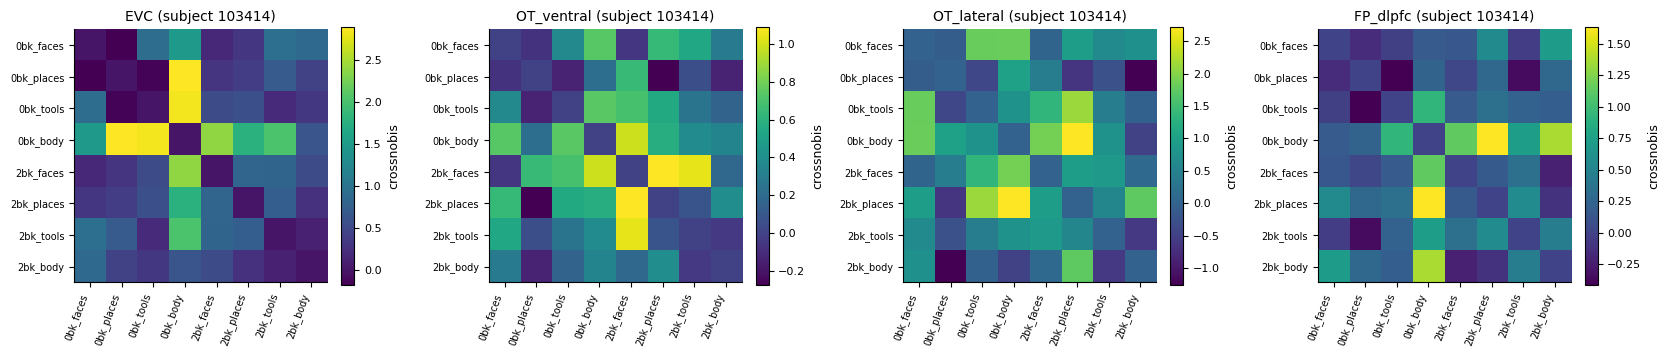

In [9]:
# ============ STEP 4: split-half RSA on the WM (visual) task ============
import matplotlib.pyplot as plt

rows = []
for sid in SUBJECTS:
    P = np.load(os.path.join(OUT_DIR, f"{sid}_patterns.npz"))
    for roi, m in roi_masks.items():
        A, B = P["WM_LR_t"][:, m].astype(float), P["WM_RL_t"][:, m].astype(float)
        keep = (A.std(0) > 0) & (B.std(0) > 0)                      # drop flat features
        A, B = A[:, keep], B[:, keep]
        w0, w2, xl = id_scores(A, B)
        rows.append(dict(subject=sid, roi=roi, n_feat=A.shape[1], id_0back=w0, id_2back=w2, id_cross_load=xl))
wm_res = pd.DataFrame(rows)
print("Pairwise identification accuracy (chance 0.50)")
print(wm_res.round(2).to_string(index=False))

# ---- group statistics (only meaningful with enough subjects) ----
if len(SUBJECTS) >= 5:
    out = []
    for roi, g in wm_res.groupby("roi"):
        for metric in ("id_0back", "id_2back", "id_cross_load"):
            x = g[metric].values - 0.5
            lo, hi = bootstrap_ci(x)
            out.append(dict(roi=roi, metric=metric, mean_acc=0.5 + x.mean(), ci_lo=0.5 + lo, ci_hi=0.5 + hi, p=signflip_p(x)))
    wm_group = pd.DataFrame(out)
    wm_group["q_fdr"] = bh_fdr(wm_group["p"].values)          # restrict this family to the pre-specified ROIs before reporting
    print("\nGroup level (sign-flip test vs chance, BH-FDR):")
    print(wm_group.round(3).to_string(index=False))
else:
    print(f"\n{len(SUBJECTS)} subject(s): descriptive only. A single subject cannot support a hypothesis test.")

# ---- RDMs and voxel-removal curves for the first subject ----
sid = SUBJECTS[0]
P = np.load(os.path.join(OUT_DIR, f"{sid}_patterns.npz"))
show = [r for r in ("EVC", "OT_ventral", "OT_lateral", "FP_dlpfc") if r in roi_masks]
fig, axes = plt.subplots(1, len(show), figsize=(4.2 * len(show), 4))
for ax, roi in zip(np.atleast_1d(axes), show):
    m = roi_masks[roi]
    A, B = P["WM_LR_t"][:, m].astype(float), P["WM_RL_t"][:, m].astype(float)
    im = ax.imshow(crossnobis_rdm(A, B), cmap="viridis")
    ax.set_title(f"{roi} (subject {sid})")
    ax.set_xticks(range(8)); ax.set_xticklabels(WM_CONDS, rotation=70, ha="right", fontsize=7)
    ax.set_yticks(range(8)); ax.set_yticklabels(WM_CONDS, fontsize=7)
    plt.colorbar(im, ax=ax, fraction=0.046, label="crossnobis")
plt.tight_layout(); plt.show()

# (Voxel-removal curves live in the Haxby cell and in the 'removal panels' cell, which use more random draws and all subjects.)


### RSA plots with per-subject values
These show the actual per-subject numbers behind the group means (the old confidence intervals were over only 5 values), the cross-run matrices that identification is built from, and a positive control that the ROI masks sit where the activation is.

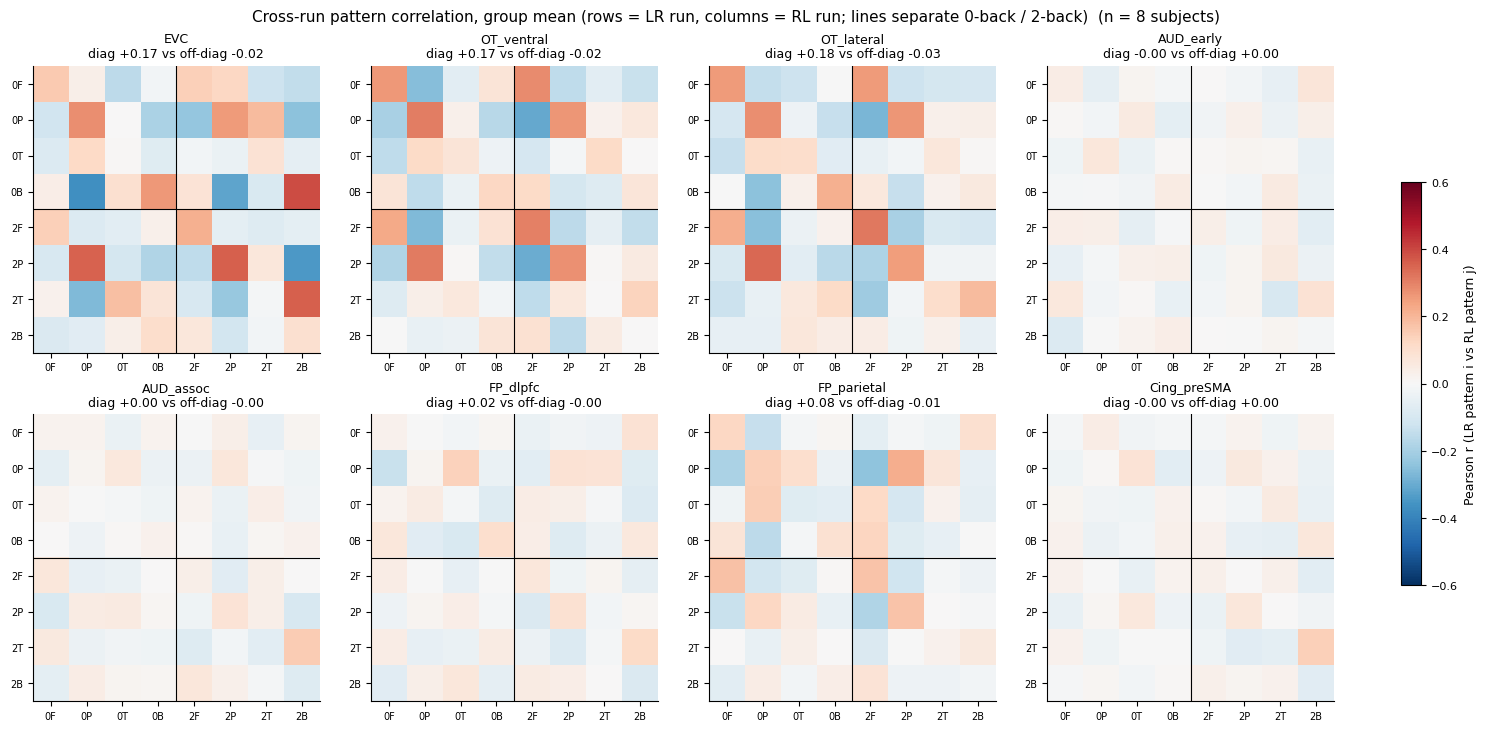

saved derivatives/figures/rsa_cross_run_matrices.png


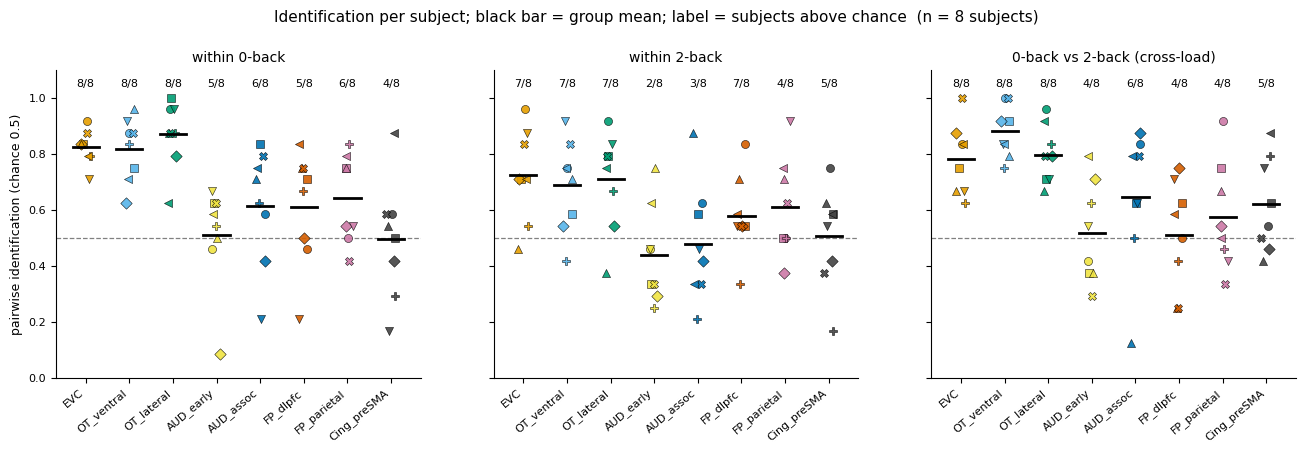

saved derivatives/figures/rsa_identification_strip.png


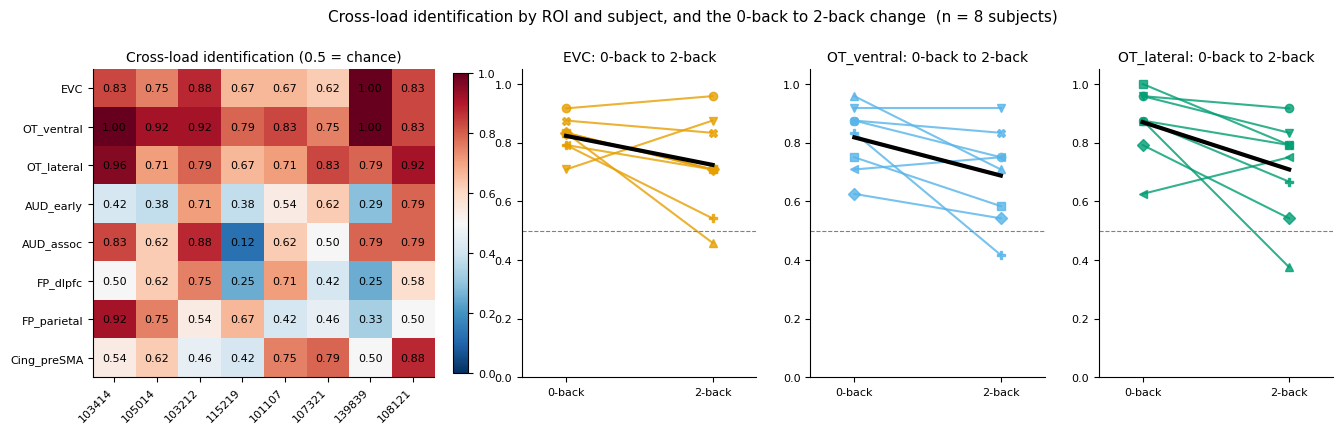

saved derivatives/figures/rsa_identification_heatmap_paired.png


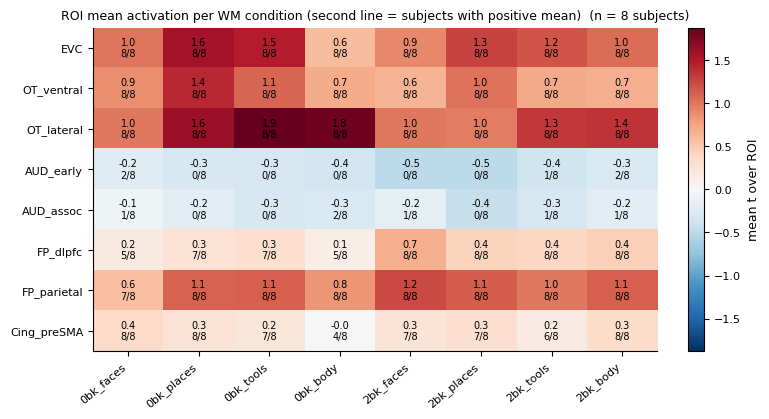

saved derivatives/figures/roi_mean_activation_positive_control.png


In [10]:
# ============ RSA PLOTS: cross-run matrices, identification per subject, ROI activation check ============
# Needs wm_res (cell 14), cross_run_corr (cell 13) and the style cell. These replace "mean +/- CI over 5 values" with the five actual values.
PAT = {sid: load_patterns(sid) for sid in SUBJECTS}

# ---- 1. Cross-run correlation matrices (group mean). Diagonal vs off-diagonal is what identification measures. ----
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), constrained_layout=True)
for ax, roi in zip(axes.ravel(), ROI_ORDER):
    mats = []
    for sid in SUBJECTS:
        A, B = nonflat_pair(PAT[sid]["WM_LR_t"][:, roi_masks[roi]].astype(float), PAT[sid]["WM_RL_t"][:, roi_masks[roi]].astype(float))
        mats.append(cross_run_corr(A, B))
    M = np.mean(mats, axis=0)
    im = ax.imshow(M, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
    ax.axhline(3.5, color="k", lw=.8); ax.axvline(3.5, color="k", lw=.8)
    diag, off = np.mean(np.diag(M)), np.mean(M[~np.eye(8, dtype=bool)])
    ax.set_title(f"{roi}\ndiag {diag:+.2f} vs off-diag {off:+.2f}", fontsize=9)
    ax.set_xticks(range(8)); ax.set_xticklabels(SHORT_CONDS, fontsize=7); ax.set_yticks(range(8)); ax.set_yticklabels(SHORT_CONDS, fontsize=7)
fig.colorbar(im, ax=axes, fraction=0.015, label="Pearson r (LR pattern i vs RL pattern j)")
fig.suptitle(n_title("Cross-run pattern correlation, group mean (rows = LR run, columns = RL run; lines separate 0-back / 2-back)"), fontsize=11)
save_fig(fig, "rsa_cross_run_matrices.png")

# ---- 2. Identification: one dot per subject, group mean, chance line, count above chance ----
metrics = [("id_0back", "within 0-back"), ("id_2back", "within 2-back"), ("id_cross_load", "0-back vs 2-back (cross-load)")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (col, label) in zip(axes, metrics):
    for i, roi in enumerate(ROI_ORDER):
        g = wm_res[wm_res.roi == roi].set_index("subject").loc[SUBJECTS]
        x = np.full(len(g), i) + jit(len(g), seed=i)
        for xx, (sid, v) in zip(x, g[col].items()):
            ax.scatter(xx, v, s=34, marker=SUBJ_MARKERS[sid], color=ROI_COLORS[roi], edgecolor="k", lw=.4, alpha=.9, zorder=3)
        ax.plot([i - .3, i + .3], [g[col].mean()] * 2, color="k", lw=2, zorder=4)
        ax.text(i, 1.04, f"{int((g[col] > .5).sum())}/{len(g)}", ha="center", fontsize=8)
    ax.axhline(.5, color="gray", ls="--", lw=.9)
    ax.set_xticks(range(len(ROI_ORDER))); ax.set_xticklabels(ROI_ORDER, rotation=40, ha="right")
    ax.set_title(label); ax.set_ylim(0, 1.1)
axes[0].set_ylabel("pairwise identification (chance 0.5)")
fig.suptitle(n_title("Identification per subject; black bar = group mean; label = subjects above chance"), fontsize=11, y=1.03)
save_fig(fig, "rsa_identification_strip.png")

# ---- 3. ROI x subject heatmap of cross-load identification, and paired load lines for the visual ROIs ----
fig = plt.figure(figsize=(16, 4))
gs = fig.add_gridspec(1, 1 + max(1, len(VISUAL_ROIS)), width_ratios=[1.6] + [1] * max(1, len(VISUAL_ROIS)))
ax = fig.add_subplot(gs[0])
H = wm_res.pivot(index="roi", columns="subject", values="id_cross_load").loc[ROI_ORDER, SUBJECTS]
im = ax.imshow(H.values, cmap="RdBu_r", vmin=0, vmax=1, aspect="auto")
for (i, j), v in np.ndenumerate(H.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="k")
ax.set_xticks(range(len(SUBJECTS))); ax.set_xticklabels(SUBJECTS, rotation=45, ha="right"); ax.set_yticks(range(len(ROI_ORDER))); ax.set_yticklabels(ROI_ORDER)
ax.set_title("Cross-load identification (0.5 = chance)"); fig.colorbar(im, ax=ax, fraction=0.04)
for k, roi in enumerate(VISUAL_ROIS):
    ax = fig.add_subplot(gs[1 + k])
    g = wm_res[wm_res.roi == roi].set_index("subject").loc[SUBJECTS]
    for sid, row in g.iterrows():
        ax.plot([0, 1], [row.id_0back, row.id_2back], marker=SUBJ_MARKERS[sid], color=ROI_COLORS[roi], alpha=.8, label=sid)
    ax.plot([0, 1], [g.id_0back.mean(), g.id_2back.mean()], "k-", lw=3)
    ax.axhline(.5, color="gray", ls="--", lw=.8); ax.set_xticks([0, 1]); ax.set_xticklabels(["0-back", "2-back"]); ax.set_ylim(0, 1.05); ax.set_xlim(-.3, 1.3)
    ax.set_title(f"{roi}: 0-back to 2-back")
fig.suptitle(n_title("Cross-load identification by ROI and subject, and the 0-back to 2-back change"), fontsize=11, y=1.03)
save_fig(fig, "rsa_identification_heatmap_paired.png")

# ---- 4. Positive control: mean activation of every ROI for each WM condition (t-values, averaged over ROI grayordinates) ----
act = np.zeros((len(SUBJECTS), len(ROI_ORDER), 8))
for si, sid in enumerate(SUBJECTS):
    for ri, roi in enumerate(ROI_ORDER):
        m = roi_masks[roi]
        act[si, ri] = 0.5 * (PAT[sid]["WM_LR_t"][:, m].mean(axis=1) + PAT[sid]["WM_RL_t"][:, m].mean(axis=1))
G = act.mean(axis=0)
fig, ax = plt.subplots(figsize=(8, 4.2))
lim = np.nanmax(np.abs(G))
im = ax.imshow(G, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for (i, j), v in np.ndenumerate(G):
    n_pos = int((act[:, i, j] > 0).sum())
    ax.text(j, i, f"{v:.1f}\n{n_pos}/{len(SUBJECTS)}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(8)); ax.set_xticklabels(WM_CONDS, rotation=40, ha="right"); ax.set_yticks(range(len(ROI_ORDER))); ax.set_yticklabels(ROI_ORDER)
fig.colorbar(im, ax=ax, fraction=0.04, label="mean t over ROI")
ax.set_title(n_title("ROI mean activation per WM condition (second line = subjects with positive mean)"), fontsize=9)
save_fig(fig, "roi_mean_activation_positive_control.png")


In [11]:
# ============ STEP 5: split-half RSA on the Language (auditory) task ============
lrows = []
for sid in SUBJECTS:
    P = np.load(os.path.join(OUT_DIR, f"{sid}_patterns.npz"))
    for roi, m in roi_masks.items():
        r, d = language_split_half(P["LANGUAGE_LR_t"][:, m].astype(float), P["LANGUAGE_RL_t"][:, m].astype(float))
        lrows.append(dict(subject=sid, roi=roi, n_feat=int(m.sum()), story_math_r=r, crossnobis_d=d))
lang_res = pd.DataFrame(lrows)
print("Story-vs-math pattern reliability across runs (r) and cross-validated distance")
print(lang_res.round(3).to_string(index=False))

if len(SUBJECTS) >= 5:
    out = []
    for roi, g in lang_res.groupby("roi"):
        z = np.arctanh(np.clip(g["story_math_r"].values, -0.999, 0.999))      # Fisher z before averaging r
        lo, hi = bootstrap_ci(z)
        out.append(dict(roi=roi, mean_r=np.tanh(z.mean()), ci_lo=np.tanh(lo), ci_hi=np.tanh(hi), p=signflip_p(z)))
    lang_group = pd.DataFrame(out)
    lang_group["q_fdr"] = bh_fdr(lang_group["p"].values)
    print("\nGroup level:"); print(lang_group.round(3).to_string(index=False))
else:
    print(f"\n{len(SUBJECTS)} subject(s): descriptive only.")


Story-vs-math pattern reliability across runs (r) and cross-validated distance
subject         roi  n_feat  story_math_r  crossnobis_d
 103414         EVC    3632         0.528         0.226
 103414  OT_ventral    1850         0.295         0.074
 103414  OT_lateral     788         0.629         0.283
 103414   AUD_early    1187         0.352         0.105
 103414   AUD_assoc    2274         0.664         0.584
 103414    FP_dlpfc    3318         0.611         0.607
 103414 FP_parietal    2460         0.776         1.531
 103414 Cing_preSMA    1547         0.591         0.344
 105014         EVC    3632         0.596         0.252
 105014  OT_ventral    1850         0.385         0.095
 105014  OT_lateral     788         0.569         0.206
 105014   AUD_early    1187         0.455         0.112
 105014   AUD_assoc    2274         0.817         1.481
 105014    FP_dlpfc    3318         0.782         0.942
 105014 FP_parietal    2460         0.690         1.536
 105014 Cing_preSMA    15

## MVPA decoding (leave-one-subject-out)

Needs the cells above to have run for **at least 5 subjects** (set `SUBJECTS` in the Patterns cell), because the decoder is trained on other subjects' brains and tested on the held-out one.

1. **Dataset**: per-subject preprocessing from the saved patterns. For category decoding the 4-category mean inside each run and load is removed, so the classifier cannot use load; for load decoding only the subject mean is removed. Features are scaled within each subject, so nothing is learned from other subjects' labels.
2. **Decoder**: linear ridge classifier, with the whole leave-one-subject-out analysis repeated under shuffled labels for the p-values.
3. **WM run**: category within 0-back, within 2-back, trained on 0-back and tested on 2-back (and the reverse), and load, in every ROI.
4. **Language run**: story vs math in every ROI.

Notes: p-values come from label permutation, not from a t-test or sign-flip across subjects' accuracies, because those accuracies share training data and the test is too liberal (it rejected 10-13% of null datasets at alpha = 0.05 in my checks). `N_PERM` must be large enough that the smallest possible q can pass: with 40 tests you need `N_PERM` of at least 1000, and 5000 for final numbers. `LAM_REL` is fixed in advance; report how results change at 0.1 and 10 rather than picking the best.


In [12]:
# ============ DECODING, STEP 1: build the cross-subject dataset ============
# Reads derivatives/<subject>_patterns.npz (cell S1) and the ROI masks (cell S2). Needs >= MIN_SUBJ subjects:
# decoding is trained on other subjects' brains, so one pilot subject cannot be decoded.
# Grayordinates are MSMAll-aligned, so the same ROI feature means the same cortical location in every subject.
# ---- quick check that cells S1 and S2 worked on this machine ----
# ============ VALIDATE PATTERN FILES FOR MVPA ============

import os
import numpy as np

MIN_SUBJ = 5

assert len(SUBJECTS) >= MIN_SUBJ, (
    f"MVPA requires at least {MIN_SUBJ} subjects; found {len(SUBJECTS)}."
)

EXPECTED_SHAPES = {
    "WM_LR_t": (8, 91282),
    "WM_RL_t": (8, 91282),
    "LANGUAGE_LR_t": (2, 91282),
    "LANGUAGE_RL_t": (2, 91282),
}

# First verify the files exist and contain all required arrays.
pattern_files = {}

for sid in SUBJECTS:
    path = os.path.join(OUT_DIR, f"{sid}_patterns.npz")

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Missing pattern file for subject {sid}: {path}\n"
            "Run Cell 8 after correcting DATA_ROOT."
        )

    with np.load(path) as P:
        missing = [key for key in EXPECTED_SHAPES if key not in P.files]
        if missing:
            raise KeyError(f"{sid}: missing arrays {missing} in {path}")

        for key, expected_shape in EXPECTED_SHAPES.items():
            actual_shape = P[key].shape

            # The expected grayordinate count may differ if your data use
            # a different space; all subjects must nevertheless match.
            if actual_shape != expected_shape:
                print(
                    f"Shape note: {sid} {key}: {actual_shape}; "
                    f"reference shape: {expected_shape}"
                )

            if actual_shape[0] != expected_shape[0]:
                raise ValueError(
                    f"{sid} {key}: expected {expected_shape[0]} conditions, "
                    f"found {actual_shape[0]}."
                )

            if not np.isfinite(P[key]).all():
                raise ValueError(f"{sid} {key} contains NaN or infinite values.")

    pattern_files[sid] = path
    print(f"Validated: {sid} -> {path}")

# Require a common feature space across subjects.
feature_counts = set()

for sid, path in pattern_files.items():
    with np.load(path) as P:
        feature_counts.update(
            P[key].shape[1] for key in EXPECTED_SHAPES
        )

if len(feature_counts) != 1:
    raise ValueError(
        f"Subjects have inconsistent feature counts: {feature_counts}. "
        "Check that all patterns use the same grayordinate space."
    )

N_FEATURES = feature_counts.pop()

assert all(
    mask.shape[0] == N_FEATURES for mask in roi_masks.values()
), "ROI masks do not match the pattern feature space."

print(f"\nValidated {len(pattern_files)} subjects and {N_FEATURES} features.")

LOAD_OF_ROW = np.repeat([0, 1], 4)        # WM rows: 0-3 = 0-back, 4-7 = 2-back
CAT_OF_ROW = np.tile(np.arange(4), 2)     # faces, places, tools, body at both loads


def _scale(X):
    """Per-subject feature scaling (uses only that subject's own unlabeled samples, so nothing leaks across subjects)."""
    sd = X.std(axis=0)
    return np.where(sd > 0, X / np.where(sd > 0, sd, 1.0), 0.0)


def prep_category(runs):
    """runs: [LR (8,F), RL (8,F)]. Remove the 4-category mean inside each run and load (kills the shared task pattern
    and the load main effect, so category classifiers cannot use load), then scale features."""
    out = []
    for P in runs:
        P = np.asarray(P, float).copy()
        for rows in (np.arange(0, 4), np.arange(4, 8)):
            P[rows] -= P[rows].mean(axis=0, keepdims=True)
        out.append(P)
    return _scale(np.vstack(out))


def prep_load(runs):
    """Keep the load difference: subtract this subject's mean over all 16 samples, then scale features."""
    X = np.vstack([np.asarray(P, float) for P in runs])
    return _scale(X - X.mean(axis=0, keepdims=True))


def prep_language(runs):
    """runs: [LR (2,F), RL (2,F)] story/math. Remove the story/math mean inside each run, then scale features."""
    out = []
    for P in runs:
        P = np.asarray(P, float)
        out.append(P - P.mean(axis=0, keepdims=True))
    return _scale(np.vstack(out))


def build_dataset(roi, task):
    """Build a cross-subject decoding dataset from all configured subjects."""
    if roi not in roi_masks:
        raise KeyError(f"Unknown ROI: {roi}")

    if task not in ("WM", "LANGUAGE"):
        raise ValueError("task must be 'WM' or 'LANGUAGE'")

    mask = roi_masks[roi]
    Xs, meta = [], []

    for subject_index, sid in enumerate(SUBJECTS):
        path = os.path.join(OUT_DIR, f"{sid}_patterns.npz")

        if not os.path.isfile(path):
            raise FileNotFoundError(
                f"Missing {path}. Run pattern extraction for subject {sid}."
            )

        with np.load(path) as P:
            lr_key = f"{task}_LR_t"
            rl_key = f"{task}_RL_t"

            for key in (lr_key, rl_key):
                if key not in P.files:
                    raise KeyError(f"{sid}: {key} is missing from {path}")

            lr = P[lr_key].astype(np.float64)
            rl = P[rl_key].astype(np.float64)

        expected_rows = 8 if task == "WM" else 2

        if lr.shape[0] != expected_rows or rl.shape[0] != expected_rows:
            raise ValueError(
                f"{sid} {task}: unexpected LR/RL shapes "
                f"{lr.shape} and {rl.shape}"
            )

        if lr.shape[1] != mask.size or rl.shape[1] != mask.size:
            raise ValueError(
                f"{sid} {task}: pattern features do not match ROI mask."
            )

        if not np.isfinite(lr).all() or not np.isfinite(rl).all():
            raise ValueError(f"{sid} {task}: patterns contain non-finite values.")

        runs = [lr[:, mask], rl[:, mask]]

        if task == "WM":
            X_category = prep_category(runs)
            X_load = prep_load(runs)
            Xs.append((X_category, X_load))

            for run_index in (0, 1):
                for k in range(8):
                    meta.append((
                        subject_index,
                        sid,
                        run_index,
                        LOAD_OF_ROW[k],
                        CAT_OF_ROW[k],
                    ))

        else:
            X_language = prep_language(runs)
            Xs.append((X_language, None))

            for run_index in (0, 1):
                for category in (0, 1):
                    meta.append((
                        subject_index,
                        sid,
                        run_index,
                        0,
                        category,
                    ))

    meta = np.asarray(meta, dtype=object)

    result = {
        "subj": meta[:, 0].astype(int),
        "subject_id": meta[:, 1],
        "run": meta[:, 2].astype(int),
        "load": meta[:, 3].astype(int),
        "y": meta[:, 4].astype(int),
        "X_main": np.vstack([x[0] for x in Xs]),
    }

    if task == "WM":
        result["X_load"] = np.vstack([x[1] for x in Xs])

    print(
        f"{task} / {roi}: {len(SUBJECTS)} subjects, "
        f"{result['X_main'].shape[0]} samples, "
        f"{result['X_main'].shape[1]} ROI features"
    )

    return result


print(f"{len(SUBJECTS)} subjects; building decoding datasets for {len(roi_masks)} ROIs")


Validated: 103414 -> derivatives/103414_patterns.npz
Validated: 105014 -> derivatives/105014_patterns.npz
Validated: 103212 -> derivatives/103212_patterns.npz
Validated: 115219 -> derivatives/115219_patterns.npz
Validated: 101107 -> derivatives/101107_patterns.npz
Validated: 107321 -> derivatives/107321_patterns.npz
Validated: 139839 -> derivatives/139839_patterns.npz
Validated: 108121 -> derivatives/108121_patterns.npz

Validated 8 subjects and 91282 features.
8 subjects; building decoding datasets for 8 ROIs


In [13]:
# ============ DECODING, STEP 2: linear decoder, leave-one-subject-out analyses, permutation test ============
# Decoder: linear ridge classifier in dual form (one-vs-rest, +/- coded labels), strong L2 because features >> samples.
# The kernel K = X X^T is computed once per ROI, and each fold's eigendecomposition once per analysis, so the
# label-permutation test (which repeats the WHOLE leave-one-subject-out analysis) takes seconds, not hours.
LAM_REL = 1.0      # ridge strength relative to the mean kernel diagonal. Fixed in advance; report a sensitivity check, do not tune on test accuracy.


class LosoModel:
    """Leave-one-subject-out ridge decoder. For each held-out subject: train on all OTHER subjects' samples in
    train_sel, test on the held-out subject's samples in test_sel."""

    def __init__(self, K, subj, train_sel, test_sel, lam_rel=LAM_REL):
        self.folds = []
        for s in np.unique(subj):
            tr = np.where((subj != s) & train_sel)[0]
            te = np.where((subj == s) & test_sel)[0]
            Ktr = K[np.ix_(tr, tr)]
            lam = lam_rel * np.trace(Ktr) / len(tr)
            w, U = np.linalg.eigh(Ktr)
            self.folds.append((tr, te, U, 1.0 / (np.maximum(w, 0) + lam), K[np.ix_(te, tr)]))

    def accuracy(self, y):
        """One accuracy per held-out subject. y: integer labels 0..k-1 for ALL samples (may be permuted)."""
        k = int(y.max()) + 1
        Y = np.eye(k)[y] - 1.0 / k
        out = []
        for tr, te, U, inv, Kte in self.folds:
            alpha = U @ (inv[:, None] * (U.T @ Y[tr]))
            out.append(np.mean((Kte @ alpha).argmax(axis=1) == y[te]))
        return np.array(out)


def wm_analyses(d):
    """The five WM questions: {name: (K, y, subj, train_sel, test_sel, chance, permutation_groups)}.
    Category labels are shuffled within subject x run x load; load labels within subject x run x category,
    so every permutation keeps the design balance."""
    Kc, Kl = d["X_main"] @ d["X_main"].T, d["X_load"] @ d["X_load"].T
    L, y_c, s, r = d["load"], d["y"], d["subj"], d["run"]
    allsel = np.ones(len(y_c), bool)
    gcat = s * 100 + r * 10 + L
    gload = s * 100 + r * 10 + y_c
    return {
        "category | 0-back -> 0-back": (Kc, y_c, s, L == 0, L == 0, 0.25, gcat),
        "category | 2-back -> 2-back": (Kc, y_c, s, L == 1, L == 1, 0.25, gcat),
        "category | 0-back -> 2-back": (Kc, y_c, s, L == 0, L == 1, 0.25, gcat),
        "category | 2-back -> 0-back": (Kc, y_c, s, L == 1, L == 0, 0.25, gcat),
        "load (0- vs 2-back)":         (Kl, L,   s, allsel, allsel, 0.50, gload),
    }


def permutation_test(model, y, groups, n_perm=1000, seed=0):
    """Label-permutation test of the group-mean leave-one-subject-out accuracy: shuffle labels inside the blocks given by
    `groups`, repeat the whole analysis, p = share of permutations with accuracy >= observed.
    Valid despite the folds sharing training data (the t-test / sign-flip on per-subject accuracies is not)."""
    rng = np.random.default_rng(seed)
    blocks = [np.where(groups == g)[0] for g in np.unique(groups)]
    obs = model.accuracy(y).mean()
    null = np.empty(n_perm)
    for i in range(n_perm):
        yp = y.copy()
        for idx in blocks:
            yp[idx] = y[rng.permutation(idx)]
        null[i] = model.accuracy(yp).mean()
    return obs, null, (1 + np.sum(null >= obs)) / (n_perm + 1)


WM / EVC: 8 subjects, 128 samples, 3632 ROI features
WM / OT_ventral: 8 subjects, 128 samples, 1850 ROI features
WM / OT_lateral: 8 subjects, 128 samples, 788 ROI features
WM / AUD_early: 8 subjects, 128 samples, 1187 ROI features
WM / AUD_assoc: 8 subjects, 128 samples, 2274 ROI features
WM / FP_dlpfc: 8 subjects, 128 samples, 3318 ROI features
WM / FP_parietal: 8 subjects, 128 samples, 2460 ROI features
WM / Cing_preSMA: 8 subjects, 128 samples, 1547 ROI features
Leave-one-subject-out decoding. p_perm = label-permutation test; CI = bootstrap over subjects (descriptive, slightly optimistic)
        roi                    analysis  chance  mean_acc  ci_lo  ci_hi  p_perm  q_fdr
        EVC category | 0-back -> 0-back    0.25     0.812  0.703  0.906   0.001  0.002
        EVC category | 2-back -> 2-back    0.25     0.719  0.562  0.859   0.001  0.002
        EVC category | 0-back -> 2-back    0.25     0.562  0.406  0.688   0.001  0.002
        EVC category | 2-back -> 0-back    0.25     0

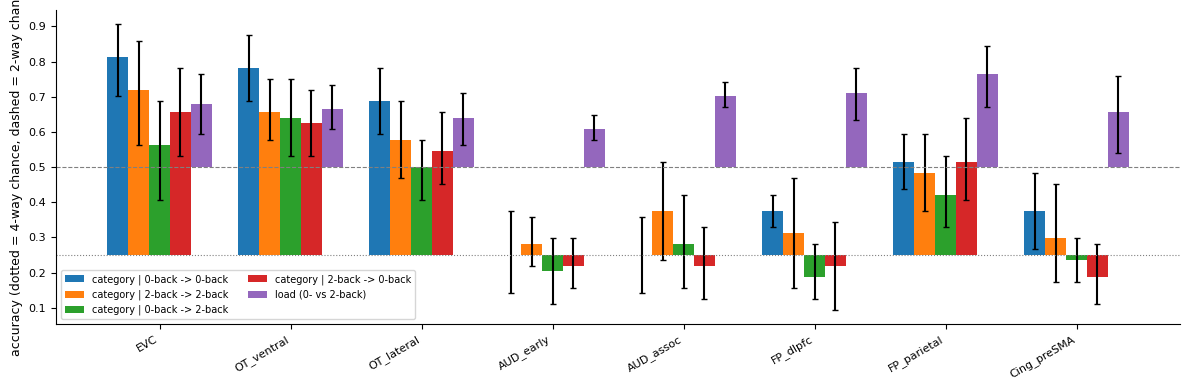

In [14]:
# ============ DECODING, STEP 3: run the WM (visual) decoders over all ROIs ============
import matplotlib.pyplot as plt

N_PERM = 1000       # permutations per test. 1000 is fine to look; use 5000+ for the final numbers (smallest possible p is 1/(N_PERM+1))
rows, subj_acc = [], {}
for roi in roi_masks:
    d = build_dataset(roi, "WM")
    for name, (K, y, s, tr, te, chance, groups) in wm_analyses(d).items():
        model = LosoModel(K, s, tr, te)
        _, _, p = permutation_test(model, y, groups, N_PERM)
        a = model.accuracy(y)
        subj_acc[(roi, name)] = a
        lo, hi = bootstrap_ci(a - chance)
        rows.append(dict(roi=roi, analysis=name, chance=chance, mean_acc=a.mean(), ci_lo=chance + lo, ci_hi=chance + hi, p_perm=p))
wm_dec = pd.DataFrame(rows)
wm_dec["q_fdr"] = bh_fdr(wm_dec["p_perm"].values)         # across every ROI x analysis shown; restrict to your pre-specified family before reporting
print("Leave-one-subject-out decoding. p_perm = label-permutation test; CI = bootstrap over subjects (descriptive, slightly optimistic)")
print(wm_dec.round(3).to_string(index=False))

# does category information survive the 0-back <-> 2-back change? (descriptive: no valid label-permutation null for this difference)
within = lambda r: np.mean([subj_acc[(r, "category | 0-back -> 0-back")], subj_acc[(r, "category | 2-back -> 2-back")]], axis=0)
across = lambda r: np.mean([subj_acc[(r, "category | 0-back -> 2-back")], subj_acc[(r, "category | 2-back -> 0-back")]], axis=0)
print("\nCategory decoding: within-load minus cross-load accuracy (0 = load-invariant; > 0 = information lost across load)")
for r in roi_masks:
    dlt = within(r) - across(r)
    lo, hi = bootstrap_ci(dlt)
    print(f"  {r:12s} mean {dlt.mean():+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]")

fig, ax = plt.subplots(figsize=(12, 4))
names, w = list(wm_dec.analysis.unique()), 0.16
for k, nm in enumerate(names):
    sub = wm_dec[wm_dec.analysis == nm].set_index("roi").loc[list(roi_masks)]
    ax.bar(np.arange(len(roi_masks)) + (k - 2) * w, sub.mean_acc - sub.chance, w, bottom=sub.chance, label=nm,
           yerr=[sub.mean_acc - sub.ci_lo, sub.ci_hi - sub.mean_acc], capsize=2)
ax.axhline(0.25, color="gray", lw=0.8, ls=":"); ax.axhline(0.5, color="gray", lw=0.8, ls="--")
ax.set_xticks(range(len(roi_masks))); ax.set_xticklabels(list(roi_masks), rotation=30, ha="right")
ax.set_ylabel("accuracy (dotted = 4-way chance, dashed = 2-way chance)"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()


In [15]:
# ============ DECODING, STEP 4: story vs math (auditory Language task), leave-one-subject-out ============
# Each run contributes a story and a math pattern that are mirror images after centring, so a subject has
# effectively two independent test observations (LR, RL); the permutation test accounts for this.
lrows = []
for roi in roi_masks:
    d = build_dataset(roi, "LANGUAGE")
    K = d["X_main"] @ d["X_main"].T
    all_s = np.ones(len(d["y"]), bool)
    model = LosoModel(K, d["subj"], all_s, all_s)
    groups = d["subj"] * 10 + d["run"]
    _, _, p = permutation_test(model, d["y"], groups, N_PERM)
    a = model.accuracy(d["y"])
    lo, hi = bootstrap_ci(a - 0.5)
    lrows.append(dict(roi=roi, mean_acc=a.mean(), ci_lo=0.5 + lo, ci_hi=0.5 + hi, p_perm=p))
lang_dec = pd.DataFrame(lrows)
lang_dec["q_fdr"] = bh_fdr(lang_dec["p_perm"].values)
print("Story vs math decoding (chance 0.50)")
print(lang_dec.round(3).to_string(index=False))


LANGUAGE / EVC: 8 subjects, 32 samples, 3632 ROI features
LANGUAGE / OT_ventral: 8 subjects, 32 samples, 1850 ROI features
LANGUAGE / OT_lateral: 8 subjects, 32 samples, 788 ROI features
LANGUAGE / AUD_early: 8 subjects, 32 samples, 1187 ROI features
LANGUAGE / AUD_assoc: 8 subjects, 32 samples, 2274 ROI features
LANGUAGE / FP_dlpfc: 8 subjects, 32 samples, 3318 ROI features
LANGUAGE / FP_parietal: 8 subjects, 32 samples, 2460 ROI features
LANGUAGE / Cing_preSMA: 8 subjects, 32 samples, 1547 ROI features
Story vs math decoding (chance 0.50)
        roi  mean_acc  ci_lo  ci_hi  p_perm  q_fdr
        EVC     0.750  0.375    1.0   0.084  0.084
 OT_ventral     1.000  1.000    1.0   0.001  0.002
 OT_lateral     0.938  0.812    1.0   0.003  0.003
  AUD_early     0.938  0.812    1.0   0.002  0.003
  AUD_assoc     1.000  1.000    1.0   0.001  0.002
   FP_dlpfc     1.000  1.000    1.0   0.001  0.002
FP_parietal     1.000  1.000    1.0   0.001  0.002
Cing_preSMA     0.938  0.812    1.0   0.001  

### Decoding plots
Per-subject accuracies with the permutation-null band, confusion matrices (which categories are confused), and a check of whether load decoding reflects the multi-voxel pattern or just a stronger average response.

WM / EVC: 8 subjects, 128 samples, 3632 ROI features
WM / OT_ventral: 8 subjects, 128 samples, 1850 ROI features
WM / OT_lateral: 8 subjects, 128 samples, 788 ROI features
WM / AUD_early: 8 subjects, 128 samples, 1187 ROI features
WM / AUD_assoc: 8 subjects, 128 samples, 2274 ROI features
WM / FP_dlpfc: 8 subjects, 128 samples, 3318 ROI features
WM / FP_parietal: 8 subjects, 128 samples, 2460 ROI features
WM / Cing_preSMA: 8 subjects, 128 samples, 1547 ROI features


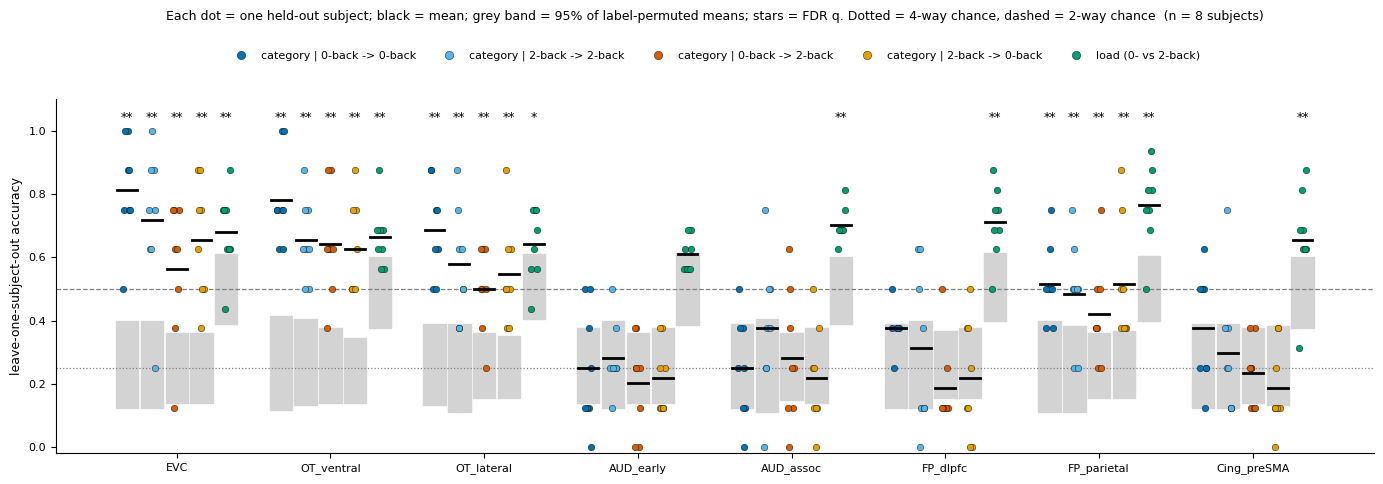

saved derivatives/figures/decoding_subject_dots_null_band.png


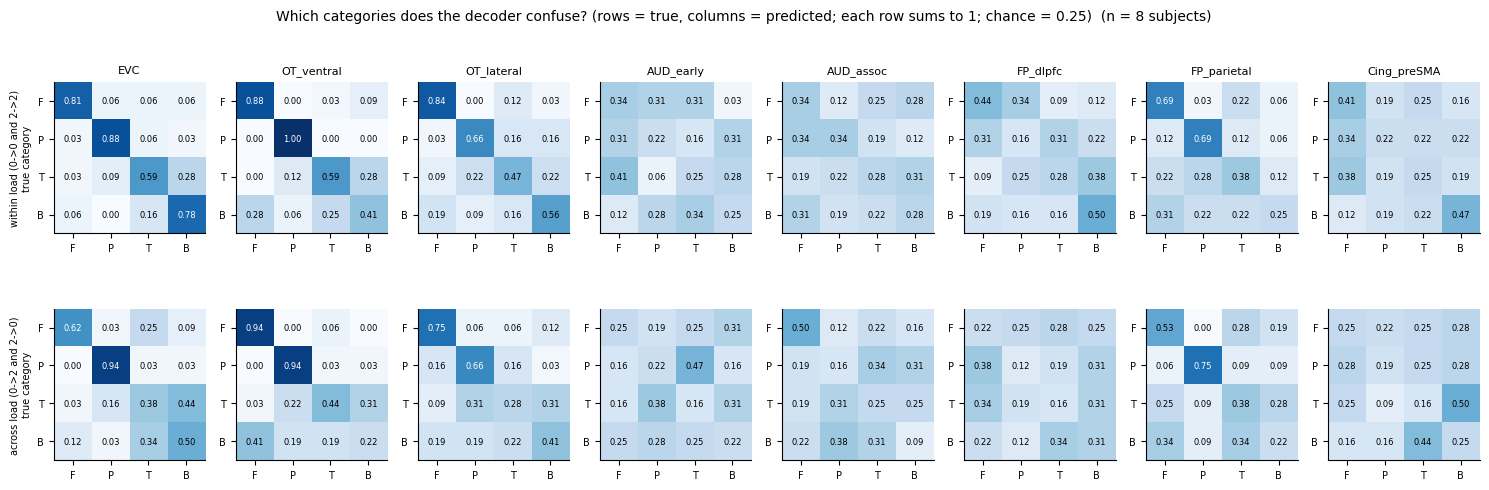

saved derivatives/figures/decoding_confusion_matrices.png


In [16]:
# ============ DECODING PLOTS: per-subject dots with a permutation-null band, and confusion matrices ============
# Needs wm_dec and subj_acc (cell 22), build_dataset / wm_analyses / LosoModel / permutation_test (cells 20-21) and the style cell.
PLOT_NPERM = 300        # permutations used only to draw the grey null band (cell 22 already holds the reported p-values)
ANALYSES = list(wm_dec.analysis.unique())
AN_COLORS = ["#0072B2", "#56B4E9", "#D55E00", "#E69F00", "#009E73"]
datasets, models, nulls = {}, {}, {}
for roi in ROI_ORDER:
    datasets[roi] = build_dataset(roi, "WM")
    for name, (K, y, s, tr, te, chance, groups) in wm_analyses(datasets[roi]).items():
        models[(roi, name)] = (LosoModel(K, s, tr, te), y)
        _, null, _ = permutation_test(models[(roi, name)][0], y, groups, PLOT_NPERM, seed=1)
        nulls[(roi, name)] = null

# ---- 1. Accuracy per held-out subject, group mean, null band, FDR stars ----
fig, ax = plt.subplots(figsize=(17, 4.6))
slot, gap = 1.0, 1.2
centers = {}
for ri, roi in enumerate(ROI_ORDER):
    for ai, name in enumerate(ANALYSES):
        x = ri * (len(ANALYSES) * slot + gap) + ai * slot
        centers[(roi, name)] = x
        chance = 0.5 if name.startswith("load") else 0.25
        null = nulls[(roi, name)]
        ax.fill_between([x - .45, x + .45], np.percentile(null, 2.5), np.percentile(null, 97.5), color="lightgray", zorder=1)
        acc = subj_acc[(roi, name)]
        ax.scatter(x + jit(len(acc), .15, seed=ai), acc, s=22, color=AN_COLORS[ai], edgecolor="k", lw=.3, zorder=3)
        ax.plot([x - .4, x + .4], [acc.mean()] * 2, color="k", lw=2, zorder=4)
        q = float(wm_dec[(wm_dec.roi == roi) & (wm_dec.analysis == name)].q_fdr.iloc[0])
        ax.text(x, 1.03, "***" if q < .001 else "**" if q < .01 else "*" if q < .05 else "", ha="center", fontsize=9)
for ai, name in enumerate(ANALYSES):
    ax.scatter([], [], color=AN_COLORS[ai], label=name, edgecolor="k", lw=.3)
ax.axhline(.25, color="gray", ls=":", lw=.9); ax.axhline(.5, color="gray", ls="--", lw=.9)
ax.set_xticks([np.mean([centers[(r, a)] for a in ANALYSES]) for r in ROI_ORDER]); ax.set_xticklabels(ROI_ORDER)
ax.set_ylim(-.02, 1.1); ax.set_ylabel("leave-one-subject-out accuracy")
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(.5, 1.08), frameon=False)
ax.set_title(n_title("Each dot = one held-out subject; black = mean; grey band = 95% of label-permuted means; stars = FDR q. Dotted = 4-way chance, dashed = 2-way chance"), fontsize=9, y=1.2)
save_fig(fig, "decoding_subject_dots_null_band.png")

# ---- 2. Confusion matrices for category decoding: pooled over held-out subjects ----
def predictions(model, y):
    k = int(y.max()) + 1
    Y = np.eye(k)[y] - 1.0 / k
    true, pred = [], []
    for tr, te, U, inv, Kte in model.folds:
        alpha = U @ (inv[:, None] * (U.T @ Y[tr]))
        pred.append((Kte @ alpha).argmax(axis=1)); true.append(y[te])
    return np.concatenate(true), np.concatenate(pred)

def conf(true, pred, k=4):
    M = np.zeros((k, k))
    for t, p in zip(true, pred):
        M[t, p] += 1
    return M / np.maximum(M.sum(axis=1, keepdims=True), 1)

rows = [("within load (0->0 and 2->2)", ["category | 0-back -> 0-back", "category | 2-back -> 2-back"]),
        ("across load (0->2 and 2->0)", ["category | 0-back -> 2-back", "category | 2-back -> 0-back"])]
fig, axes = plt.subplots(2, len(ROI_ORDER), figsize=(2.3 * len(ROI_ORDER), 5.4))
for r_i, (label, names) in enumerate(rows):
    for c_i, roi in enumerate(ROI_ORDER):
        T, Pd = [], []
        for nm in names:
            m, y = models[(roi, nm)]
            t, p = predictions(m, y); T.append(t); Pd.append(p)
        M = conf(np.concatenate(T), np.concatenate(Pd))
        ax = axes[r_i, c_i]
        im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
        for (i, j), v in np.ndenumerate(M):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="w" if v > .6 else "k")
        ax.set_xticks(range(4)); ax.set_xticklabels(["F", "P", "T", "B"], fontsize=7); ax.set_yticks(range(4)); ax.set_yticklabels(["F", "P", "T", "B"], fontsize=7)
        if r_i == 0:
            ax.set_title(roi, fontsize=8)
        if c_i == 0:
            ax.set_ylabel(label + "\ntrue category", fontsize=7)
fig.suptitle(n_title("Which categories does the decoder confuse? (rows = true, columns = predicted; each row sums to 1; chance = 0.25)"), fontsize=10)
save_fig(fig, "decoding_confusion_matrices.png")


Load decoding: full pattern vs pattern with ROI-mean removed, and the ROI-mean activation difference
        roi  acc_full  acc_pattern_only  p_pattern_only  null_95  mean_activation_diff  n_subjects_positive
        EVC     0.680             0.656           0.003    0.609                -0.060                    3
 OT_ventral     0.664             0.516           0.372    0.609                -0.255                    0
 OT_lateral     0.641             0.609           0.020    0.602                -0.415                    0
  AUD_early     0.609             0.578           0.106    0.606                -0.107                    1
  AUD_assoc     0.703             0.703           0.003    0.609                -0.067                    2
   FP_dlpfc     0.711             0.719           0.003    0.617                 0.264                    8
FP_parietal     0.766             0.789           0.003    0.602                 0.218                    7
Cing_preSMA     0.656             0

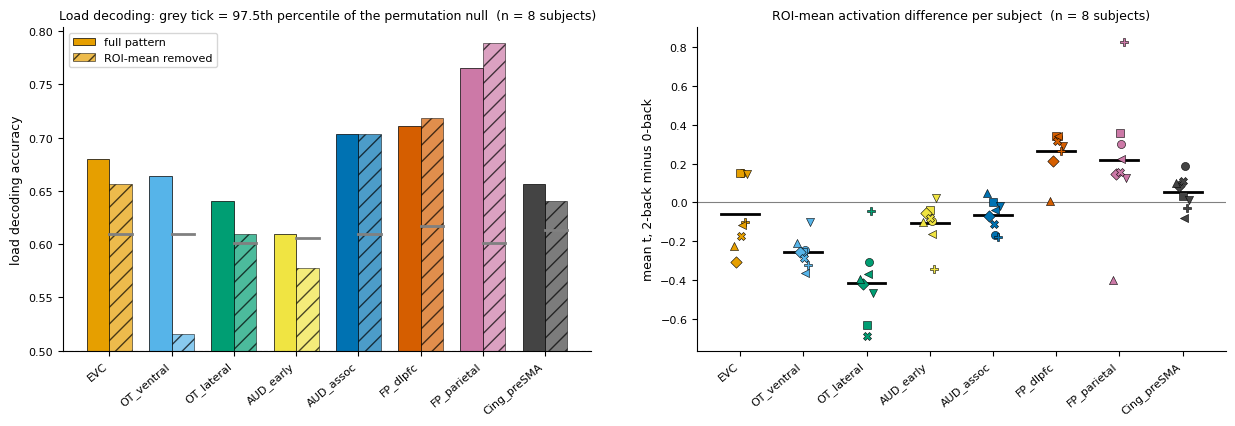

saved derivatives/figures/load_amplitude_vs_pattern.png


In [17]:
# ============ LOAD: AMPLITUDE OR PATTERN? ============
# FP_parietal decodes load at 0.73. Is that the pattern across grayordinates, or just a stronger average response under 2-back?
# Left: leave-one-subject-out load decoding with the full pattern vs with each sample's ROI-mean removed (pattern only).
# Right: the ROI-mean activation difference (2-back minus 0-back) per subject.
# Needs build_dataset / wm_analyses / LosoModel / permutation_test (cells 20-21), wm_dec (cell 22) and the style cell.
LOAD_NAME = "load (0- vs 2-back)"
amp_rows, amp_subject = [], {}
for roi in ROI_ORDER:
    d = datasets[roi] if "datasets" in globals() and roi in datasets else build_dataset(roi, "WM")
    K, y, s, tr, te, chance, groups = wm_analyses(d)[LOAD_NAME]
    full = LosoModel(K, s, tr, te).accuracy(y)
    Xp = d["X_load"] - d["X_load"].mean(axis=1, keepdims=True)                   # remove each sample's ROI-mean
    model_p = LosoModel(Xp @ Xp.T, s, tr, te)
    obs, null, p = permutation_test(model_p, y, groups, PLOT_NPERM if "PLOT_NPERM" in globals() else 300, seed=2)
    pat = model_p.accuracy(y)
    amp = np.array([np.mean([load_patterns(sid)[f"WM_{run}_t"][4:8][:, roi_masks[roi]].mean() - load_patterns(sid)[f"WM_{run}_t"][:4][:, roi_masks[roi]].mean()
                             for run in ("LR", "RL")]) for sid in SUBJECTS])
    amp_subject[roi] = amp
    amp_rows.append(dict(roi=roi, acc_full=full.mean(), acc_pattern_only=pat.mean(), p_pattern_only=p, null_95=np.percentile(null, 97.5),
                         mean_activation_diff=amp.mean(), n_subjects_positive=int((amp > 0).sum())))
amp_df = pd.DataFrame(amp_rows)
print("Load decoding: full pattern vs pattern with ROI-mean removed, and the ROI-mean activation difference")
print(amp_df.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
ax = axes[0]; w = .36
for i, roi in enumerate(ROI_ORDER):
    r = amp_df[amp_df.roi == roi].iloc[0]
    ax.bar(i - w / 2, r.acc_full - .5, w, bottom=.5, color=ROI_COLORS[roi], edgecolor="k", lw=.5, label="full pattern" if i == 0 else None)
    ax.bar(i + w / 2, r.acc_pattern_only - .5, w, bottom=.5, color=ROI_COLORS[roi], edgecolor="k", lw=.5, hatch="//", alpha=.7, label="ROI-mean removed" if i == 0 else None)
    ax.plot([i + w / 2 - .18, i + w / 2 + .18], [r.null_95] * 2, color="gray", lw=2)
ax.axhline(.5, color="gray", ls="--", lw=.8)
ax.set_xticks(range(len(ROI_ORDER))); ax.set_xticklabels(ROI_ORDER, rotation=40, ha="right"); ax.set_ylabel("load decoding accuracy"); ax.legend()
ax.set_title(n_title("Load decoding: grey tick = 97.5th percentile of the permutation null"), fontsize=9)
ax = axes[1]
for i, roi in enumerate(ROI_ORDER):
    v = amp_subject[roi]
    for sid, vv in zip(SUBJECTS, v):
        ax.scatter(i + jit(1, .12, seed=SUBJECTS.index(sid))[0], vv, marker=SUBJ_MARKERS[sid], s=34, color=ROI_COLORS[roi], edgecolor="k", lw=.4, zorder=3)
    ax.plot([i - .3, i + .3], [v.mean()] * 2, "k", lw=2)
ax.axhline(0, color="gray", lw=.8)
ax.set_xticks(range(len(ROI_ORDER))); ax.set_xticklabels(ROI_ORDER, rotation=40, ha="right"); ax.set_ylabel("mean t, 2-back minus 0-back")
ax.set_title(n_title("ROI-mean activation difference per subject"), fontsize=9)
save_fig(fig, "load_amplitude_vs_pattern.png")


## Updated Phase 3: resting-state fMRI (rfMRI) matched null (revised)

The helper cell below defines the shared novelty helpers (equivalence test, full 8x8 H1 statistics). The null cell after it finds every subject in `SUBJECTS` that has resting-state files, draws random 405-frame windows of resting data, fits the real HRF-convolved WM design with the same AR(1) GLM used for the task patterns, and compares the observed task statistics with that null (per subject, and for the group once 2+ resting subjects exist). Draws are saved per subject, so adding a subject only computes the new one. Edit only the four path templates.

In [18]:
# ============ NOVELTY REFINEMENTS 0: settings and shared helpers ============
# Run after cells 0-14 (setup, patterns, ROI masks, RSA functions) and the decoding cells (20-23).
# Everything in this section reads derivatives/<subject>_patterns.npz and writes to derivatives/novelty/.
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NOVELTY_SEED = 2026
EQUIV_MARGIN_ACC = 0.10        # decoding-accuracy loss across load treated as "negligible" (fix BEFORE looking at results)
EQUIV_MARGIN_TRANSFER = 0.25   # loss in the category-code transfer ratio treated as "negligible"
N_PERM_GROUP = 5000            # random draws for group-level permutation nulls
NOVELTY_DIR = os.path.join(OUT_DIR, "novelty")
os.makedirs(NOVELTY_DIR, exist_ok=True)
TRI4 = np.triu_indices(4, 1)
ALL_PERMS = list(itertools.permutations(range(4)))      # 24 relabelings of the four categories

_pattern_cache = {}


def get_patterns(sid):
    """Load (and cache) one subject's pattern file as a plain dict of arrays."""
    if sid not in _pattern_cache:
        with np.load(os.path.join(OUT_DIR, f"{sid}_patterns.npz")) as P:
            _pattern_cache[sid] = {k: P[k] for k in P.files}
    return _pattern_cache[sid]


def nonflat(A, B):
    keep = (A.std(axis=0) > 1e-12) & (B.std(axis=0) > 1e-12)
    return A[:, keep], B[:, keep]


def tost_one_sample(x, margin, alpha=0.05):
    """Two one-sided t-tests (TOST): is the mean of x inside [-margin, +margin]?
    Equivalent to asking whether the (1 - 2*alpha) CI lies inside the margin. n is small, so the t distribution is used."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n < 3:
        return dict(n=n, mean=np.nan, ci90_lo=np.nan, ci90_hi=np.nan, p_tost=np.nan, equivalent=False)
    m, se = x.mean(), x.std(ddof=1) / np.sqrt(n)
    if se == 0:
        inside = abs(m) < margin
        return dict(n=n, mean=m, ci90_lo=m, ci90_hi=m, p_tost=0.0 if inside else 1.0, equivalent=inside)
    dof = n - 1
    p_lo = 1 - stats.t.cdf((m + margin) / se, dof)     # H0: true mean <= -margin
    p_hi = stats.t.cdf((m - margin) / se, dof)         # H0: true mean >= +margin
    tcrit = stats.t.ppf(1 - alpha, dof)
    p = max(p_lo, p_hi)
    return dict(n=n, mean=m, ci90_lo=m - tcrit * se, ci90_hi=m + tcrit * se, p_tost=p, equivalent=bool(p < alpha))


def h1_stats_from_rdm(D, perm=None):
    """Full 8x8 view of H1 from a cross-validated RDM (rows 0-3 = 0-back, 4-7 = 2-back; categories faces, places, tools, body).
      within0 / within2 : mean category distinctness inside each load (6 pairs each)
      gain              : within2 / within0 (how much category geometry strengthens or weakens under load; unstable if within0 ~ 0)
      transfer_num      : cross-load DIFFERENT-category distance minus cross-load SAME-category distance. The load main effect
                          appears in both terms and cancels, so this is the category distinctness that survives the load change.
                          Expected value 0 if there is no shared category code.
      within            : mean of within0 and within2
      transfer          : transfer_num / within for ONE subject (1 = same code under both loads, 0 = none). Noisy when `within` is
                          small; the group analysis therefore divides every subject's numerator by the GROUP-mean `within` instead.
      rho               : the original H1 statistic (Spearman between the two 6-pair sub-RDMs)
    `perm` relabels the 2-back categories (used for the permutation null: breaking the category correspondence between loads)."""
    perm = np.arange(4) if perm is None else np.asarray(perm)
    w0, w2 = D[:4, :4][TRI4], D[4:, 4:][TRI4]
    cross = D[:4, 4:][:, perm]
    off = ~np.eye(4, dtype=bool)
    num = cross[off].mean() - np.diag(cross).mean()
    within = 0.5 * (w0.mean() + w2.mean())
    transfer = num / within if within > 0 else np.nan
    gain = w2.mean() / w0.mean() if w0.mean() > 0 else np.nan
    rho = stats.spearmanr(w0, w2)[0]
    return dict(rho=float(rho), transfer_num=float(num), within=float(within), transfer=float(transfer), gain=float(gain),
                within0=float(w0.mean()), within2=float(w2.mean()))


def transfer_num(D, perm):
    cross = D[:4, 4:][:, perm]
    off = ~np.eye(4, dtype=bool)
    return cross[off].mean() - np.diag(cross).mean()


def h1_stats(A, B):
    return h1_stats_from_rdm(crossnobis_rdm(A, B))


def signflip_mean_p(x, n_perm=10000, seed=0):
    """Two-sided sign-flip test across subjects. With n subjects the smallest possible p is 2 / 2**n (0.0625 at n = 5)."""
    return signflip_p(np.asarray(x, float)[np.isfinite(x)], n_perm=n_perm, seed=seed)


print("Helpers ready. Equivalence margins: accuracy", EQUIV_MARGIN_ACC, "| transfer ratio", EQUIV_MARGIN_TRANSFER)


Helpers ready. Equivalence margins: accuracy 0.1 | transfer ratio 0.25


Resting data found for: ['103414']
No resting data (yet) for: ['105014', '103212', '115219', '101107', '107321', '139839', '108121'] -> they are skipped
103414: using saved draws (derivatives/novelty/rfmri_null_draws_103414.csv)

Observed task statistic vs resting-state matched null (p = share of null draws >= observed; q = BH within statistic x level)
transfer_num is the primary statistic; rho (6-pair Spearman) is kept only to show how noisy it is.
 level         roi    statistic  observed  null_mean  null_sd  null_95  p_empirical  n_draws  q_fdr
103414   AUD_assoc          rho    -0.486      0.059    0.460    0.771        0.874     1000  0.996
103414   AUD_early          rho    -0.771      0.085    0.464    0.771        0.981     1000  0.996
103414 Cing_preSMA          rho    -0.829      0.079    0.459    0.771        0.986     1000  0.996
103414         EVC          rho    -0.886      0.032    0.456    0.771        0.996     1000  0.996
103414    FP_dlpfc          rho    -0.314     

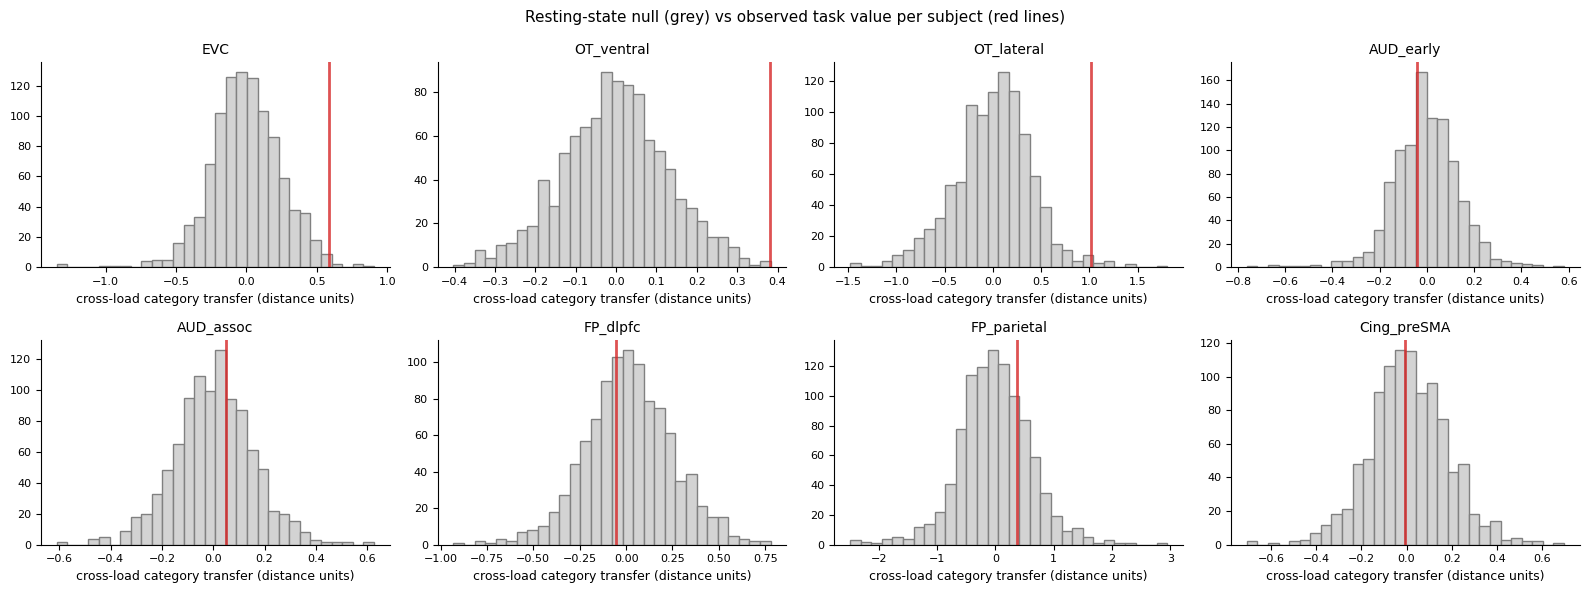

In [19]:
# ============ rfMRI MATCHED NULL (revised, scales to any number of subjects) ============
# For each subject in SUBJECTS that has resting-state files: draw many random 405-frame windows of the resting runs, fit the real
# HRF-convolved WM design with the same AR(1) GLM used for the task patterns, and compute the same H1 statistics.
# The observed task statistics are then compared with that subject's null. With 2+ resting subjects a GROUP null is built too
# (mean over subjects within each draw), which is the valid comparison for the group-level claim.
#
# Adding subjects later: append the ID to SUBJECTS, download that subject's rest runs to the path in REST_DIR, run this cell again.
# Subjects whose draws are already saved in derivatives/novelty/rfmri_null_draws_<sid>.csv are NOT recomputed (delete the file to redo).
import os
import time
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

# ---- paths: {sid} and {run} are filled in; edit only these four lines ----
REST_DIR = "/Users/shwetharao/Downloads/{sid}_rest/MNINonLinear/Results/rfMRI_REST1_{run}"
REST_FILE = REST_DIR + "/rfMRI_REST1_{run}_Atlas_MSMAll_hp2000_clean_rclean_tclean.dtseries.nii"
REST_MOTION = REST_DIR + "/Movement_Regressors.txt"
TASK_EV_DIR = "/Users/shwetharao/Downloads/{sid}/MNINonLinear/Results/tfMRI_WM_{run}/EVs"

N_DRAWS = 1000                  # random windows per resting subject (both runs drawn independently); 100 is enough for a quick look
RECOMPUTE_NULL = False          # True: ignore saved draws and redo every subject
N_WM_TRS, TR_WM = 405, 0.72


def _ev_dir_for(sid, run):
    """The WM event files only define the design shape. Use the subject's own if present, otherwise any other subject's
    (a null design needs a realistic block structure, not the subject's own timing)."""
    for cand in [sid] + [s for s in SUBJECTS if s != sid]:
        d = TASK_EV_DIR.format(sid=cand, run=run)
        if os.path.isdir(d) and os.path.isfile(os.path.join(os.path.dirname(d), "Movement_Regressors.txt")):
            if cand != sid:
                print(f"  {sid} {run}: own WM EV folder not found, using {cand}'s block structure")
            return d
    raise FileNotFoundError(f"No WM EV folder found for any subject (template: {TASK_EV_DIR})")


def _load_rest(path, union_mask):
    Y = np.asarray(nib.load(path).get_fdata(dtype=np.float32))
    if Y.ndim != 2 or Y.shape[1] != union_mask.size:
        raise ValueError(f"Unexpected shape {Y.shape} for {path}")
    return Y[:, union_mask].astype(np.float64)


def _rest_motion(path, n_rows):
    with open(path) as fh:
        M = np.loadtxt(fh)[:, :12]
    if M.shape[0] != n_rows:
        raise ValueError(f"Motion rows ({M.shape[0]}) != rest frames ({n_rows}) in {path}")
    return M


def rest_available(sid):
    return all(os.path.isfile(REST_FILE.format(sid=sid, run=r)) and os.path.isfile(REST_MOTION.format(sid=sid, run=r)) for r in ("LR", "RL"))


def null_draws_for_subject(sid, n_draws=N_DRAWS):
    rng = np.random.default_rng(NOVELTY_SEED + int("".join(ch for ch in sid if ch.isdigit()) or 0))
    union = np.any(np.vstack(list(roi_masks.values())), axis=0)
    roi_in_union = {roi: m[union] for roi, m in roi_masks.items()}
    loaded = {}
    for run in ("LR", "RL"):
        Y = _load_rest(REST_FILE.format(sid=sid, run=run), union)
        M = _rest_motion(REST_MOTION.format(sid=sid, run=run), Y.shape[0])
        ev_dir = _ev_dir_for(sid, run)
        task_cols = build_design(ev_dir, os.path.join(os.path.dirname(ev_dir), "Movement_Regressors.txt"),
                                 WM_CONDS, N_WM_TRS, TR_WM).iloc[:, :8].values       # HRF-convolved WM regressors
        dct = generate_dct_basis(N_WM_TRS, TR_WM, 128.0).values
        loaded[run] = (Y, M, task_cols, dct)
        print(f"{sid} {run}: {Y.shape[0]} resting frames, {N_WM_TRS}-frame windows, {Y.shape[1]} ROI-union grayordinates")
    records, t0 = [], time.time()
    for d in range(n_draws):
        pats = {}
        for run, (Y, M, task_cols, dct) in loaded.items():
            start = int(rng.integers(0, Y.shape[0] - N_WM_TRS + 1))
            X = np.column_stack([task_cols, M[start:start + N_WM_TRS], dct, np.ones(N_WM_TRS)])
            Cm = np.zeros((8, X.shape[1])); Cm[np.arange(8), np.arange(8)] = 1.0
            _, tstats, _ = fit_glm_ar1_binned(Y[start:start + N_WM_TRS], X, Cm)
            pats[run] = tstats
        for roi, m in roi_in_union.items():
            A, B = nonflat(pats["LR"][:, m], pats["RL"][:, m])
            if A.shape[1] == 0:
                continue
            records.append(dict(subject=sid, draw=d, roi=roi, n_features=A.shape[1], **h1_stats(A, B)))
        if d == 0:
            print(f"  first draw took {time.time() - t0:.1f} s -> about {(time.time() - t0) * n_draws / 60:.0f} min for {n_draws} draws")
        elif (d + 1) % max(1, n_draws // 10) == 0:
            print(f"  {sid}: draw {d + 1}/{n_draws}")
    return pd.DataFrame(records)


# ---- run (or load) the null for every subject that has resting data ----
rest_subjects = [s for s in SUBJECTS if rest_available(s)]
missing = [s for s in SUBJECTS if s not in rest_subjects]
print("Resting data found for:", rest_subjects or "none")
if missing:
    print("No resting data (yet) for:", missing, "-> they are skipped")
if not rest_subjects:
    raise RuntimeError("No subject has resting-state files at the paths above.")
frames = []
for sid in rest_subjects:
    f = os.path.join(NOVELTY_DIR, f"rfmri_null_draws_{sid}.csv")
    if os.path.isfile(f) and not RECOMPUTE_NULL:
        print(f"{sid}: using saved draws ({f})")
        df = pd.read_csv(f, dtype={"subject": str})
    else:
        df = null_draws_for_subject(sid)
        df.to_csv(f, index=False)
    frames.append(df)
rfmri_null = pd.concat(frames, ignore_index=True)

# ---- observed task statistics for the same subjects ----
obs_rows = []
for sid in rest_subjects:
    P = get_patterns(sid)
    for roi, mask in roi_masks.items():
        A, B = nonflat(P["WM_LR_t"][:, mask].astype(float), P["WM_RL_t"][:, mask].astype(float))
        obs_rows.append(dict(subject=sid, roi=roi, **h1_stats(A, B)))
obs = pd.DataFrame(obs_rows)

# ---- per-subject comparison ----
cmp_rows = []
for roi in roi_masks:
    for stat in ("transfer_num", "rho"):
        for sid in rest_subjects:
            nul = rfmri_null[(rfmri_null.roi == roi) & (rfmri_null.subject == sid)][stat].dropna().values
            o = obs[(obs.roi == roi) & (obs.subject == sid)][stat].iloc[0]
            cmp_rows.append(dict(level=sid, roi=roi, statistic=stat, observed=o, null_mean=nul.mean(), null_sd=nul.std(ddof=1),
                                 null_95=np.percentile(nul, 95), p_empirical=(1 + np.sum(nul >= o)) / (len(nul) + 1), n_draws=len(nul)))
# ---- group comparison (needs 2+ resting subjects): mean over subjects inside each draw ----
if len(rest_subjects) >= 2:
    for roi in roi_masks:
        for stat in ("transfer_num", "rho"):
            piv = rfmri_null[rfmri_null.roi == roi].pivot(index="draw", columns="subject", values=stat)[rest_subjects].dropna()
            gnull = piv.mean(axis=1).values
            o = obs[obs.roi == roi].set_index("subject").loc[rest_subjects, stat].mean()
            cmp_rows.append(dict(level="GROUP(n=%d)" % len(rest_subjects), roi=roi, statistic=stat, observed=o, null_mean=gnull.mean(),
                                 null_sd=gnull.std(ddof=1), null_95=np.percentile(gnull, 95),
                                 p_empirical=(1 + np.sum(gnull >= o)) / (len(gnull) + 1), n_draws=len(gnull)))
null_cmp = pd.DataFrame(cmp_rows)
# FDR inside each family (statistic x level), not across unrelated tests
null_cmp["q_fdr"] = np.nan
for (stat, level), idx in null_cmp.groupby(["statistic", "level"]).groups.items():
    null_cmp.loc[idx, "q_fdr"] = bh_fdr(null_cmp.loc[idx, "p_empirical"].values)
print("\nObserved task statistic vs resting-state matched null (p = share of null draws >= observed; q = BH within statistic x level)")
print("transfer_num is the primary statistic; rho (6-pair Spearman) is kept only to show how noisy it is.")
print(null_cmp.sort_values(["statistic", "level", "roi"]).round(3).to_string(index=False))
if len(rest_subjects) < 2:
    print("\nCAUTION: only %d resting subject. These p-values apply to that subject only; add resting runs for more subjects for a group claim." % len(rest_subjects))
print("\nSmallest possible p with %d draws: %.4f" % (N_DRAWS, 1.0 / (N_DRAWS + 1)))

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, roi in zip(axes.ravel(), roi_masks):
    nul = rfmri_null[rfmri_null.roi == roi].transfer_num.dropna()
    ax.hist(nul, bins=30, color="lightgray", edgecolor="gray")
    for _, o in obs[obs.roi == roi].iterrows():
        ax.axvline(o.transfer_num, color="tab:red", lw=2, alpha=.8)
    ax.set_title(roi, fontsize=10); ax.set_xlabel("cross-load category transfer (distance units)")
fig.suptitle("Resting-state null (grey) vs observed task value per subject (red lines)", fontsize=11)
plt.tight_layout(); plt.savefig(os.path.join(NOVELTY_DIR, "rfmri_null_transfer.png"), dpi=150); plt.show()
null_cmp.to_csv(os.path.join(NOVELTY_DIR, "rfmri_null_vs_observed.csv"), index=False)


## RSA validation and inferential statistics (added implementation)

These cells implement the planned RSA checks in NumPy/SciPy: synthetic unit tests, Mantel-style permutation inference for RDM similarity, subject-level bootstrap intervals, and a descriptive leave-one-subject-out noise ceiling. They use the project’s own `crossnobis_rdm` implementation. Run after cells 8–11 and 13, once pattern files and ROI masks exist.

In [20]:
# ============ RSA VALIDATION: synthetic unit tests ============
import numpy as np
from scipy.stats import spearmanr, kendalltau

def run_rsa_unit_tests(seed=123):
    """Fast tests for symmetry/diagonal, crossnobis recovery, and rank correlation."""
    rng = np.random.default_rng(seed)
    # Same patterns in independent runs plus independent noise: distances should be symmetric with zero diagonal.
    base = rng.normal(size=(8, 30))
    A = base + rng.normal(scale=.15, size=base.shape)
    B = base + rng.normal(scale=.15, size=base.shape)
    D = crossnobis_rdm(A, B)
    assert D.shape == (8, 8), D.shape
    assert np.allclose(D, D.T, atol=1e-12), "crossnobis RDM must be symmetric"
    assert np.allclose(np.diag(D), 0), "crossnobis RDM diagonal must be zero"
    assert np.all(np.isfinite(D)), "crossnobis RDM contains non-finite values"
    # Distinct condition means should be recovered as positive cross-validated distances on average.
    assert np.mean(D[np.triu_indices(8, 1)]) > 0, "synthetic signal did not produce positive mean distance"
    assert spearmanr([1, 2, 3, 4], [4, 3, 2, 1]).statistic < -.99
    assert kendalltau([1, 2, 3], [1, 2, 3]).statistic > .99
    # Zero signal gives expected distance approximately zero in expectation; finite sample tolerance is broad.
    Z = rng.normal(size=(8, 2000))
    Dz = crossnobis_rdm(Z, rng.normal(size=Z.shape))
    assert abs(Dz[np.triu_indices(8, 1)].mean()) < .08
    return {"tests": 7, "status": "passed"}

print(run_rsa_unit_tests())


{'tests': 7, 'status': 'passed'}


## Haxby-style identification and feature-removal robustness

The existing helper `removal_curve` compares removal of the most category-selective grayordinates against random removal. This cell runs it per subject and ROI, stores tidy output, and plots the curves. Feature selection is computed independently in each run and evaluated cross-run to reduce circularity. Interpret the result as robustness, not as a confirmatory p-value.

,subject,roi,removed_fraction,outcome,selective_removal,random_removal,n_features
0,103414,EVC,0.0,within_0back,0.916667,0.916667,3632
1,103414,EVC,0.0,within_2back,0.958333,0.958333,3632
2,103414,EVC,0.0,cross_load,0.833333,0.833333,3632
3,103414,EVC,0.1,within_0back,0.916667,0.916667,3632
4,103414,EVC,0.1,within_2back,0.875000,0.933750,3632
5,103414,EVC,0.1,cross_load,0.833333,0.833333,3632
6,103414,EVC,0.2,within_0back,0.895833,0.916667,3632
7,103414,EVC,0.2,within_2back,0.812500,0.930417,3632
8,103414,EVC,0.2,cross_load,0.791667,0.837083,3632
9,103414,EVC,0.3,within_0back,0.812500,0.915417,3632


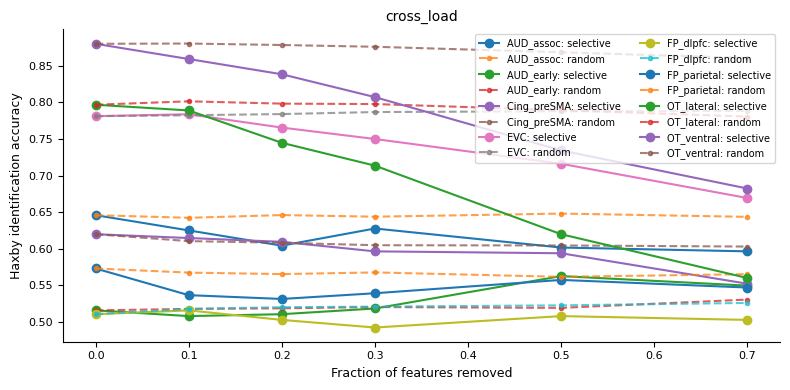

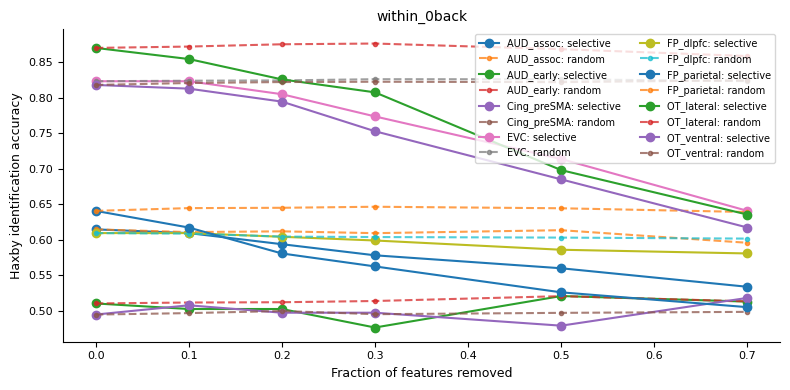

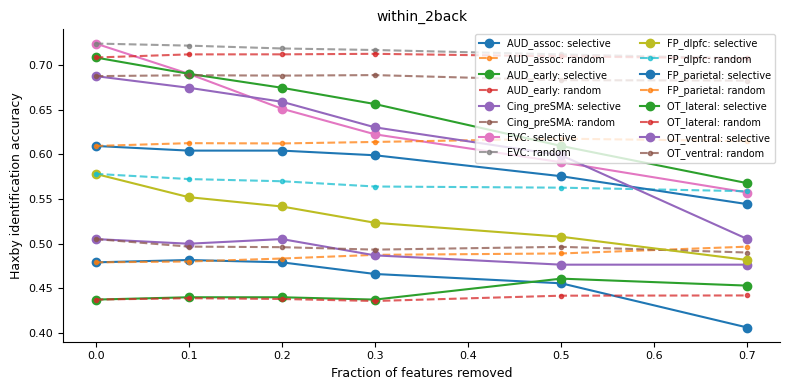

In [21]:
# ============ HAXBY IDENTIFICATION + SELECTIVE-VOXEL REMOVAL ============
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REMOVAL_FRACS = (0, .1, .2, .3, .5, .7)
removal_rows = []
for sid in SUBJECTS:
    pfile = os.path.join(OUT_DIR, f"{sid}_patterns.npz")
    if not os.path.exists(pfile):
        print(f"Skipping {sid}: missing {pfile}"); continue
    P = np.load(pfile)
    Aall, Ball = P["WM_LR_t"], P["WM_RL_t"]
    for roi, mask in roi_masks.items():
        A, B = Aall[:, mask], Ball[:, mask]
        keep = (A.std(axis=0) > 1e-12) & (B.std(axis=0) > 1e-12)
        A, B = A[:, keep], B[:, keep]
        if A.shape[1] < 10:
            print(f"Skipping {sid}/{roi}: too few nonconstant features ({A.shape[1]})"); continue
        selective, random = removal_curve(A, B, fracs=REMOVAL_FRACS, n_rand=100, seed=2026)
        for j, frac in enumerate(REMOVAL_FRACS):
            for k, outcome in enumerate(("within_0back", "within_2back", "cross_load")):
                removal_rows.append({"subject": sid, "roi": roi, "removed_fraction": frac,
                                     "outcome": outcome, "selective_removal": selective[j, k],
                                     "random_removal": random[j, k], "n_features": A.shape[1]})
removal_df = pd.DataFrame(removal_rows)
if not removal_df.empty:
    display(removal_df.head(12))
    group_removal = removal_df.groupby(["roi", "removed_fraction", "outcome"], as_index=False).agg(
        selective_mean=("selective_removal", "mean"), random_mean=("random_removal", "mean"), n_subjects=("subject", "nunique"))
    for outcome in group_removal["outcome"].unique():
        fig, ax = plt.subplots(figsize=(8, 4))
        sub = group_removal[group_removal.outcome == outcome]
        for roi in sub.roi.unique():
            q = sub[sub.roi == roi].sort_values("removed_fraction")
            ax.plot(q.removed_fraction, q.selective_mean, marker="o", label=f"{roi}: selective")
            ax.plot(q.removed_fraction, q.random_mean, marker=".", linestyle="--", alpha=.75, label=f"{roi}: random")
        ax.set(xlabel="Fraction of features removed", ylabel="Haxby identification accuracy", title=outcome)
        ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
    removal_df.to_csv(os.path.join(OUT_DIR, "haxby_removal_curve_subject_level.csv"), index=False)
else:
    print("No removal results: confirm pattern files and ROI masks are available.")


## RDM inference: Mantel-style permutation, bootstrap, and noise ceiling

RDM vectors are the upper-triangular entries. The Mantel-style test permutes condition labels in one RDM (the same permutation applied to rows and columns), preserving the RDM structure; this is a within-subject test of whether the two 4×4 load-specific RDMs are more similar than expected under relabelling. Group summaries use subjects as the sampling unit. The noise ceiling here is a descriptive lower/upper bound based on each subject’s RDM agreement with the group mean RDM; it is not a substitute for a hierarchical model.

In [22]:
# ============ MANTEL TEST + GROUP BOOTSTRAP + DESCRIPTIVE NOISE CEILING ============
from itertools import permutations
from scipy.stats import spearmanr, kendalltau


def rdm_vector(D):
    D = np.asarray(D, float)
    if D.ndim != 2 or D.shape[0] != D.shape[1]:
        raise ValueError("RDM must be square")
    tri = np.triu_indices(D.shape[0], 1)
    return D[tri]


def mantel_rdm_test(D1, D2, n_perm=5000, seed=0, method="spearman"):
    """Two-sided label-permutation test of RDM association; labels permuted jointly on both axes of D2."""
    D1, D2 = np.asarray(D1, float), np.asarray(D2, float)
    if D1.shape != D2.shape or D1.ndim != 2 or D1.shape[0] != D1.shape[1]:
        raise ValueError("RDMs must be square and have identical shapes")
    n = D1.shape[0]
    tri = np.triu_indices(n, 1)
    def stat(X, Y):
        if method == "kendall": return float(kendalltau(X[tri], Y[tri], variant="b").statistic)
        return float(spearmanr(X[tri], Y[tri]).statistic)
    obs = stat(D1, D2)
    rng = np.random.default_rng(seed)
    null = np.empty(n_perm)
    for i in range(n_perm):
        ix = rng.permutation(n)
        null[i] = stat(D1, D2[np.ix_(ix, ix)])
    p = (1 + np.sum(np.abs(null) >= abs(obs))) / (n_perm + 1)
    return obs, p, null


def subject_bootstrap_ci(values, n_boot=10000, seed=0, confidence=95):
    """Percentile CI resampling subjects, never individual condition pairs."""
    x = np.asarray(values, float)
    x = x[np.isfinite(x)]
    if len(x) == 0: return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    boot = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    alpha = (100-confidence)/2
    return tuple(np.percentile(boot, [alpha, 100-alpha]))

# Build per-subject load-specific RDMs, Mantel p-values, and subject-level noise ceiling.
rdm_store, infer_rows = {}, []
tri4 = np.triu_indices(4, 1)
for sid in SUBJECTS:
    pfile = os.path.join(OUT_DIR, f"{sid}_patterns.npz")
    if not os.path.exists(pfile): continue
    P = np.load(pfile)
    for roi, mask in roi_masks.items():
        A, B = P["WM_LR_t"][:, mask].astype(float), P["WM_RL_t"][:, mask].astype(float)
        keep = (A.std(axis=0) > 1e-12) & (B.std(axis=0) > 1e-12)
        if keep.sum() < 2: continue
        D = crossnobis_rdm(A[:, keep], B[:, keep])
        D0, D2 = D[:4, :4], D[4:8, 4:8]
        rho, p_mantel, _ = mantel_rdm_test(D0, D2, n_perm=5000, seed=(sum(ord(ch) for ch in str(sid)) * 1009 + sum(ord(ch) for ch in str(roi))) % (2**32))
        tau = kendalltau(rdm_vector(D0), rdm_vector(D2), variant="b").statistic
        rdm_store[(sid, roi, "0back")] = D0
        rdm_store[(sid, roi, "2back")] = D2
        infer_rows.append({"subject": sid, "roi": roi, "spearman_structure": rho,
                           "kendall_structure": tau, "mantel_p": p_mantel,
                           "mean_abs_0back": np.mean(np.abs(rdm_vector(D0))),
                           "mean_abs_2back": np.mean(np.abs(rdm_vector(D2)))})
rdm_inference = pd.DataFrame(infer_rows)
if not rdm_inference.empty:
    # BH correction is across ROI-level Mantel tests in this table.
    rdm_inference["mantel_q_fdr"] = bh_fdr(rdm_inference["mantel_p"].values)
    display(rdm_inference.round(4))
    group_rows = []
    for roi, g in rdm_inference.groupby("roi"):
        for metric in ("spearman_structure", "kendall_structure"):
            lo, hi = subject_bootstrap_ci(g[metric].values)
            group_rows.append({"roi": roi, "metric": metric, "mean": g[metric].mean(), "ci_low": lo,
                               "ci_high": hi, "n_subjects": g.subject.nunique(),
                               "signflip_p": signflip_p(g[metric].values) if len(g) >= 2 else np.nan})
    rdm_group_summary = pd.DataFrame(group_rows)
    display(rdm_group_summary.round(4))

    # Descriptive noise ceiling for each load/ROI: subject RDM vs mean RDM of other subjects (lower),
    # and subject RDM vs mean RDM including itself (upper). Only meaningful with >=3 subjects.
    ceiling_rows = []
    for roi in roi_masks:
        for load in ("0back", "2back"):
            keys = [(sid, roi, load) for sid in SUBJECTS if (sid, roi, load) in rdm_store]
            if len(keys) < 3: continue
            vecs = {k[0]: rdm_vector(rdm_store[k]) for k in keys}
            for sid0 in vecs:
                others = [v for s, v in vecs.items() if s != sid0]
                allv = list(vecs.values())
                lower = spearmanr(vecs[sid0], np.mean(others, axis=0)).statistic
                upper = spearmanr(vecs[sid0], np.mean(allv, axis=0)).statistic
                ceiling_rows.append({"subject": sid0, "roi": roi, "load": load,
                                     "noise_ceiling_lower": lower, "noise_ceiling_upper": upper})
    noise_ceiling_df = pd.DataFrame(ceiling_rows)
    if not noise_ceiling_df.empty:
        display(noise_ceiling_df.groupby(["roi", "load"], as_index=False).agg(
            lower_mean=("noise_ceiling_lower", "mean"), upper_mean=("noise_ceiling_upper", "mean"),
            n_subjects=("subject", "nunique")).round(4))
    else:
        print("Noise ceiling not calculated: at least 3 subjects with usable RDMs per ROI/load are required.")
else:
    print("No RDM inference results. Ensure the pattern extraction and ROI cells ran first.")


,subject,roi,spearman_structure,kendall_structure,mantel_p,mean_abs_0back,mean_abs_2back,mantel_q_fdr
0,103414,EVC,-0.8857,-0.7333,0.0396,1.4067,0.5494,0.9012
1,103414,OT_ventral,-0.3714,-0.3333,0.7129,0.3786,0.4719,1.0000
2,103414,OT_lateral,-0.0857,-0.0667,0.9608,0.9828,0.8048,1.0000
3,103414,AUD_early,-0.7714,-0.6000,0.2448,0.1025,0.1468,0.9012
4,103414,AUD_assoc,-0.4857,-0.3333,0.5047,0.1263,0.2206,0.9012
...,...,...,...,...,...,...,...,...
59,108121,AUD_early,0.8857,0.7333,0.0822,0.4825,0.3730,0.9012
60,108121,AUD_assoc,-0.5429,-0.3333,0.3329,0.1855,0.1555,0.9012
61,108121,FP_dlpfc,0.1429,0.2000,0.7449,0.4930,0.3426,1.0000
62,108121,FP_parietal,0.6571,0.4667,0.3321,0.6963,0.5369,0.9012


,roi,metric,mean,ci_low,ci_high,n_subjects,signflip_p
0,AUD_assoc,spearman_structure,0.0857,-0.2071,0.3857,8,0.6016
1,AUD_assoc,kendall_structure,0.0833,-0.1167,0.2833,8,0.4547
2,AUD_early,spearman_structure,0.1929,-0.1929,0.5500,8,0.3664
3,AUD_early,kendall_structure,0.1667,-0.1333,0.4500,8,0.3288
4,Cing_preSMA,spearman_structure,0.0929,-0.2571,0.4071,8,0.6318
5,Cing_preSMA,kendall_structure,0.1000,-0.2167,0.3500,8,0.5349
6,EVC,spearman_structure,0.1071,-0.3571,0.5071,8,0.6338
7,EVC,kendall_structure,0.0500,-0.3167,0.3667,8,0.7638
8,FP_dlpfc,spearman_structure,0.0071,-0.2145,0.2357,8,0.9304
9,FP_dlpfc,kendall_structure,0.0333,-0.1667,0.2333,8,0.7977


,roi,load,lower_mean,upper_mean,n_subjects
0,AUD_assoc,0back,-0.3571,0.1286,8
1,AUD_assoc,2back,0.1286,0.3000,8
2,AUD_early,0back,0.2643,0.3429,8
3,AUD_early,2back,0.2357,0.4357,8
4,Cing_preSMA,0back,-0.0571,0.1571,8
5,Cing_preSMA,2back,0.5500,0.5786,8
6,EVC,0back,0.4286,0.5500,8
7,EVC,2back,0.6143,0.6214,8
8,FP_dlpfc,0back,0.1571,0.3357,8
9,FP_dlpfc,2back,0.3429,0.4000,8


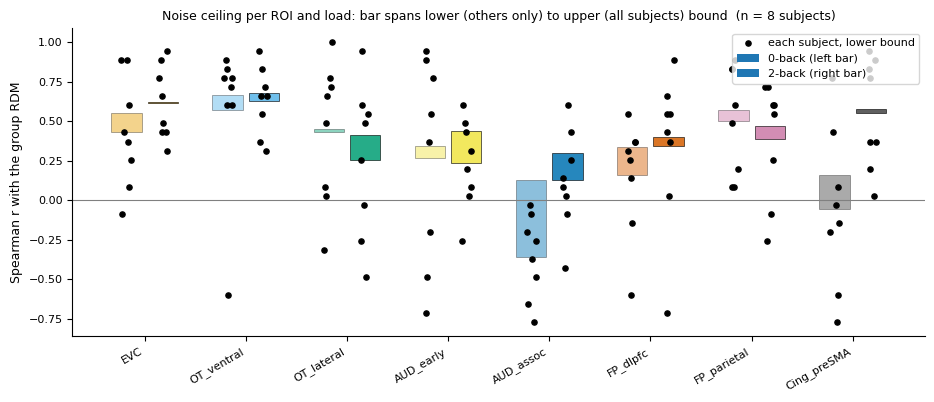

saved derivatives/figures/rdm_noise_ceiling_bands.png


In [23]:
# ============ NOISE-CEILING BANDS ============
# Needs noise_ceiling_df (the Mantel / bootstrap / noise-ceiling cell; requires >= 3 subjects) and the style cell.
# How consistent is each ROI's RDM across subjects? Any model-to-data comparison in that ROI cannot be expected to beat the upper bound.
if "noise_ceiling_df" not in globals() or noise_ceiling_df.empty:
    print("Noise ceiling not available (needs at least 3 subjects with usable RDMs): skipped.")
else:
    fig, ax = plt.subplots(figsize=(11, 4))
    for i, roi in enumerate(ROI_ORDER):
        for k, load in enumerate(("0back", "2back")):
            g = noise_ceiling_df[(noise_ceiling_df.roi == roi) & (noise_ceiling_df.load == load)]
            if g.empty:
                continue
            x = i + (k - .5) * .36
            lo, hi = g.noise_ceiling_lower.mean(), g.noise_ceiling_upper.mean()
            ax.bar(x, hi - lo, .3, bottom=lo, color=ROI_COLORS[roi], alpha=.45 if k == 0 else .85, edgecolor="k", lw=.5)
            ax.scatter(np.full(len(g), x) + jit(len(g), .05, seed=i + k), g.noise_ceiling_lower, s=14, color="k", zorder=3)
    ax.axhline(0, color="gray", lw=.8)
    ax.bar([], [], color="gray", alpha=.45, label="0-back (left bar)"); ax.bar([], [], color="gray", alpha=.85, label="2-back (right bar)")
    ax.scatter([], [], s=14, color="k", label="each subject, lower bound"); ax.legend(loc="upper right")
    ax.set_xticks(range(len(ROI_ORDER))); ax.set_xticklabels(ROI_ORDER, rotation=30, ha="right")
    ax.set_ylabel("Spearman r with the group RDM"); ax.set_title(n_title("Noise ceiling per ROI and load: bar spans lower (others only) to upper (all subjects) bound"), fontsize=9)
    save_fig(fig, "rdm_noise_ceiling_bands.png")


## Decoding implementation note: linear SVM with fold-local scaling

The existing LOSO ridge decoder is retained as a baseline. This optional analysis implements a linear SVM with `StandardScaler` fitted only on the training subjects within each fold. Do not standardize using all subjects before cross-validation. The function returns per-held-out-subject accuracy; run it after the decoding dataset cell. This SVM is an additional cross-check and can be slow for many ROIs/permutations.

In [24]:
# ============ LINEAR SVM MVPA DECODING ============
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd


def svm_loso_accuracy(
    X, y, subj, train_sel=None, test_sel=None, C=1.0
):
    """
    Leave-one-subject-out linear SVM.
    StandardScaler is fitted only on training subjects.
    """

    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    subj = np.asarray(subj)

    train_sel = (
        np.ones(len(y), dtype=bool)
        if train_sel is None else np.asarray(train_sel, dtype=bool)
    )

    test_sel = (
        np.ones(len(y), dtype=bool)
        if test_sel is None else np.asarray(test_sel, dtype=bool)
    )

    if not (len(X) == len(y) == len(subj)):
        raise ValueError("X, y and subj must have matching sample counts.")

    scores = []
    held_subjects = []

    for s in np.unique(subj):

        train = (subj != s) & train_sel
        test = (subj == s) & test_sel

        if train.sum() == 0 or test.sum() == 0:
            continue

        if len(np.unique(y[train])) < 2:
            continue

        model = make_pipeline(
            StandardScaler(),
            LinearSVC(
                C=C,
                max_iter=20000,
                random_state=0,
                dual='auto'
            )
        )

        model.fit(X[train], y[train])

        predictions = model.predict(X[test])

        scores.append(accuracy_score(y[test], predictions))
        held_subjects.append(s)

    return np.asarray(scores), np.asarray(held_subjects)


# ============ RUN DECODING FOR EACH ROI ============

svm_results = []

for roi in roi_masks:

    print(f"\nProcessing ROI: {roi}")

    # Build the datasets
    wm = build_dataset(roi, "WM")
    language = build_dataset(roi, "LANGUAGE")

    # 1. 0-back category decoding
    acc, held = svm_loso_accuracy(
        wm["X_main"],
        wm["y"],
        wm["subj"],
        train_sel=(wm["load"] == 0),
        test_sel=(wm["load"] == 0)
    )

    for s, a in zip(held, acc):
        svm_results.append({
            "ROI": roi,
            "Analysis": "0-back category",
            "Subject": str(s),
            "Accuracy": a
        })

    # 2. 2-back category decoding
    acc, held = svm_loso_accuracy(
        wm["X_main"],
        wm["y"],
        wm["subj"],
        train_sel=(wm["load"] == 1),
        test_sel=(wm["load"] == 1)
    )

    for s, a in zip(held, acc):
        svm_results.append({
            "ROI": roi,
            "Analysis": "2-back category",
            "Subject": str(s),
            "Accuracy": a
        })

    # 3. Cross-load: train 0-back, test 2-back
    acc, held = svm_loso_accuracy(
        wm["X_main"],
        wm["y"],
        wm["subj"],
        train_sel=(wm["load"] == 0),
        test_sel=(wm["load"] == 1)
    )

    for s, a in zip(held, acc):
        svm_results.append({
            "ROI": roi,
            "Analysis": "0-back to 2-back",
            "Subject": str(s),
            "Accuracy": a
        })

    # 4. Cross-load: train 2-back, test 0-back
    acc, held = svm_loso_accuracy(
        wm["X_main"],
        wm["y"],
        wm["subj"],
        train_sel=(wm["load"] == 1),
        test_sel=(wm["load"] == 0)
    )

    for s, a in zip(held, acc):
        svm_results.append({
            "ROI": roi,
            "Analysis": "2-back to 0-back",
            "Subject": str(s),
            "Accuracy": a
        })

    # 5. Binary load decoding
    acc, held = svm_loso_accuracy(
        wm["X_load"],
        wm["load"],
        wm["subj"]
    )

    for s, a in zip(held, acc):
        svm_results.append({
            "ROI": roi,
            "Analysis": "Load decoding",
            "Subject": str(s),
            "Accuracy": a
        })

    # 6. Story vs Math decoding
    acc, held = svm_loso_accuracy(
        language["X_main"],
        language["y"],
        language["subj"]
    )

    for s, a in zip(held, acc):
        svm_results.append({
            "ROI": roi,
            "Analysis": "Story vs Math",
            "Subject": str(s),
            "Accuracy": a
        })


svm_results = pd.DataFrame(svm_results)

display(svm_results)

# Group-level summary
svm_summary = (
    svm_results
    .groupby(["ROI", "Analysis"])["Accuracy"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

display(svm_summary.round(4))

svm_results.to_csv(
    os.path.join(OUT_DIR, "MVPA_SVM_subject_results.csv"),
    index=False
)

svm_summary.to_csv(
    os.path.join(OUT_DIR, "MVPA_SVM_group_summary.csv"),
    index=False
)


Processing ROI: EVC
WM / EVC: 8 subjects, 128 samples, 3632 ROI features
LANGUAGE / EVC: 8 subjects, 32 samples, 3632 ROI features

Processing ROI: OT_ventral
WM / OT_ventral: 8 subjects, 128 samples, 1850 ROI features
LANGUAGE / OT_ventral: 8 subjects, 32 samples, 1850 ROI features

Processing ROI: OT_lateral
WM / OT_lateral: 8 subjects, 128 samples, 788 ROI features
LANGUAGE / OT_lateral: 8 subjects, 32 samples, 788 ROI features

Processing ROI: AUD_early
WM / AUD_early: 8 subjects, 128 samples, 1187 ROI features
LANGUAGE / AUD_early: 8 subjects, 32 samples, 1187 ROI features

Processing ROI: AUD_assoc
WM / AUD_assoc: 8 subjects, 128 samples, 2274 ROI features
LANGUAGE / AUD_assoc: 8 subjects, 32 samples, 2274 ROI features

Processing ROI: FP_dlpfc
WM / FP_dlpfc: 8 subjects, 128 samples, 3318 ROI features
LANGUAGE / FP_dlpfc: 8 subjects, 32 samples, 3318 ROI features

Processing ROI: FP_parietal
WM / FP_parietal: 8 subjects, 128 samples, 2460 ROI features
LANGUAGE / FP_parietal: 8 s

,ROI,Analysis,Subject,Accuracy
0,EVC,0-back category,0,1.000
1,EVC,0-back category,1,1.000
2,EVC,0-back category,2,0.875
3,EVC,0-back category,3,0.625
4,EVC,0-back category,4,0.750
...,...,...,...,...
379,Cing_preSMA,Story vs Math,3,1.000
380,Cing_preSMA,Story vs Math,4,1.000
381,Cing_preSMA,Story vs Math,5,0.500
382,Cing_preSMA,Story vs Math,6,1.000


,ROI,Analysis,mean,std,count
0,AUD_assoc,0-back category,0.2812,0.1736,8
1,AUD_assoc,0-back to 2-back,0.3125,0.2588,8
2,AUD_assoc,2-back category,0.2969,0.2106,8
3,AUD_assoc,2-back to 0-back,0.1719,0.1145,8
4,AUD_assoc,Load decoding,0.6484,0.0880,8
5,AUD_assoc,Story vs Math,1.0000,0.0000,8
6,AUD_early,0-back category,0.2812,0.1294,8
7,AUD_early,0-back to 2-back,0.1875,0.1494,8
8,AUD_early,2-back category,0.3281,0.1326,8
9,AUD_early,2-back to 0-back,0.1562,0.1294,8


## Novelty refinements (from the project document, section 4)

Run these after the cells above, in order. Each cell reads `derivatives/<subject>_patterns.npz` and writes tables and figures to `derivatives/novelty/`.

| cell | question | what it adds |
| --- | --- | --- |
| H1 full model | Does category geometry survive 2-back? | Uses all 8x8 distances: a transfer ratio (shared category code across loads), a gain term, a re-pairing permutation test and an equivalence test. ROIs with no measurable category geometry are flagged and not given a ratio |
| Ridge vs SVM | Why do the decoders disagree? | Same data through ridge and five SVM variants, one setting changed at a time |
| Decoding equivalence | Is the category code load-invariant? | TOST on within-load minus cross-load accuracy, with a margin fixed in advance |
| Cross-task decoding | Does a WM-load decoder separate Math from Story? | Both directions, exact subject-level sign-flip null (the subject is the unit) |
| Demand axis | Do WM load and Math > Story share a pattern? | Cross-run pattern correlation per ROI, with reliability |
| Removal panels | Is category information concentrated in the most selective voxels? | Per-subject lines and excess-drop statistics |
| Geometry plots | What does the transfer ratio summarise? | 0-back vs 2-back pair distances, group RDMs and MDS |
| Evidence table | What survives? | One claim-by-ROI table with an automatic category-only / load-only flag |

Equivalence margins (`EQUIV_MARGIN_ACC`, `EQUIV_MARGIN_TRANSFER`) are set in the helper cell. Fix them before looking at the results.
The smallest possible sign-flip p-value is 2 / 2^n (0.0625 at 5 subjects, 0.0078 at 8), so with few subjects effect sizes and intervals matter more than significance stars.

AUD_early: within-load category distinctness 0.028 (bootstrap CI [-0.049, 0.117] includes 0) -> no measurable category geometry, transfer ratio not computed
AUD_assoc: within-load category distinctness 0.027 (bootstrap CI [-0.120, 0.198] includes 0) -> no measurable category geometry, transfer ratio not computed
FP_dlpfc: within-load category distinctness 0.082 (bootstrap CI [-0.002, 0.157] includes 0) -> no measurable category geometry, transfer ratio not computed
Cing_preSMA: within-load category distinctness -0.010 (bootstrap CI [-0.082, 0.051] includes 0) -> no measurable category geometry, transfer ratio not computed
H1, full 8x8 model. transfer: 1 = same category code at both loads, 0 = none. gain: 2-back / 0-back category distinctness.
p_perm: re-pairing null (24 relabelings per subject, group mean). tost_p: equivalence to full invariance within +/-0.25.
        roi  n_subjects  group_within_distinctness  within_ci_lo  interpretable  transfer_mean  ci_lo  ci_hi  p_perm_transfer_

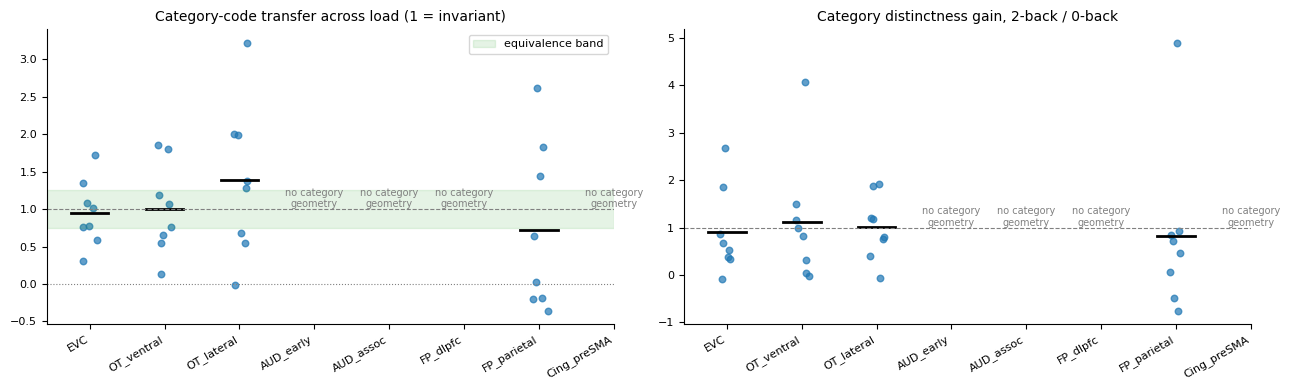

In [25]:
# ============ NOVELTY REFINEMENTS 1: H1 as a full 8x8 model (transfer ratio, gain, equivalence test) ============
# The original H1 statistic is a Spearman correlation over only 6 category pairs per subject, which is very noisy.
# This version uses all 8x8 cross-validated distances, including the cross-load block, and reports:
#   transfer: shared category code across loads (1 = identical, 0 = none), normalised by the group-mean within-load distinctness
#   gain    : how much category geometry strengthens or weakens under 2-back (2-back / 0-back within-load distinctness)
# Inference: (a) label-permutation null for transfer > 0 (re-pair the 2-back categories with the 0-back ones, 24 relabelings),
#            (b) TOST equivalence test for "transfer is within +/- EQUIV_MARGIN_TRANSFER of 1".
rng = np.random.default_rng(NOVELTY_SEED)
h1_full_rows, h1_rdm_store = [], {}
for sid in SUBJECTS:
    P = get_patterns(sid)
    for roi, mask in roi_masks.items():
        A, B = nonflat(P["WM_LR_t"][:, mask].astype(float), P["WM_RL_t"][:, mask].astype(float))
        if A.shape[1] == 0:
            continue
        D = crossnobis_rdm(A, B)
        h1_rdm_store[(sid, roi)] = D
        h1_full_rows.append(dict(subject=sid, roi=roi, n_features=A.shape[1], **h1_stats_from_rdm(D)))
h1_full = pd.DataFrame(h1_full_rows)

# Pooled normalisation: every subject's numerator is divided by the GROUP-mean within-load distinctness of that ROI, so a subject
# with near-zero distinctness cannot blow the ratio up. The mean of these values equals mean(numerator) / mean(denominator).
h1_full["transfer_pooled"] = np.nan
h1_full["gain_pooled"] = np.nan
summary_rows = []
for roi in roi_masks:
    idx = h1_full.roi == roi
    sub = h1_full[idx]
    Ds = [h1_rdm_store[(s, roi)] for s in sub.subject]
    den = sub.within.mean()
    w_lo, w_hi = bootstrap_ci(sub.within.values)
    row = dict(roi=roi, n_subjects=len(sub), group_within_distinctness=den, within_ci_lo=w_lo, interpretable=bool(w_lo > 0))
    if not row["interpretable"]:
        # The ratio divides by the category distinctness inside each load; if that is indistinguishable from 0 the ratio is meaningless.
        print(f"{roi}: within-load category distinctness {den:.3f} (bootstrap CI [{w_lo:.3f}, {w_hi:.3f}] includes 0) -> "
              "no measurable category geometry, transfer ratio not computed")
        summary_rows.append(row)
        continue
    h1_full.loc[idx, "transfer_pooled"] = sub.transfer_num.values / den
    h1_full.loc[idx, "gain_pooled"] = sub.within2.values / sub.within0.mean()
    tp = h1_full.loc[idx, "transfer_pooled"].values
    obs = tp.mean()
    null = np.empty(N_PERM_GROUP)
    for k in range(N_PERM_GROUP):
        null[k] = np.mean([transfer_num(D, ALL_PERMS[rng.integers(24)]) for D in Ds]) / den
    p_perm = (1 + np.sum(null >= obs)) / (N_PERM_GROUP + 1)
    lo, hi = bootstrap_ci(tp)
    eq = tost_one_sample(tp - 1.0, EQUIV_MARGIN_TRANSFER)
    row.update(transfer_mean=obs, ci_lo=lo, ci_hi=hi, p_perm_transfer_gt0=p_perm,
               gain_mean=sub.within2.mean() / sub.within0.mean() if sub.within0.mean() > 0 else np.nan,
               rho_mean=np.nanmean(sub.rho), tost_p_loss_within_margin=eq["p_tost"], equivalent_to_invariance=eq["equivalent"])
    summary_rows.append(row)
h1_full_summary = pd.DataFrame(summary_rows)
for col in ("transfer_mean", "ci_lo", "ci_hi", "p_perm_transfer_gt0", "gain_mean", "rho_mean", "tost_p_loss_within_margin"):
    if col not in h1_full_summary:
        h1_full_summary[col] = np.nan
if "equivalent_to_invariance" not in h1_full_summary:
    h1_full_summary["equivalent_to_invariance"] = np.nan
ok = h1_full_summary.interpretable.values.astype(bool)
h1_full_summary["q_perm"] = np.nan
if ok.any():
    h1_full_summary.loc[ok, "q_perm"] = bh_fdr(h1_full_summary.loc[ok, "p_perm_transfer_gt0"].values)   # FDR over interpretable ROIs only
print("H1, full 8x8 model. transfer: 1 = same category code at both loads, 0 = none. gain: 2-back / 0-back category distinctness.")
print("p_perm: re-pairing null (24 relabelings per subject, group mean). tost_p: equivalence to full invariance within +/-%.2f." % EQUIV_MARGIN_TRANSFER)
print(h1_full_summary.round(3).to_string(index=False))
print("\ninterpretable = False: the ROI has no measurable category distinctness inside a load, so a ratio against it has no meaning.")
print("Note: with few subjects a TOST can only succeed if between-subject spread is small; a failed TOST means 'unresolved', not 'invariance is false'.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title, ref in ((axes[0], "transfer_pooled", "Category-code transfer across load (1 = invariant)", 1.0),
                            (axes[1], "gain_pooled", "Category distinctness gain, 2-back / 0-back", 1.0)):
    for i, roi in enumerate(roi_masks):
        v = h1_full[h1_full.roi == roi][col].values
        if not np.isfinite(v).any():
            ax.text(i, ref, "no category\ngeometry", ha="center", va="bottom", fontsize=7, color="gray")
            continue
        ax.scatter(np.full(len(v), i) + rng.uniform(-.12, .12, len(v)), v, s=22, alpha=.7, color="tab:blue")
        ax.plot([i - .25, i + .25], [np.nanmean(v)] * 2, color="k", lw=2)
    ax.axhline(ref, color="gray", ls="--", lw=.8)
    if col == "transfer_pooled":
        ax.axhspan(ref - EQUIV_MARGIN_TRANSFER, ref + EQUIV_MARGIN_TRANSFER, color="tab:green", alpha=.12, label="equivalence band")
        ax.axhline(0, color="gray", ls=":", lw=.8); ax.legend(fontsize=8)
    ax.set_xticks(range(len(roi_masks))); ax.set_xticklabels(list(roi_masks), rotation=30, ha="right"); ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(NOVELTY_DIR, "h1_transfer_gain.png"), dpi=150); plt.show()
h1_full.to_csv(os.path.join(NOVELTY_DIR, "h1_full_subject_level.csv"), index=False)
h1_full_summary.to_csv(os.path.join(NOVELTY_DIR, "h1_full_group_summary.csv"), index=False)


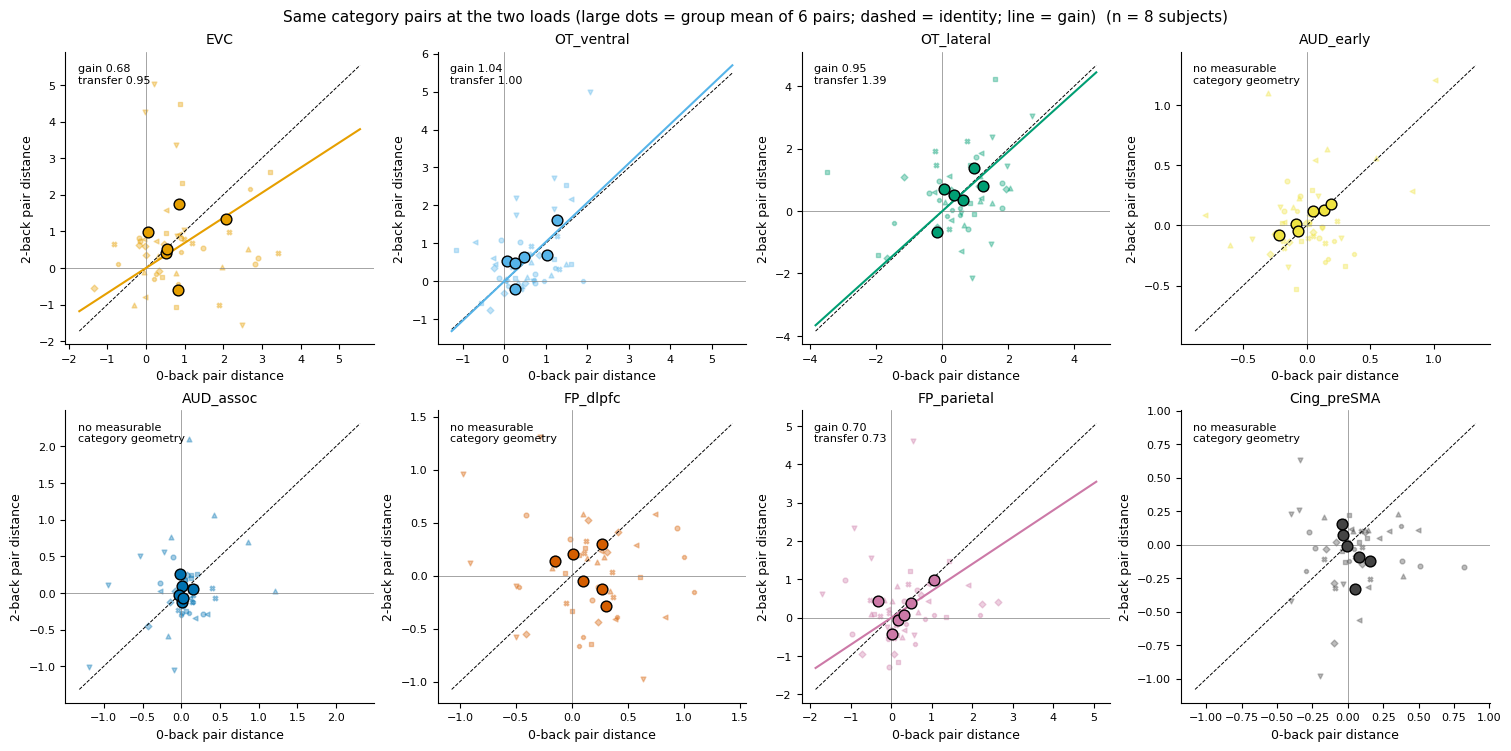

saved derivatives/figures/h1_pair_distances_0_vs_2back.png


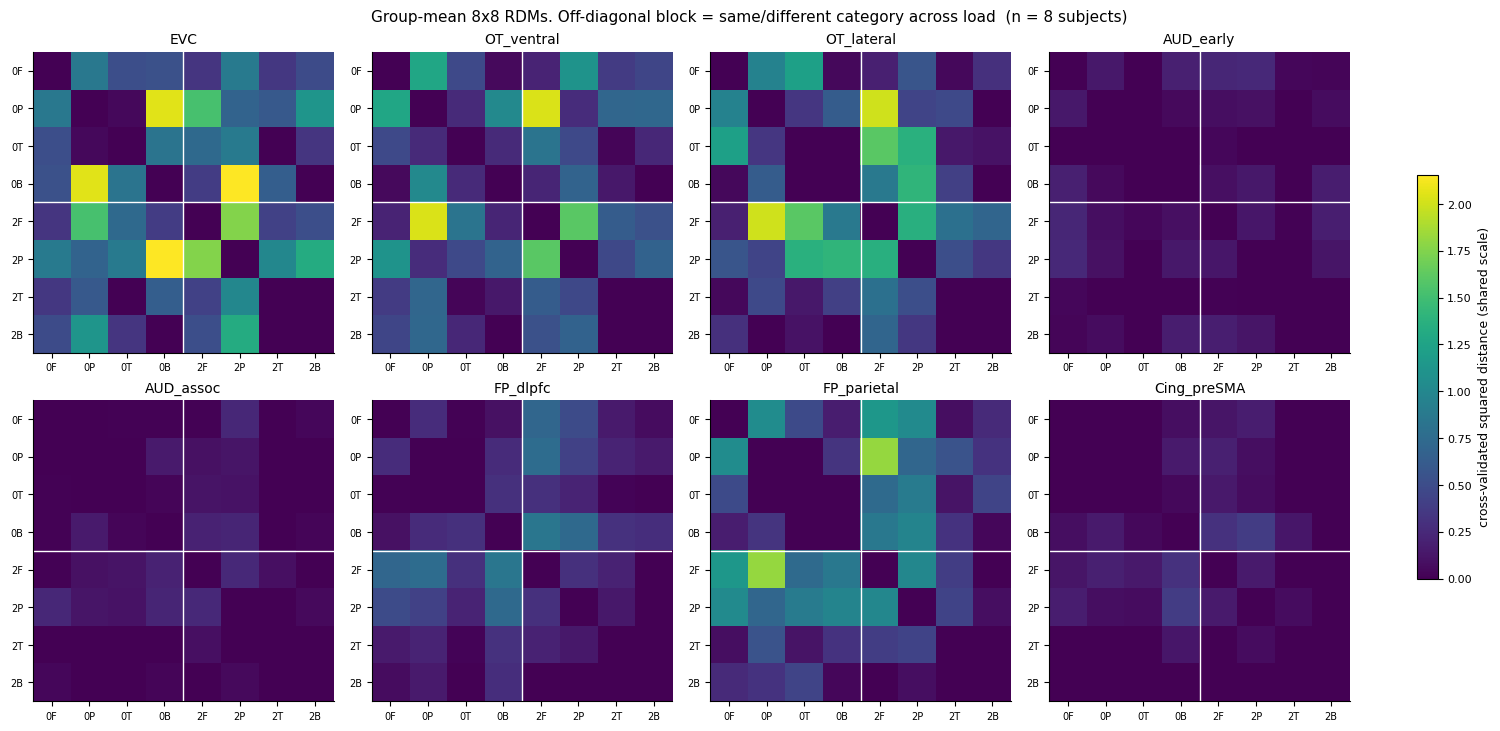

saved derivatives/figures/h1_group_rdms.png


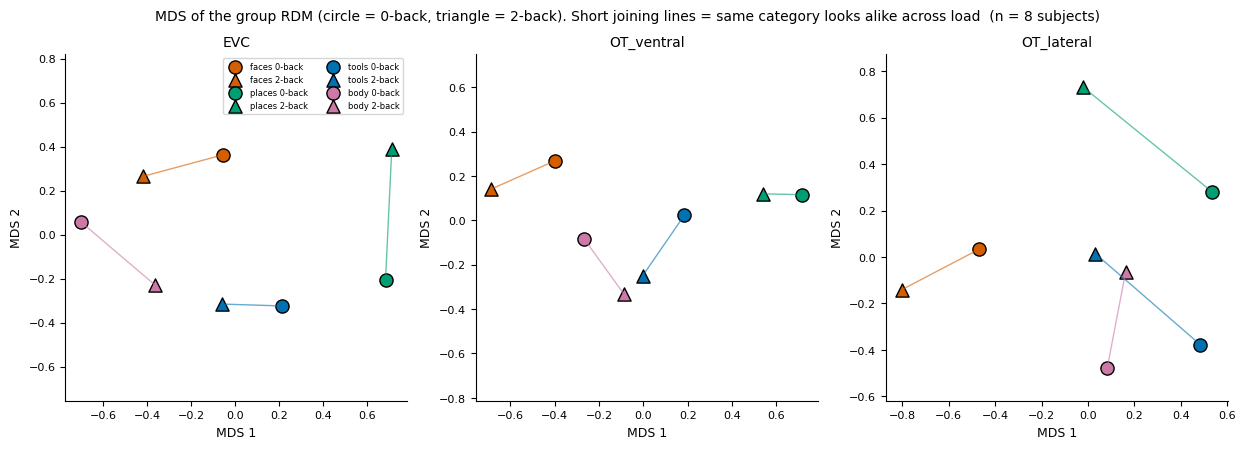

saved derivatives/figures/h1_mds_visual_rois.png


In [26]:
# ============ H1 GEOMETRY PLOTS: 0-back vs 2-back distances, group RDMs, MDS ============
# Needs h1_rdm_store and h1_full_summary from the H1 full-model cell. These show WHAT the transfer ratio and gain summarise.
pair_idx = np.triu_indices(4, 1)
group_D = {roi: np.mean([h1_rdm_store[(sid, roi)] for sid in SUBJECTS if (sid, roi) in h1_rdm_store], axis=0) for roi in ROI_ORDER}
summ = h1_full_summary.set_index("roi")

# ---- 1. The six category-pair distances at 0-back (x) against 2-back (y) ----
fig, axes = plt.subplots(2, 4, figsize=(15, 7.4), constrained_layout=True)
for ax, roi in zip(axes.ravel(), ROI_ORDER):
    per = np.array([[h1_rdm_store[(sid, roi)][:4, :4][pair_idx], h1_rdm_store[(sid, roi)][4:, 4:][pair_idx]]
                    for sid in SUBJECTS if (sid, roi) in h1_rdm_store])          # (subjects, 2, 6)
    for s_i in range(per.shape[0]):
        ax.scatter(per[s_i, 0], per[s_i, 1], s=12, color=ROI_COLORS[roi], alpha=.35, marker=SUBJ_MARKERS[SUBJECTS[s_i]])
    gm = per.mean(axis=0)
    ax.scatter(gm[0], gm[1], s=60, color=ROI_COLORS[roi], edgecolor="k", zorder=3)
    lim = [min(per.min(), 0) * 1.1, per.max() * 1.1]
    ax.plot(lim, lim, "k--", lw=.7); ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5)
    ok = bool(summ.loc[roi, "interpretable"])
    slope = float((gm[0] @ gm[1]) / (gm[0] @ gm[0])) if (gm[0] @ gm[0]) > 0 else np.nan
    if ok and np.isfinite(slope):
        xs = np.array(lim); ax.plot(xs, slope * xs, color=ROI_COLORS[roi], lw=1.5)
    txt = (f"gain {slope:.2f}\ntransfer {summ.loc[roi, 'transfer_mean']:.2f}" if ok else "no measurable\ncategory geometry")
    ax.text(.04, .96, txt, transform=ax.transAxes, va="top", fontsize=8)
    ax.set_title(roi); ax.set_xlabel("0-back pair distance"); ax.set_ylabel("2-back pair distance")
fig.suptitle(n_title("Same category pairs at the two loads (large dots = group mean of 6 pairs; dashed = identity; line = gain)"), fontsize=11)
save_fig(fig, "h1_pair_distances_0_vs_2back.png")

# ---- 2. Group RDMs on one shared colour scale ----
vmax = max(np.abs(D).max() for D in group_D.values())
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), constrained_layout=True)
for ax, roi in zip(axes.ravel(), ROI_ORDER):
    im = ax.imshow(group_D[roi], cmap="viridis", vmin=0, vmax=vmax)
    ax.axhline(3.5, color="w", lw=1); ax.axvline(3.5, color="w", lw=1)
    ax.set_xticks(range(8)); ax.set_xticklabels(SHORT_CONDS, fontsize=7); ax.set_yticks(range(8)); ax.set_yticklabels(SHORT_CONDS, fontsize=7)
    ax.set_title(roi)
fig.colorbar(im, ax=axes, fraction=0.015, label="cross-validated squared distance (shared scale)")
fig.suptitle(n_title("Group-mean 8x8 RDMs. Off-diagonal block = same/different category across load"), fontsize=11)
save_fig(fig, "h1_group_rdms.png")

# ---- 3. MDS of the group RDM in the visual ROIs: category = colour, load = marker, line joins the same category across load ----
def classical_mds(D, k=2):
    n = D.shape[0]; J = np.eye(n) - np.ones((n, n)) / n
    w, V = np.linalg.eigh(-0.5 * J @ D @ J)
    top = np.argsort(w)[::-1][:k]
    return V[:, top] * np.sqrt(np.maximum(w[top], 0))

fig, axes = plt.subplots(1, max(1, len(VISUAL_ROIS)), figsize=(5 * max(1, len(VISUAL_ROIS)), 4.5))
for ax, roi in zip(np.atleast_1d(axes), VISUAL_ROIS):
    X = classical_mds(group_D[roi])
    for c, name in enumerate(CATS):
        ax.plot([X[c, 0], X[4 + c, 0]], [X[c, 1], X[4 + c, 1]], color=CAT_COLORS[name], lw=1, alpha=.6)
        ax.scatter(*X[c], s=90, marker="o", color=CAT_COLORS[name], edgecolor="k", label=f"{name} 0-back" if roi == VISUAL_ROIS[0] else None)
        ax.scatter(*X[4 + c], s=90, marker="^", color=CAT_COLORS[name], edgecolor="k", label=f"{name} 2-back" if roi == VISUAL_ROIS[0] else None)
    ax.set_title(roi); ax.set_xlabel("MDS 1"); ax.set_ylabel("MDS 2"); ax.set_aspect("equal", adjustable="datalim")
np.atleast_1d(axes)[0].legend(fontsize=6, ncol=2, loc="best")
fig.suptitle(n_title("MDS of the group RDM (circle = 0-back, triangle = 2-back). Short joining lines = same category looks alike across load"), fontsize=10)
save_fig(fig, "h1_mds_visual_rois.png")


In [27]:
# ============ NOVELTY REFINEMENTS 2: why do ridge and SVM disagree? ============
# Cell 35 gave Story-vs-Math accuracies far from the ridge results (e.g. 0.30 vs 1.0 in OT_ventral). Before any decoding claim is made,
# run both decoders on IDENTICAL data and vary the SVM one setting at a time. Needs cells 20-21 (build_dataset, LosoModel) and 35 (svm_loso_accuracy).
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeClassifier


def svm_variant(X, y, subj, train_sel, test_sel, scaler=True, intercept=True, C=1.0):
    steps = ([StandardScaler()] if scaler else []) + [LinearSVC(C=C, fit_intercept=intercept, dual=True, max_iter=50000, random_state=0)]
    out = []
    for s in np.unique(subj):
        tr, te = (subj != s) & train_sel, (subj == s) & test_sel
        m = make_pipeline(*steps).fit(X[tr], y[tr])
        out.append(np.mean(m.predict(X[te]) == y[te]))
    return np.array(out)


def ridge_sklearn(X, y, subj, train_sel, test_sel):
    out = []
    for s in np.unique(subj):
        tr, te = (subj != s) & train_sel, (subj == s) & test_sel
        K = X[tr] @ X[tr].T
        m = RidgeClassifier(alpha=float(LAM_REL * np.trace(K) / tr.sum())).fit(X[tr], y[tr])
        out.append(np.mean(m.predict(X[te]) == y[te]))
    return np.array(out)


VARIANTS = {
    "ridge (cell 21)": None,
    "ridge (sklearn)": "sk",
    "SVM as cell 35": dict(scaler=True, intercept=True, C=1.0),
    "SVM no rescale": dict(scaler=False, intercept=True, C=1.0),
    "SVM no intercept": dict(scaler=False, intercept=False, C=1.0),
    "SVM C=1e-4": dict(scaler=False, intercept=True, C=1e-4),
}
cmp_rows = []
for roi in roi_masks:
    wm, lg = build_dataset(roi, "WM"), build_dataset(roi, "LANGUAGE")
    L = wm["load"]
    jobs = {
        "0-back category": (wm["X_main"], wm["y"], wm["subj"], L == 0, L == 0),
        "load": (wm["X_load"], L, wm["subj"], np.ones(len(L), bool), np.ones(len(L), bool)),
        "story vs math": (lg["X_main"], lg["y"], lg["subj"], np.ones(len(lg["y"]), bool), np.ones(len(lg["y"]), bool)),
    }
    for an, (X, y, s, tr, te) in jobs.items():
        for name, cfg in VARIANTS.items():
            if cfg is None:
                acc = LosoModel(X @ X.T, s, tr, te).accuracy(y)
            elif cfg == "sk":
                acc = ridge_sklearn(X, y, s, tr, te)
            else:
                acc = svm_variant(X, y, s, tr, te, **cfg)
            cmp_rows.append(dict(roi=roi, analysis=an, method=name, mean_acc=acc.mean(), min_subject=acc.min(), max_subject=acc.max()))
cmp = pd.DataFrame(cmp_rows)
table = cmp.pivot_table(index=["analysis", "roi"], columns="method", values="mean_acc")[list(VARIANTS)]
table["max |SVM - ridge|"] = (table.drop(columns=["ridge (cell 21)", "ridge (sklearn)"]).sub(table["ridge (cell 21)"], axis=0)).abs().max(axis=1)
print("Mean leave-one-subject-out accuracy by decoder variant (same data in every column)")
print(table.round(2).to_string())
bad = table[table["max |SVM - ridge|"] > 0.15]
print("\nROI x analysis where an SVM variant differs from ridge by > 0.15: %d of %d" % (len(bad), len(table)))
print("Read it as: if 'SVM no rescale' / 'no intercept' / 'C=1e-4' agree with ridge but 'SVM as cell 35' does not, the cell 35 pipeline"
      " (re-scaling already-scaled features, or the regularised intercept) is the cause. If ALL variants differ, check labels and sample order.")
table.to_csv(os.path.join(NOVELTY_DIR, "decoder_reconciliation.csv"))


WM / EVC: 8 subjects, 128 samples, 3632 ROI features
LANGUAGE / EVC: 8 subjects, 32 samples, 3632 ROI features
WM / OT_ventral: 8 subjects, 128 samples, 1850 ROI features
LANGUAGE / OT_ventral: 8 subjects, 32 samples, 1850 ROI features
WM / OT_lateral: 8 subjects, 128 samples, 788 ROI features
LANGUAGE / OT_lateral: 8 subjects, 32 samples, 788 ROI features
WM / AUD_early: 8 subjects, 128 samples, 1187 ROI features
LANGUAGE / AUD_early: 8 subjects, 32 samples, 1187 ROI features
WM / AUD_assoc: 8 subjects, 128 samples, 2274 ROI features
LANGUAGE / AUD_assoc: 8 subjects, 32 samples, 2274 ROI features
WM / FP_dlpfc: 8 subjects, 128 samples, 3318 ROI features
LANGUAGE / FP_dlpfc: 8 subjects, 32 samples, 3318 ROI features
WM / FP_parietal: 8 subjects, 128 samples, 2460 ROI features
LANGUAGE / FP_parietal: 8 subjects, 32 samples, 2460 ROI features
WM / Cing_preSMA: 8 subjects, 128 samples, 1547 ROI features
LANGUAGE / Cing_preSMA: 8 subjects, 32 samples, 1547 ROI features
Mean leave-one-subje

Category decoding, within-load minus cross-load accuracy; equivalence margin +/-0.10
        roi  mean_loss  boot_ci_lo  boot_ci_hi  ci90_lo  ci90_hi  p_loss_detectable  p_tost  equivalent                         verdict
        EVC      0.156       0.094       0.227    0.089    0.223              0.008   0.922       False                loss across load
 OT_ventral      0.086       0.062       0.133    0.042    0.130              0.008   0.284       False                loss across load
 OT_lateral      0.109       0.016       0.203    0.010    0.209              0.098   0.568       False                loss across load
  AUD_early      0.055      -0.031       0.141   -0.036    0.145              0.366   0.188       False                      unresolved
  AUD_assoc      0.062      -0.016       0.148   -0.024    0.149              0.295   0.220       False                      unresolved
   FP_dlpfc      0.141       0.008       0.266    0.005    0.276              0.117   0.706       F

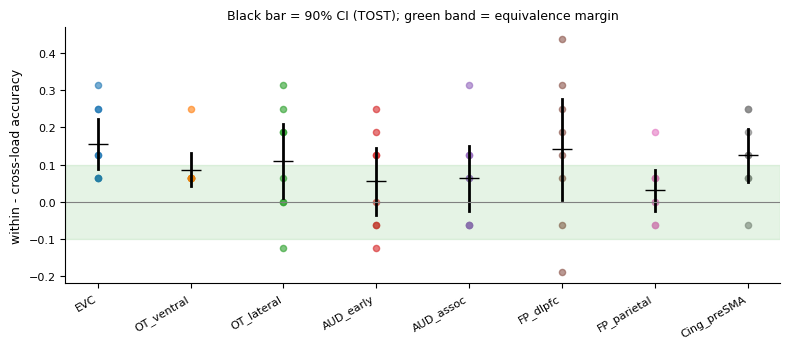

In [28]:
# ============ NOVELTY REFINEMENTS 3: is the category code load-invariant? (equivalence test on decoding) ============
# Uses subj_acc from cell 22 (per-subject accuracies). loss = within-load accuracy - cross-load accuracy.
# TOST asks whether the loss is inside +/- EQUIV_MARGIN_ACC; the sign-flip test asks whether any loss is detectable.
rows = []
for r in roi_masks:
    loss = within(r) - across(r)
    eq = tost_one_sample(loss, EQUIV_MARGIN_ACC)
    lo, hi = bootstrap_ci(loss)
    rows.append(dict(roi=r, mean_loss=loss.mean(), boot_ci_lo=lo, boot_ci_hi=hi, ci90_lo=eq["ci90_lo"], ci90_hi=eq["ci90_hi"],
                     p_loss_detectable=signflip_mean_p(loss), p_tost=eq["p_tost"], equivalent=eq["equivalent"]))
dec_equiv = pd.DataFrame(rows)
dec_equiv["verdict"] = np.where(dec_equiv.equivalent, "no meaningful loss (equivalent)",
                         np.where(dec_equiv.ci90_lo > 0, "loss across load", "unresolved"))
print("Category decoding, within-load minus cross-load accuracy; equivalence margin +/-%.2f" % EQUIV_MARGIN_ACC)
print(dec_equiv.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, r in enumerate(roi_masks):
    loss = within(r) - across(r)
    ax.scatter(np.full(len(loss), i), loss, s=20, alpha=.6)
    e = dec_equiv.iloc[i]
    ax.plot([i, i], [e.ci90_lo, e.ci90_hi], color="k", lw=2); ax.plot(i, e.mean_loss, "k_", ms=14)
ax.axhspan(-EQUIV_MARGIN_ACC, EQUIV_MARGIN_ACC, color="tab:green", alpha=.12); ax.axhline(0, color="gray", lw=.8)
ax.set_xticks(range(len(roi_masks))); ax.set_xticklabels(list(roi_masks), rotation=30, ha="right")
ax.set_ylabel("within - cross-load accuracy"); ax.set_title("Black bar = 90% CI (TOST); green band = equivalence margin", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(NOVELTY_DIR, "decoding_load_invariance_tost.png"), dpi=150); plt.show()
dec_equiv.to_csv(os.path.join(NOVELTY_DIR, "decoding_load_invariance_tost.csv"), index=False)


WM / EVC: 8 subjects, 128 samples, 3632 ROI features
LANGUAGE / EVC: 8 subjects, 32 samples, 3632 ROI features
WM / OT_ventral: 8 subjects, 128 samples, 1850 ROI features
LANGUAGE / OT_ventral: 8 subjects, 32 samples, 1850 ROI features
WM / OT_lateral: 8 subjects, 128 samples, 788 ROI features
LANGUAGE / OT_lateral: 8 subjects, 32 samples, 788 ROI features
WM / AUD_early: 8 subjects, 128 samples, 1187 ROI features
LANGUAGE / AUD_early: 8 subjects, 32 samples, 1187 ROI features
WM / AUD_assoc: 8 subjects, 128 samples, 2274 ROI features
LANGUAGE / AUD_assoc: 8 subjects, 32 samples, 2274 ROI features
WM / FP_dlpfc: 8 subjects, 128 samples, 3318 ROI features
LANGUAGE / FP_dlpfc: 8 subjects, 32 samples, 3318 ROI features
WM / FP_parietal: 8 subjects, 128 samples, 2460 ROI features
LANGUAGE / FP_parietal: 8 subjects, 32 samples, 2460 ROI features
WM / Cing_preSMA: 8 subjects, 128 samples, 1547 ROI features
LANGUAGE / Cing_preSMA: 8 subjects, 32 samples, 1547 ROI features
Cross-task decoding 

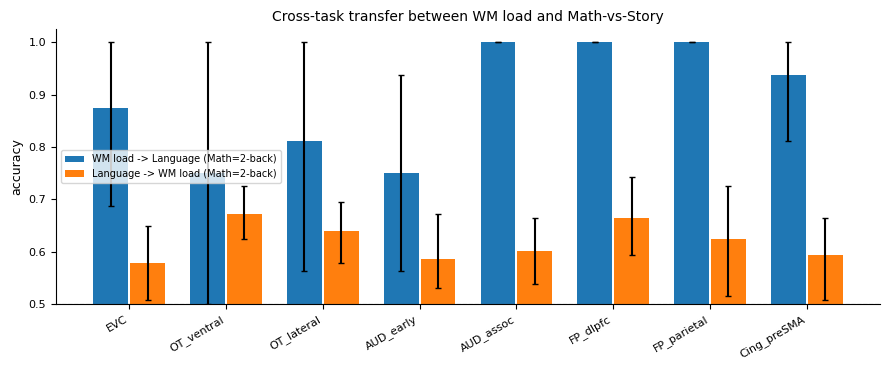

In [29]:
# ============ NOVELTY REFINEMENTS 4: cross-task decoding (does a WM-load decoder separate Math from Story?) ============
# Direction A: train on WM 0-back vs 2-back (other subjects), test on the held-out subject's Language Story (0) vs Math (1).
# Direction B: train on Language Story vs Math (other subjects), test on the held-out subject's WM 0-back (0) vs 2-back (1).
# Pre-specified mapping: Math <-> 2-back (the higher-demand condition). Accuracy < 0.5 would mean the mapping is reversed.
#
# Inference (revised): the SUBJECT is the unit. The Story-vs-Math pattern is nearly the same in every subject, so the blocks inside a
# subject (and across subjects) are not independent; flipping individual blocks gave p-values that were too small. Instead each
# subject's accuracy is flipped as a whole (acc -> 1 - acc), i.e. an exact sign-flip test of (accuracy - 0.5) across subjects.
# The smallest possible two-sided p is 2 / 2**n_subjects (0.0625 at n = 5, 0.0078 at n = 8, 0.0005 at n = 12).


def _ridge_scores(Xtr, ytr, Xte, lam_rel=LAM_REL):
    K = Xtr @ Xtr.T
    lam = lam_rel * np.trace(K) / len(K)
    t = np.where(ytr == 1, 1.0, -1.0)
    alpha = np.linalg.solve(K + lam * np.eye(len(K)), t - t.mean())
    return (Xte @ Xtr.T) @ alpha


def _acc(scores, y):
    return float(np.mean((scores > 0) == (y == 1)))


def subject_flip_pvalues(acc, n_perm=N_PERM_GROUP, seed=NOVELTY_SEED):
    """Exact (n <= 14) or sampled sign-flip null over subjects: flip a subject's accuracy to 1 - accuracy."""
    acc = np.asarray(acc, float)
    n, obs = len(acc), acc.mean()
    if n <= 14:
        flips = np.array(list(itertools.product([0, 1], repeat=n)), bool)
        null = np.where(flips, 1 - acc, acc).mean(axis=1)
        p_one = np.mean(null >= obs - 1e-12)
        p_two = np.mean(np.abs(null - .5) >= abs(obs - .5) - 1e-12)
    else:
        flips = np.random.default_rng(seed).integers(0, 2, size=(n_perm, n)).astype(bool)
        null = np.where(flips, 1 - acc, acc).mean(axis=1)
        p_one = (1 + np.sum(null >= obs - 1e-12)) / (n_perm + 1)
        p_two = (1 + np.sum(np.abs(null - .5) >= abs(obs - .5) - 1e-12)) / (n_perm + 1)
    return float(p_one), float(p_two)


def cross_task_roi(roi):
    wm, lg = build_dataset(roi, "WM"), build_dataset(roi, "LANGUAGE")
    res = {}
    for direction in ("WM load -> Language (Math=2-back)", "Language -> WM load (Math=2-back)"):
        per_subject = []
        for s in np.unique(wm["subj"]):
            if direction.startswith("WM"):
                tr, te = wm["subj"] != s, lg["subj"] == s
                sc = _ridge_scores(wm["X_load"][tr], wm["load"][tr], lg["X_main"][te])
                per_subject.append(_acc(sc, lg["y"][te]))
            else:
                tr, te = lg["subj"] != s, wm["subj"] == s
                sc = _ridge_scores(lg["X_main"][tr], lg["y"][tr], wm["X_load"][te])
                per_subject.append(_acc(sc, wm["load"][te]))
        a = np.array(per_subject)
        p_one, p_two = subject_flip_pvalues(a)
        res[direction] = dict(acc=a.mean(), per_subject=a, n_subjects=len(a), p_one=p_one, p_two=p_two)
    return res


ct_rows = []
for roi in roi_masks:
    for direction, r in cross_task_roi(roi).items():
        lo, hi = bootstrap_ci(r["per_subject"] - .5)
        ct_rows.append(dict(roi=roi, direction=direction, mean_acc=r["acc"], ci_lo=.5 + lo, ci_hi=.5 + hi,
                            n_subjects_above_chance=int((r["per_subject"] > .5).sum()), n_subjects=r["n_subjects"],
                            min_possible_p=2.0 / 2 ** r["n_subjects"], p_one_sided=r["p_one"], p_two_sided=r["p_two"]))
cross_task = pd.DataFrame(ct_rows)
cross_task["q_fdr"] = bh_fdr(cross_task.p_two_sided.values)
print("Cross-task decoding (chance 0.50). p: exact subject-level sign-flip test; q: BH across ROIs x directions.")
print(cross_task.round(3).to_string(index=False))
print("\nHow to read it: above chance in FP_parietal / FP_dlpfc / Cing_preSMA but not in EVC or AUD_early supports a shared demand axis."
      " Below chance with a small p means the mapping is reversed (Math looks like 0-back)."
      "\nCheck n_subjects_above_chance as well: a mean driven by one or two subjects is not a group effect.")

fig, ax = plt.subplots(figsize=(9, 3.8))
for k, (d, g) in enumerate(cross_task.groupby("direction", sort=False)):
    g = g.set_index("roi").loc[list(roi_masks)]
    x = np.arange(len(g)) + (k - .5) * .38
    ax.bar(x, g.mean_acc - .5, .36, bottom=.5, label=d, yerr=[g.mean_acc - g.ci_lo, g.ci_hi - g.mean_acc], capsize=2)
ax.axhline(.5, color="gray", ls="--", lw=.8)
ax.set_xticks(range(len(roi_masks))); ax.set_xticklabels(list(roi_masks), rotation=30, ha="right")
ax.set_ylabel("accuracy"); ax.legend(fontsize=7); ax.set_title("Cross-task transfer between WM load and Math-vs-Story", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(NOVELTY_DIR, "cross_task_decoding.png"), dpi=150); plt.show()
cross_task.to_csv(os.path.join(NOVELTY_DIR, "cross_task_decoding.csv"), index=False)


WM / EVC: 8 subjects, 128 samples, 3632 ROI features
LANGUAGE / EVC: 8 subjects, 32 samples, 3632 ROI features
WM / OT_ventral: 8 subjects, 128 samples, 1850 ROI features
LANGUAGE / OT_ventral: 8 subjects, 32 samples, 1850 ROI features
WM / OT_lateral: 8 subjects, 128 samples, 788 ROI features
LANGUAGE / OT_lateral: 8 subjects, 32 samples, 788 ROI features
WM / AUD_early: 8 subjects, 128 samples, 1187 ROI features
LANGUAGE / AUD_early: 8 subjects, 32 samples, 1187 ROI features
WM / AUD_assoc: 8 subjects, 128 samples, 2274 ROI features
LANGUAGE / AUD_assoc: 8 subjects, 32 samples, 2274 ROI features
WM / FP_dlpfc: 8 subjects, 128 samples, 3318 ROI features
LANGUAGE / FP_dlpfc: 8 subjects, 32 samples, 3318 ROI features
WM / FP_parietal: 8 subjects, 128 samples, 2460 ROI features
LANGUAGE / FP_parietal: 8 subjects, 32 samples, 2460 ROI features
WM / Cing_preSMA: 8 subjects, 128 samples, 1547 ROI features
LANGUAGE / Cing_preSMA: 8 subjects, 32 samples, 1547 ROI features
Cross-task decoding,

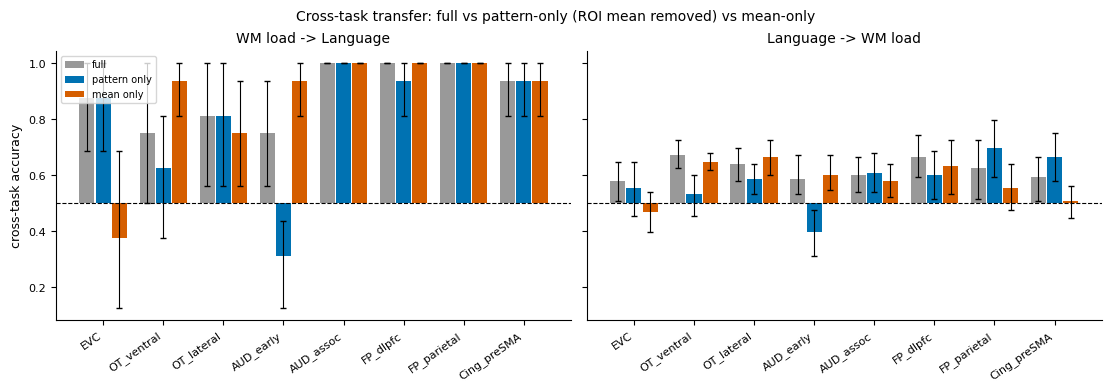

saved derivatives/figures/cross_task_mean_removed.png


In [30]:
# ============ CONTROL A: cross-task decoding with the ROI mean removed (pattern vs amplitude) ============
# Question: when a WM-load decoder separates Math from Story (or the reverse), is it using the SPATIAL PATTERN inside the ROI,
# or only the ROI's overall activation level going up/down in both tasks?
# Three versions of the same analysis (Coutanche 2013 sufficiency / necessity logic):
#   full          : the original cross-task analysis (pattern + mean together)
#   pattern only  : each sample's across-voxel ROI mean is subtracted first, so only the spatial pattern is left   (sufficiency)
#   mean only     : the classifier sees ONE number per sample, the ROI mean                                        (necessity)
# Reading it:  pattern-only stays high            -> shared multivoxel code
#              pattern-only ~ 0.5, mean-only high -> shared overall activation shift, not a shared pattern
#              both fall                           -> mixture; report as partial
# Needs the cross-task cell (_ridge_scores, _acc, subject_flip_pvalues) and the decoding-dataset cell (build_dataset) to have run.
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

VERSIONS = ("full", "pattern only", "mean only")
DIRECTIONS = ("WM load -> Language", "Language -> WM load")
PATTERN_TOL = 0.10          # heuristic used only for the one-word verdict (not a test)


def _transform(X, version):
    if version == "full":
        return X
    mu = X.mean(axis=1, keepdims=True)                  # one value per sample: the ROI-mean activation
    if version == "pattern only":
        return X - mu
    return mu                                           # "mean only": a single feature


def cross_task_versions(roi):
    wm, lg = build_dataset(roi, "WM"), build_dataset(roi, "LANGUAGE")
    out = {}
    for version in VERSIONS:
        Xw, Xl = _transform(wm["X_load"], version), _transform(lg["X_main"], version)
        for direction in DIRECTIONS:
            accs = []
            for s in np.unique(wm["subj"]):
                if direction.startswith("WM"):
                    tr, te = wm["subj"] != s, lg["subj"] == s
                    sc = _ridge_scores(Xw[tr], wm["load"][tr], Xl[te]);  accs.append(_acc(sc, lg["y"][te]))
                else:
                    tr, te = lg["subj"] != s, wm["subj"] == s
                    sc = _ridge_scores(Xl[tr], lg["y"][tr], Xw[te]);     accs.append(_acc(sc, wm["load"][te]))
            out[(version, direction)] = np.array(accs)
    return out


rows, per_subj = [], {}
for roi in roi_masks:
    res = cross_task_versions(roi)
    for (version, direction), a in res.items():
        p_one, p_two = subject_flip_pvalues(a)
        lo, hi = bootstrap_ci(a - .5)
        per_subj[(roi, version, direction)] = a
        rows.append(dict(roi=roi, direction=direction, version=version, mean_acc=a.mean(), ci_lo=.5 + lo, ci_hi=.5 + hi,
                         n_above_chance=int((a > .5).sum()), n_subjects=len(a), p_two_sided=p_two))
xt_mean = pd.DataFrame(rows)
xt_mean["q_fdr"] = bh_fdr(xt_mean.p_two_sided.values)

# ---- one-word verdict per ROI x direction (heuristic; with n = 5 the smallest possible p is 0.0625, so use the k/n counts) ----
verd = []
for (roi, direction), grp in xt_mean.groupby(["roi", "direction"], sort=False):
    grp = grp.set_index("version")
    full, pat, mea = grp.loc["full"], grp.loc["pattern only"], grp.loc["mean only"]
    if full.mean_acc < .6:
        v = "no transfer to begin with"
    elif pat.mean_acc >= full.mean_acc - PATTERN_TOL and pat.n_above_chance >= pat.n_subjects - 1:
        v = "shared PATTERN (survives mean removal)"
    elif mea.mean_acc >= full.mean_acc - PATTERN_TOL and pat.mean_acc < .6:
        v = "shared AMPLITUDE shift (mean alone suffices)"
    else:
        v = "mixed / partly pattern"
    verd.append(dict(roi=roi, direction=direction, full=full.mean_acc, pattern_only=pat.mean_acc,
                     mean_only=mea.mean_acc, pattern_k_of_n=f"{pat.n_above_chance}/{pat.n_subjects}", verdict=v))
xt_verdict = pd.DataFrame(verd)

pd.set_option("display.width", 220)
print("Cross-task decoding, three versions (chance 0.50). p = exact subject-level sign-flip; q = BH over all rows.")
print(xt_mean.round(3).to_string(index=False))
print("\nVerdict per ROI and direction (heuristic):")
print(xt_verdict.round(3).to_string(index=False))
print("\nHow to read it: the 'pattern only' rows answer the question. If they stay near the 'full' value, call the demand axis a shared"
      " multivoxel code. If they drop to ~0.5 while 'mean only' stays high, call it a shared activation shift."
      "\nAt n = 5 treat p < 0.0625 as impossible; use the k/n column. Do not describe either result as significant at the group level.")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True, constrained_layout=True)
colors = {"full": "#999999", "pattern only": "#0072B2", "mean only": "#D55E00"}
for ax, direction in zip(axes, DIRECTIONS):
    for k, version in enumerate(VERSIONS):
        sub = xt_mean[(xt_mean.direction == direction) & (xt_mean.version == version)].set_index("roi").loc[list(roi_masks)]
        x = np.arange(len(sub)) + (k - 1) * .27
        ax.bar(x, sub.mean_acc - .5, .25, bottom=.5, color=colors[version], label=version,
               yerr=[sub.mean_acc - sub.ci_lo, sub.ci_hi - sub.mean_acc], capsize=2, error_kw=dict(lw=.8))
    ax.axhline(.5, color="k", ls="--", lw=.8)
    ax.set_xticks(range(len(roi_masks))); ax.set_xticklabels(list(roi_masks), rotation=35, ha="right", fontsize=8)
    ax.set_title(direction, fontsize=10)
axes[0].set_ylabel("cross-task accuracy"); axes[0].legend(fontsize=7, loc="upper left")
fig.suptitle("Cross-task transfer: full vs pattern-only (ROI mean removed) vs mean-only", fontsize=10)
save_fig(fig, "cross_task_mean_removed.png")
xt_mean.to_csv(os.path.join(NOVELTY_DIR, "cross_task_mean_removed.csv"), index=False)
xt_verdict.to_csv(os.path.join(NOVELTY_DIR, "cross_task_mean_removed_verdict.csv"), index=False)


Event onsets/durations of each subject compared with 103414 (tolerance 0.01 s):
status        different  different number of blocks  identical
task     run                                                  
LANGUAGE LR           9                           5          0
         RL          14                           0          0
WM       LR          49                           0          7
         RL          49                           0          7

VERDICT: timing differs for some subject/condition, see the table below.
    task run subject  condition     vs  max_abs_diff_s                     status
      WM  LR  105014  0bk_faces 103414           0.093                  different
      WM  LR  105014 0bk_places 103414           0.187                  different
      WM  LR  105014  0bk_tools 103414           0.054                  different
      WM  LR  105014   0bk_body 103414           0.026                  different
      WM  LR  105014  2bk_faces 103414           0.053    

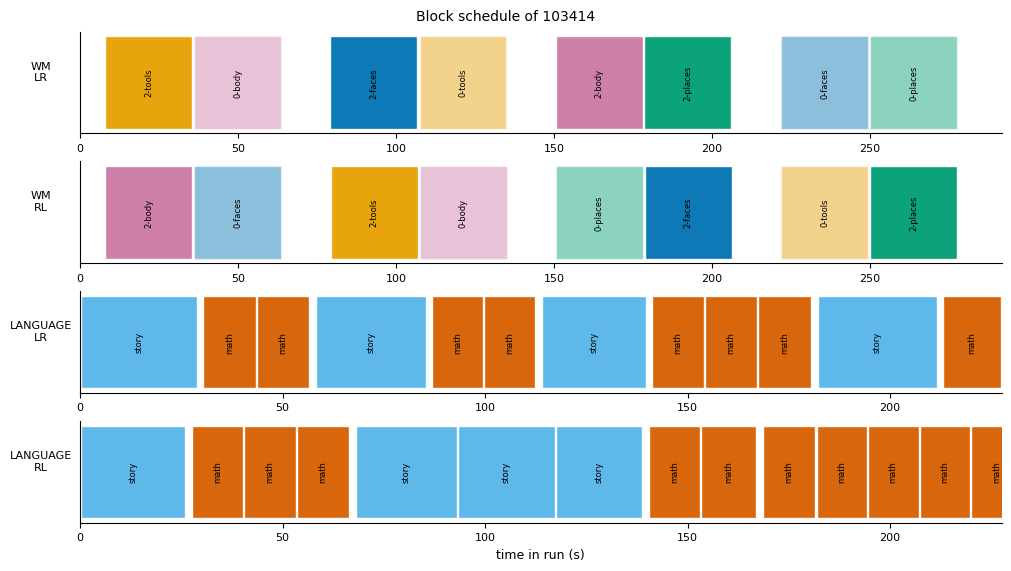

saved derivatives/figures/event_timing_schedule.png

What to do with the result:
 - Timing identical AND a label is strongly correlated with onset (|r| > 0.5): a shared drift could masquerade as that label.
   Weigh the matching decoding result with caution, and prefer analyses that cross the confound (e.g. LR-trained -> RL-tested
   when the two runs use a different block order, or the rfMRI null, which draws a different resting window per subject).
 - Timing identical but labels balanced in time (|r| small in BOTH runs): the risk is small; say so in the methods.
 - Timing differs across subjects: shared timing artifacts are not a concern for cross-subject decoding.


In [31]:
# ============ CONTROL B: do all subjects share the same event timing? ============
# HCP task timing is usually identical across subjects. If so, anything locked to the block schedule (a scanner drift, a
# cue-locked response, slow fatigue, the position of a block in the run) is SHARED by all subjects, and a leave-one-subject-out
# decoder can pick it up as if it were a category or load code. This cell measures how big that risk is. It reads only EV files.
#
# Edit EV_ROOT if your folders differ. {sid}, {task} (WM / LANGUAGE) and {run} (LR / RL) are filled in.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EV_ROOT = "/Users/shwetharao/Downloads/{sid}/MNINonLinear/Results/tfMRI_{task}_{run}/EVs"
EV_CONDS = {"WM": ["0bk_faces", "0bk_places", "0bk_tools", "0bk_body", "2bk_faces", "2bk_places", "2bk_tools", "2bk_body"],
            "LANGUAGE": ["story", "math"]}
EV_NTR = {"WM": 405, "LANGUAGE": 316}
EV_TR = 0.72
ONSET_TOL = 0.01      # seconds; two onsets closer than this count as identical


def read_ev(sid, task, run, cond):
    f = os.path.join(EV_ROOT.format(sid=sid, task=task, run=run), cond + ".txt")
    if not (os.path.isfile(f) and os.path.getsize(f) > 0):
        return None
    with open(f) as fh:
        return np.atleast_2d(np.loadtxt(fh))[:, :3]          # onset, duration, amplitude


# ---- 1. load every EV file and compare each subject with the first subject ----
ref_sid = SUBJECTS[0]
audit, events = [], {}
for task, conds in EV_CONDS.items():
    for run in ("LR", "RL"):
        for sid in SUBJECTS:
            for c in conds:
                events[(sid, task, run, c)] = read_ev(sid, task, run, c)
        for sid in SUBJECTS[1:]:
            for c in conds:
                a, b = events[(ref_sid, task, run, c)], events[(sid, task, run, c)]
                if a is None or b is None:
                    status, dmax = "missing file", np.nan
                elif a.shape != b.shape:
                    status, dmax = "different number of blocks", np.nan
                else:
                    dmax = float(np.abs(a[:, :2] - b[:, :2]).max())
                    status = "identical" if dmax <= ONSET_TOL else "different"
                audit.append(dict(task=task, run=run, subject=sid, condition=c, vs=ref_sid, max_abs_diff_s=dmax, status=status))
audit = pd.DataFrame(audit)
summ = audit.groupby(["task", "run"]).status.value_counts().unstack(fill_value=0)
print(f"Event onsets/durations of each subject compared with {ref_sid} (tolerance {ONSET_TOL} s):")
print(summ.to_string())
all_identical = bool((audit.status == "identical").all())
print("\nVERDICT:", "timing is IDENTICAL across all subjects, runs and conditions -> shared timing-locked signals are possible."
      if all_identical else "timing differs for some subject/condition, see the table below.")
if not all_identical:
    print(audit[audit.status != "identical"].round(3).to_string(index=False))

# ---- 2. block schedule of the reference subject: where does each condition sit in the run? ----
sched = []
for task in EV_CONDS:
    for run in ("LR", "RL"):
        for c in EV_CONDS[task]:
            ev = events[(ref_sid, task, run, c)]
            if ev is None:
                continue
            for k, (on, du, _) in enumerate(ev):
                sched.append(dict(task=task, run=run, condition=c, block=k, onset_s=on, duration_s=du,
                                  onset_frac_of_run=on / (EV_NTR[task] * EV_TR)))
sched = pd.DataFrame(sched)
print("\nBlock schedule (reference subject), sorted by onset:")
print(sched.sort_values(["task", "run", "onset_s"]).round(2).to_string(index=False))

# ---- 3. confound check: is condition label correlated with time in the run? ----
# For WM: LR and RL have one block per condition. If a condition always sits early (or late) in BOTH runs, a slow drift shared by
# subjects looks like that condition. The LOAD label is the main worry (0-back vs 2-back blocks may cluster in time).
conf = []
for task in EV_CONDS:
    for run in ("LR", "RL"):
        s = sched[(sched.task == task) & (sched.run == run)]
        if len(s) < 3:
            continue
        if task == "WM":
            lab_load = s.condition.str.startswith("2bk").astype(float).values
            conf.append(dict(task=task, run=run, label="load (2-back=1)",
                             corr_with_onset=float(np.corrcoef(lab_load, s.onset_s.values)[0, 1])))
            for cat in ("faces", "places", "tools", "body"):
                lab = s.condition.str.endswith(cat).astype(float).values
                conf.append(dict(task=task, run=run, label=f"category={cat}",
                                 corr_with_onset=float(np.corrcoef(lab, s.onset_s.values)[0, 1])))
        else:
            lab = (s.condition == "math").astype(float).values
            conf.append(dict(task=task, run=run, label="math=1",
                             corr_with_onset=float(np.corrcoef(lab, s.onset_s.values)[0, 1])))
conf = pd.DataFrame(conf)
print("\nCorrelation between each condition label and block onset time (|r| near 1 = label is confounded with time in the run):")
print(conf.round(2).to_string(index=False))

# ---- 4. same thing at the regressor level: how much of each HRF-convolved condition regressor is slow drift? ----
dt = 0.01
t_high = np.arange(0, EV_NTR["WM"] * EV_TR, dt)
t_tr = np.arange(EV_NTR["WM"]) * EV_TR
hrf = double_gamma_hrf(np.arange(0, 32.0, dt))
ramp = np.linspace(-1, 1, EV_NTR["WM"])
reg_rows = []
for run in ("LR", "RL"):
    for c in EV_CONDS["WM"]:
        ev = events[(ref_sid, "WM", run, c)]
        box = np.zeros_like(t_high)
        for on, du, am in ev:
            box[(t_high >= on) & (t_high < on + du)] = am
        reg = np.interp(t_tr, t_high, np.convolve(box, hrf)[:len(t_high)] * dt)
        reg_rows.append(dict(run=run, condition=c, corr_with_linear_drift=float(np.corrcoef(reg, ramp)[0, 1])))
reg_rows = pd.DataFrame(reg_rows)
print("\nCorrelation of each convolved WM regressor with a linear drift across the run:")
print(reg_rows.round(2).to_string(index=False))

# ---- 5. figure: the schedule, both runs, WM and Language ----
fig, axes = plt.subplots(4, 1, figsize=(10, 5.6), sharex=False, constrained_layout=True)
pal = {"faces": "#0072B2", "places": "#009E73", "tools": "#E69F00", "body": "#CC79A7", "story": "#56B4E9", "math": "#D55E00"}
for ax, (task, run) in zip(axes, [("WM", "LR"), ("WM", "RL"), ("LANGUAGE", "LR"), ("LANGUAGE", "RL")]):
    s = sched[(sched.task == task) & (sched.run == run)]
    for _, r in s.iterrows():
        key = r.condition.split("_")[-1]
        two = r.condition.startswith("2bk")
        ax.barh(0, r.duration_s, left=r.onset_s, color=pal.get(key, "gray"), alpha=.95 if two or task == "LANGUAGE" else .45,
                edgecolor="white")
        ax.text(r.onset_s + r.duration_s / 2, 0, r.condition.replace("bk_", "-"), ha="center", va="center", fontsize=6, rotation=90)
    ax.set_xlim(0, EV_NTR[task] * EV_TR); ax.set_yticks([]); ax.set_ylabel(f"{task}\n{run}", rotation=0, labelpad=28, fontsize=8)
axes[-1].set_xlabel("time in run (s)")
fig.suptitle(f"Block schedule of {ref_sid}" + (" (identical in every subject)" if all_identical else ""), fontsize=10)
save_fig(fig, "event_timing_schedule.png")
audit.to_csv(os.path.join(NOVELTY_DIR, "event_timing_audit.csv"), index=False)
conf.to_csv(os.path.join(NOVELTY_DIR, "event_timing_confounds.csv"), index=False)

print("\nWhat to do with the result:")
print(" - Timing identical AND a label is strongly correlated with onset (|r| > 0.5): a shared drift could masquerade as that label."
      "\n   Weigh the matching decoding result with caution, and prefer analyses that cross the confound (e.g. LR-trained -> RL-tested"
      "\n   when the two runs use a different block order, or the rfMRI null, which draws a different resting window per subject).")
print(" - Timing identical but labels balanced in time (|r| small in BOTH runs): the risk is small; say so in the methods.")
print(" - Timing differs across subjects: shared timing artifacts are not a concern for cross-subject decoding.")


Pattern correlation between WM load (2-back > 0-back) and Language Math > Story, by ROI (positive = same direction)
        roi  mean_r  ci_lo  ci_hi  p_signflip  mean_r_corrected  mean_rel_wm  mean_rel_lang  q_fdr
        EVC   0.085 -0.052  0.220       0.344             0.341        0.162          0.441  0.344
 OT_ventral   0.070  0.024  0.116       0.031             0.148        0.060          0.342  0.041
 OT_lateral   0.184  0.123  0.246       0.008             0.557        0.095          0.575  0.023
  AUD_early   0.050 -0.007  0.114       0.210             0.597        0.055          0.426  0.240
  AUD_assoc   0.123  0.061  0.175       0.014             0.712        0.095          0.709  0.023
   FP_dlpfc   0.241  0.128  0.332       0.014             0.421        0.291          0.728  0.023
FP_parietal   0.430  0.263  0.515       0.014             0.659        0.402          0.761  0.023
Cing_preSMA   0.214  0.103  0.311       0.014             0.839        0.180          0.552 

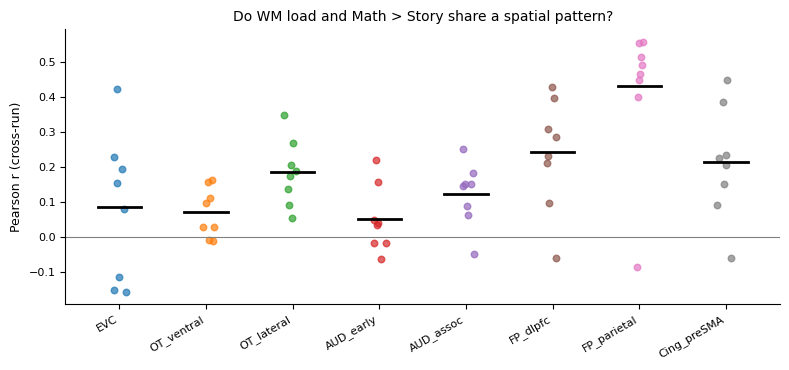

In [32]:
# ============ NOVELTY REFINEMENTS 5: shared demand axis (WM load pattern vs Math-minus-Story pattern, same ROIs) ============
# Per subject and ROI: Pearson r between the WM load pattern (mean 2-back minus mean 0-back t-values) and the Language
# Math-minus-Story pattern. The two patterns are taken from DIFFERENT scanner runs (WM LR with Language RL, and WM RL with
# Language LR; averaged) so that shared scan-session noise cannot create a correlation.
# r_corrected divides by the geometric mean of the two within-task LR/RL reliabilities (descriptive: how large is r compared
# with the most it could be given the noise).
def _r(a, b):
    return float(np.corrcoef(a, b)[0, 1])


def _fz(r):
    return np.arctanh(np.clip(r, -.999, .999))


da_rows = []
for sid in SUBJECTS:
    P = get_patterns(sid)
    wm = {run: P[f"WM_{run}_t"][4:8].mean(0) - P[f"WM_{run}_t"][:4].mean(0) for run in ("LR", "RL")}
    lg = {run: P[f"LANGUAGE_{run}_t"][1] - P[f"LANGUAGE_{run}_t"][0] for run in ("LR", "RL")}      # rows: story, math
    for roi, mask in roi_masks.items():
        a1, b1, a2, b2 = wm["LR"][mask], lg["RL"][mask], wm["RL"][mask], lg["LR"][mask]
        r = float(np.tanh(.5 * (_fz(_r(a1, b1)) + _fz(_r(a2, b2)))))
        rel_wm, rel_lg = _r(wm["LR"][mask], wm["RL"][mask]), _r(lg["LR"][mask], lg["RL"][mask])
        r_corr = r / np.sqrt(rel_wm * rel_lg) if rel_wm > 0 and rel_lg > 0 else np.nan
        da_rows.append(dict(subject=sid, roi=roi, r_cross=r, rel_wm_load=rel_wm, rel_lang=rel_lg, r_corrected=r_corr))
demand = pd.DataFrame(da_rows)

g_rows = []
for roi in roi_masks:
    v = demand[demand.roi == roi].r_cross.values
    lo, hi = bootstrap_ci(v)
    g_rows.append(dict(roi=roi, mean_r=float(np.tanh(np.mean(_fz(v)))), ci_lo=lo, ci_hi=hi, p_signflip=signflip_mean_p(v),
                       mean_r_corrected=np.nanmean(demand[demand.roi == roi].r_corrected),
                       mean_rel_wm=demand[demand.roi == roi].rel_wm_load.mean(), mean_rel_lang=demand[demand.roi == roi].rel_lang.mean()))
demand_group = pd.DataFrame(g_rows)
demand_group["q_fdr"] = bh_fdr(demand_group.p_signflip.values)
print("Pattern correlation between WM load (2-back > 0-back) and Language Math > Story, by ROI (positive = same direction)")
print(demand_group.round(3).to_string(index=False))
print("\nWith 5 subjects the smallest possible sign-flip p is 0.0625, so nothing can reach q < 0.05: read the sign consistency and CI instead.")
print("Subjects with r > 0 per ROI:"); print(demand.assign(pos=demand.r_cross > 0).groupby("roi").pos.sum().to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
rg = np.random.default_rng(NOVELTY_SEED)
for i, roi in enumerate(roi_masks):
    v = demand[demand.roi == roi].r_cross.values
    ax.scatter(np.full(len(v), i) + rg.uniform(-.1, .1, len(v)), v, s=22, alpha=.7)
    ax.plot([i - .25, i + .25], [demand_group.mean_r[i]] * 2, "k", lw=2)
ax.axhline(0, color="gray", lw=.8); ax.set_ylabel("Pearson r (cross-run)")
ax.set_xticks(range(len(roi_masks))); ax.set_xticklabels(list(roi_masks), rotation=30, ha="right")
ax.set_title("Do WM load and Math > Story share a spatial pattern?", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(NOVELTY_DIR, "demand_axis_pattern_correlation.png"), dpi=150); plt.show()
demand.to_csv(os.path.join(NOVELTY_DIR, "demand_axis_subject_level.csv"), index=False)
demand_group.to_csv(os.path.join(NOVELTY_DIR, "demand_axis_group.csv"), index=False)


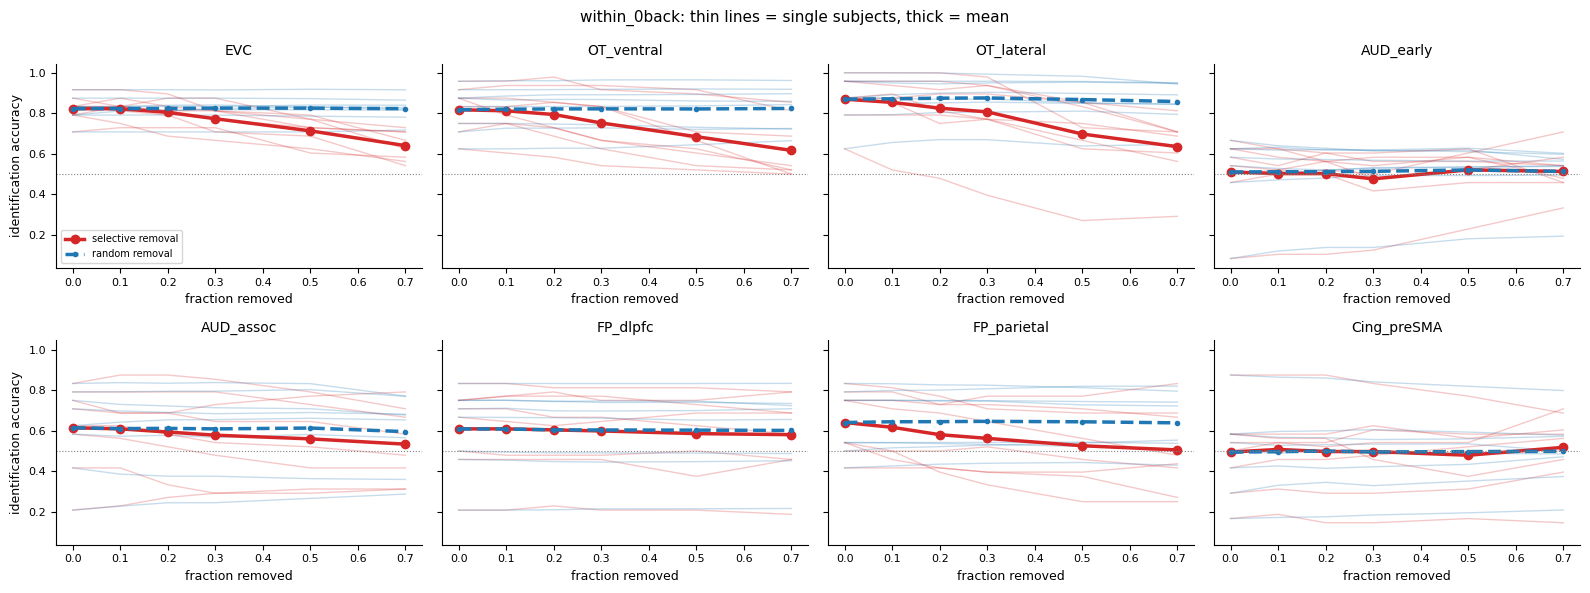

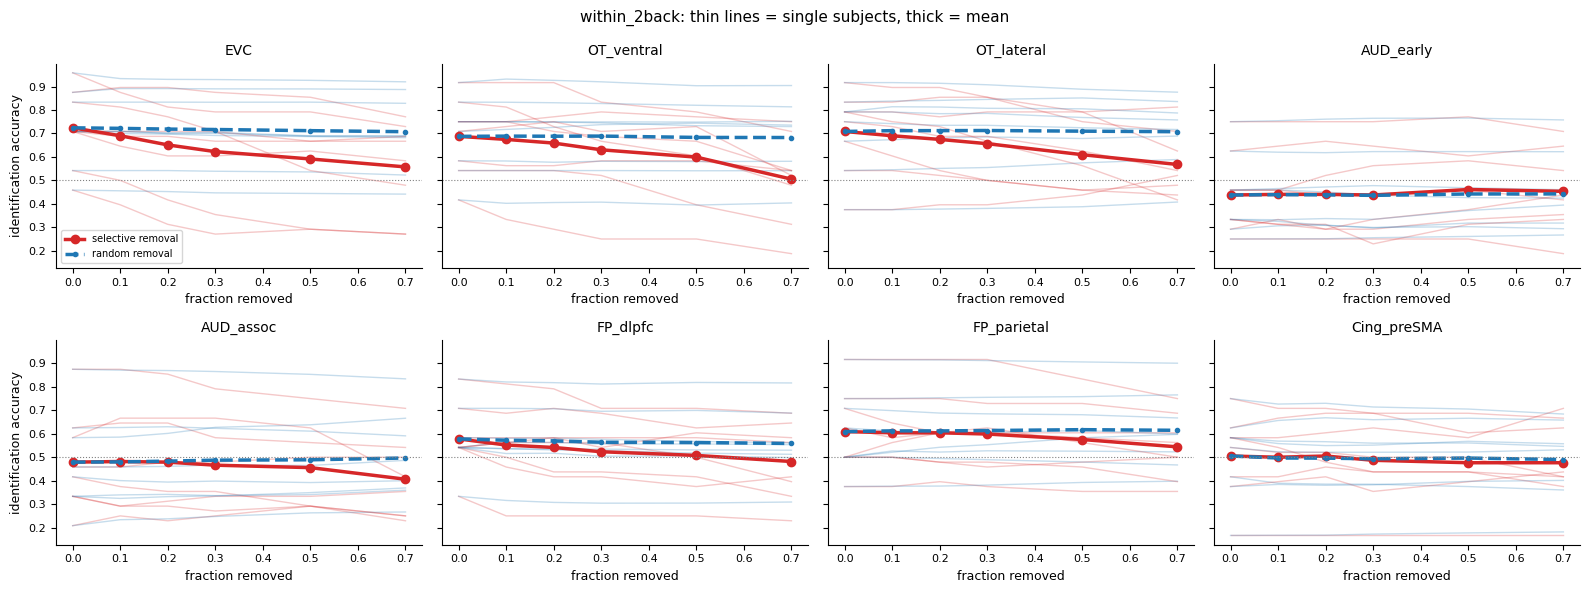

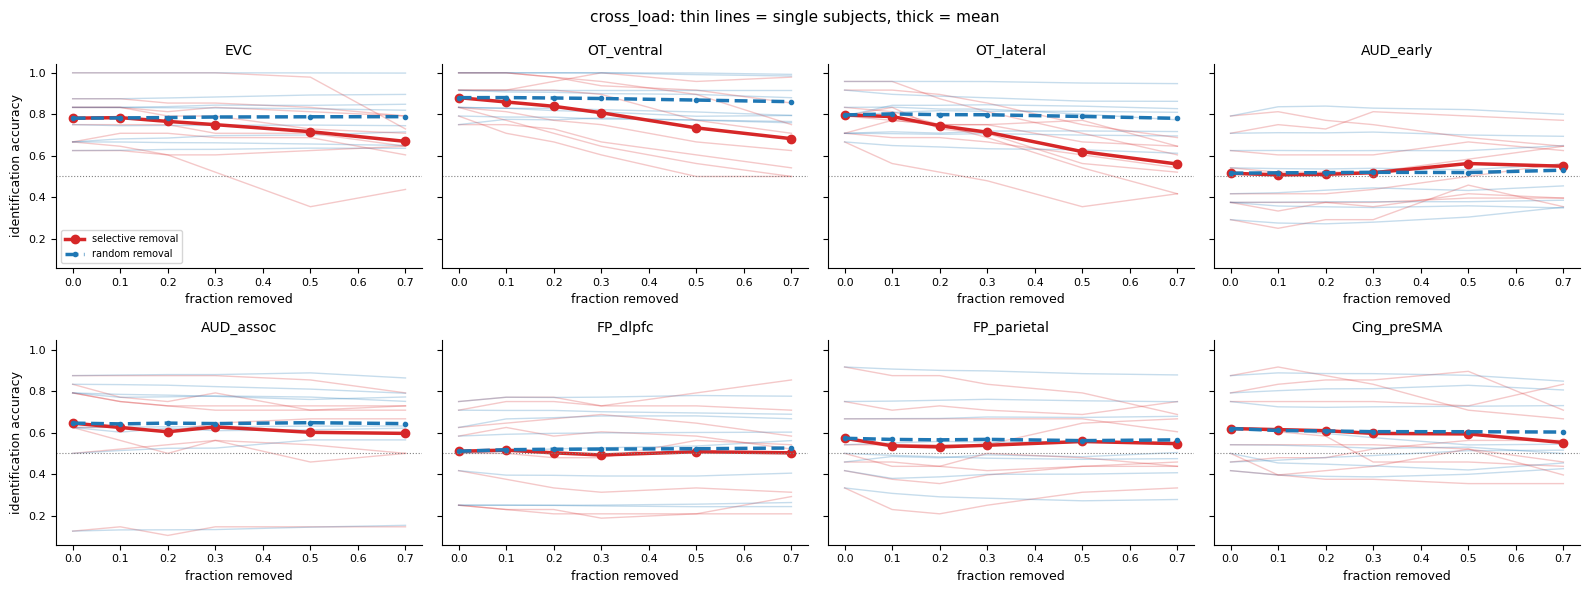

Excess accuracy drop from removing the most selective voxels, beyond random removal (positive = information concentrated in them)
     outcome         roi  fraction  selective_drop  random_drop  excess_drop  ci_lo  ci_hi  n_pos  n_subjects  p_signflip  q_fdr
within_0back         EVC       0.3           0.049       -0.003        0.052  0.006  0.097      6           8       0.097  0.179
within_0back         EVC       0.5           0.109       -0.003        0.112  0.088  0.136      8           8       0.008  0.049
within_0back  OT_ventral       0.3           0.065       -0.004        0.070  0.027  0.117      7           8       0.023  0.078
within_0back  OT_ventral       0.5           0.133       -0.004        0.137  0.085  0.187      8           8       0.008  0.049
within_0back  OT_lateral       0.3           0.063       -0.006        0.069  0.023  0.133      8           8       0.008  0.049
within_0back  OT_lateral       0.5           0.172        0.002        0.170  0.103  0.243      

In [33]:
# ============ NOVELTY REFINEMENTS 6: selective-voxel removal, per-ROI panels with per-subject lines + paired test ============
# Needs removal_df from cell 31. Question: is category information concentrated in the most selective voxels (steep drop)
# or distributed (flat, like random removal)? The relevant quantity is the EXCESS drop: selective drop minus random drop, per subject.
if "removal_df" not in globals() or removal_df.empty:
    raise RuntimeError("Run cell 31 first (removal_df is missing or empty).")
OUTCOMES = ["within_0back", "within_2back", "cross_load"]
roi_list = list(roi_masks)
for outcome in OUTCOMES:
    fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharey=True)
    for ax, roi in zip(axes.ravel(), roi_list):
        q = removal_df[(removal_df.roi == roi) & (removal_df.outcome == outcome)]
        for sid, g in q.groupby("subject"):
            g = g.sort_values("removed_fraction")
            ax.plot(g.removed_fraction, g.selective_removal, color="tab:red", alpha=.25, lw=1)
            ax.plot(g.removed_fraction, g.random_removal, color="tab:blue", alpha=.25, lw=1)
        m = q.groupby("removed_fraction")[["selective_removal", "random_removal"]].mean()
        ax.plot(m.index, m.selective_removal, color="tab:red", lw=2.5, marker="o", label="selective removal")
        ax.plot(m.index, m.random_removal, color="tab:blue", lw=2.5, marker=".", ls="--", label="random removal")
        ax.axhline(.5, color="gray", ls=":", lw=.8); ax.set_title(roi, fontsize=10); ax.set_xlabel("fraction removed")
    axes[0, 0].set_ylabel("identification accuracy"); axes[1, 0].set_ylabel("identification accuracy"); axes[0, 0].legend(fontsize=7)
    fig.suptitle(f"{outcome}: thin lines = single subjects, thick = mean", fontsize=11)
    plt.tight_layout(); plt.savefig(os.path.join(NOVELTY_DIR, f"removal_panels_{outcome}.png"), dpi=150); plt.show()

ex_rows = []
for outcome in OUTCOMES:
    for roi in roi_list:
        q = removal_df[(removal_df.roi == roi) & (removal_df.outcome == outcome)]
        base = q[q.removed_fraction == 0].set_index("subject").selective_removal
        for frac in (.3, .5):
            f = q[q.removed_fraction == frac].set_index("subject")
            if f.empty:
                continue
            excess = (base - f.selective_removal) - (base - f.random_removal)          # selective drop minus random drop (per subject)
            lo, hi = bootstrap_ci(excess.values)
            ex_rows.append(dict(outcome=outcome, roi=roi, fraction=frac, selective_drop=(base - f.selective_removal).mean(),
                                random_drop=(base - f.random_removal).mean(), excess_drop=excess.mean(), ci_lo=lo, ci_hi=hi,
                                n_pos=int((excess > 0).sum()), n_subjects=len(excess), p_signflip=signflip_mean_p(excess.values)))
removal_excess = pd.DataFrame(ex_rows)
removal_excess["q_fdr"] = bh_fdr(removal_excess.p_signflip.values)
print("Excess accuracy drop from removing the most selective voxels, beyond random removal (positive = information concentrated in them)")
print(removal_excess.round(3).to_string(index=False))
removal_excess.to_csv(os.path.join(NOVELTY_DIR, "removal_excess_drop.csv"), index=False)


In [34]:
# ============ NOVELTY REFINEMENTS 7: one evidence table for the claims ============
# Collects the results above into a claim-by-ROI table and flags the dissociation pattern automatically.
# Needs: wm_dec (cell 22), h1_full_summary, dec_equiv, cross_task, demand_group (this section). Missing pieces are left blank.
def _get(df, name):
    return df if name in globals() and isinstance(globals()[name], pd.DataFrame) else None


rows = []
for roi in roi_masks:
    r = dict(roi=roi)
    cat = wm_dec[(wm_dec.roi == roi) & wm_dec.analysis.str.startswith("category")]
    ld = wm_dec[(wm_dec.roi == roi) & wm_dec.analysis.str.startswith("load")]
    r["category_q_max_over_4_pairings"] = cat.q_fdr.max()
    r["category_acc_mean"] = cat.mean_acc.mean()
    r["load_acc"], r["load_q"] = ld.mean_acc.iloc[0], ld.q_fdr.iloc[0]
    r["pattern"] = ("category only" if (cat.q_fdr.max() < .05 and ld.q_fdr.iloc[0] >= .05) else
                    "load only" if (cat.q_fdr.max() >= .05 and ld.q_fdr.iloc[0] < .05) else
                    "both" if (cat.q_fdr.max() < .05 and ld.q_fdr.iloc[0] < .05) else "neither")
    for df, cols, tag in ((h1_full_summary, ["transfer_mean", "p_perm_transfer_gt0", "equivalent_to_invariance"], "h1"),
                          (dec_equiv, ["mean_loss", "verdict"], "dec")):
        row = df[df.roi == roi]
        for c in cols:
            r[f"{tag}:{c}"] = row[c].iloc[0] if len(row) else np.nan
    ct = cross_task[cross_task.roi == roi]
    for _, x in ct.iterrows():
        r["xtask " + x.direction.split(" (")[0] + " acc"] = x.mean_acc
        r["xtask " + x.direction.split(" (")[0] + " q"] = x.q_fdr
    dm = demand_group[demand_group.roi == roi]
    r["demand_axis_r"] = dm.mean_r.iloc[0] if len(dm) else np.nan
    rows.append(r)
evidence = pd.DataFrame(rows)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(evidence.round(3).to_string(index=False))
evidence.to_csv(os.path.join(NOVELTY_DIR, "novelty_evidence_summary.csv"), index=False)
print("\nPattern counts:", evidence.pattern.value_counts().to_dict())
print("Saved to", os.path.join(NOVELTY_DIR, "novelty_evidence_summary.csv"))


        roi  category_q_max_over_4_pairings  category_acc_mean  load_acc  load_q   pattern  h1:transfer_mean  h1:p_perm_transfer_gt0 h1:equivalent_to_invariance  dec:mean_loss                     dec:verdict  xtask WM load -> Language acc  xtask WM load -> Language q  xtask Language -> WM load acc  xtask Language -> WM load q  demand_axis_r
        EVC                           0.002              0.688     0.680   0.002      both             0.947                   0.000                       False          0.156                loss across load                          0.875                        0.056                          0.578                        0.142          0.085
 OT_ventral                           0.002              0.676     0.664   0.004      both             1.001                   0.000                       False          0.086                loss across load                          0.750                        0.219                          0.672                

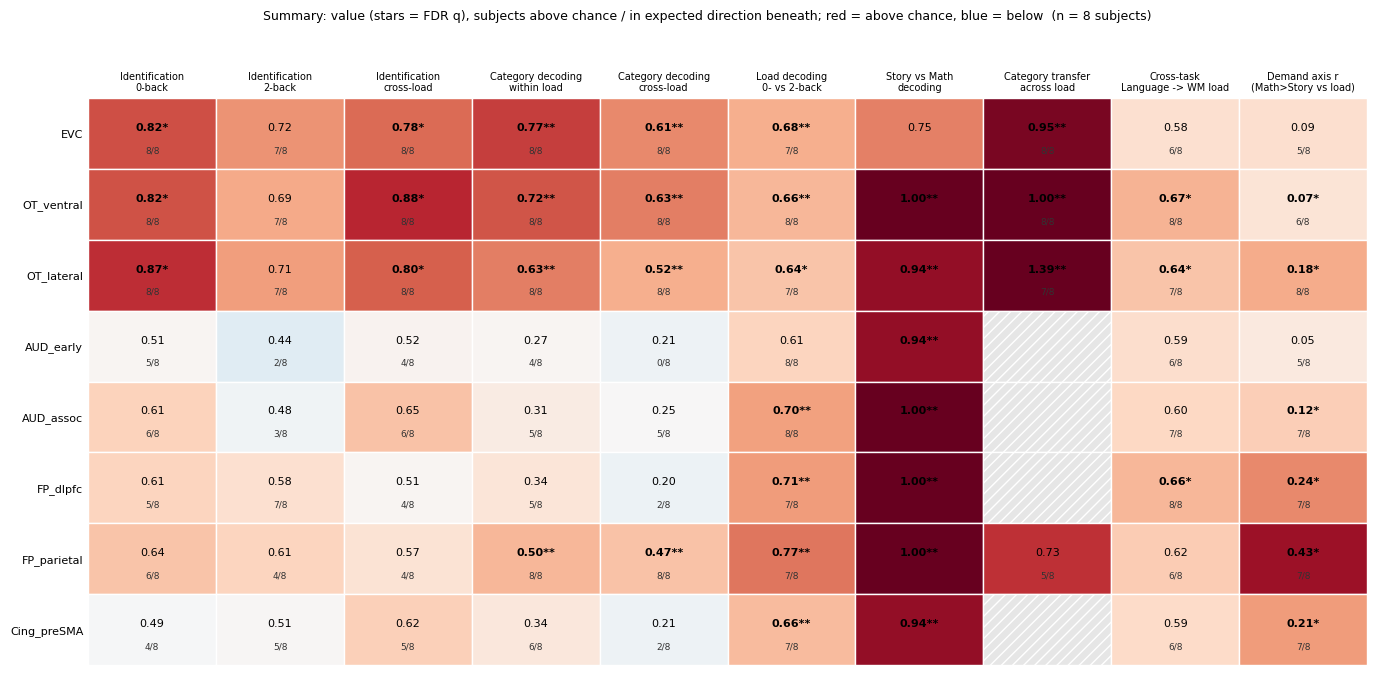

saved derivatives/figures/summary_roi_by_analysis.png


In [35]:
# ============ ONE-PAGE SUMMARY: ROI x analysis ============
# Colour = effect size relative to chance (red = above, blue = below), value on the first line, stars = FDR q < .05 / .01,
# second line = subjects above chance (or in the expected direction). With few subjects stars are rare (smallest sign-flip p = 2 / 2^n),
# so the k/n line is the more honest summary. Grey hatched cells = not interpretable or not computed.
n_subj = len(SUBJECTS)
cols = []     # (title, chance, vmax, {roi: (value, q, k_positive)})


def _star(q):
    return "" if q is None or not np.isfinite(q) else "**" if q < .01 else "*" if q < .05 else ""


def add(title, chance, vmax, getter):
    d = {}
    for roi in ROI_ORDER:
        try:
            d[roi] = getter(roi)
        except Exception:
            d[roi] = (np.nan, np.nan, None)
    cols.append((title, chance, vmax, d))


if "wm_group" in globals() and "wm_res" in globals():
    for m, t in (("id_0back", "Identification\n0-back"), ("id_2back", "Identification\n2-back"), ("id_cross_load", "Identification\ncross-load")):
        add(t, .5, 1.0, lambda roi, m=m: (float(wm_group[(wm_group.roi == roi) & (wm_group.metric == m)].mean_acc.iloc[0]),
                                          float(wm_group[(wm_group.roi == roi) & (wm_group.metric == m)].q_fdr.iloc[0]),
                                          int((wm_res[wm_res.roi == roi][m] > .5).sum())))


def _dec(names, chance):
    def g(roi):
        sub = wm_dec[(wm_dec.roi == roi) & wm_dec.analysis.isin(names)]
        per = np.mean([subj_acc[(roi, n)] for n in names], axis=0)
        return float(sub.mean_acc.mean()), float(sub.q_fdr.max()), int((per > chance).sum())
    return g


if "wm_dec" in globals():
    add("Category decoding\nwithin load", .25, 1.0, _dec(["category | 0-back -> 0-back", "category | 2-back -> 2-back"], .25))
    add("Category decoding\ncross-load", .25, 1.0, _dec(["category | 0-back -> 2-back", "category | 2-back -> 0-back"], .25))
    add("Load decoding\n0- vs 2-back", .5, 1.0, _dec(["load (0- vs 2-back)"], .5))
if "lang_dec" in globals():
    add("Story vs Math\ndecoding", .5, 1.0, lambda roi: (float(lang_dec[lang_dec.roi == roi].mean_acc.iloc[0]), float(lang_dec[lang_dec.roi == roi].q_fdr.iloc[0]), None))
if "h1_full_summary" in globals():
    def _h1(roi):
        r = h1_full_summary[h1_full_summary.roi == roi].iloc[0]
        k = int((h1_full[(h1_full.roi == roi)].transfer_pooled > 0).sum()) if np.isfinite(r.transfer_mean) else None
        return float(r.transfer_mean), float(r.q_perm), k
    add("Category transfer\nacross load", 0.0, 1.0, _h1)
if "cross_task" in globals():
    def _xt(roi):
        r = cross_task[(cross_task.roi == roi) & cross_task.direction.str.startswith("Language")].iloc[0]
        return float(r.mean_acc), float(r.q_fdr), int(r.n_subjects_above_chance)
    add("Cross-task\nLanguage -> WM load", .5, 1.0, _xt)
if "demand_group" in globals():
    add("Demand axis r\n(Math>Story vs load)", 0.0, 0.5,
        lambda roi: (float(demand_group[demand_group.roi == roi].mean_r.iloc[0]), float(demand_group[demand_group.roi == roi].q_fdr.iloc[0]),
                     int((demand[demand.roi == roi].r_cross > 0).sum())))

fig, ax = plt.subplots(figsize=(1.45 * len(cols) + 2, 0.62 * len(ROI_ORDER) + 2.4))
for j, (title, chance, vmax, d) in enumerate(cols):
    for i, roi in enumerate(ROI_ORDER):
        v, q, k = d[roi]
        if not np.isfinite(v):
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, facecolor="#e6e6e6", hatch="///", edgecolor="white"))
            continue
        eff = np.clip((v - chance) / (vmax - chance), -1, 1)
        ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, facecolor=plt.cm.RdBu_r(0.5 + 0.5 * eff), edgecolor="white"))
        ax.text(j, i - .08, f"{v:.2f}{_star(q)}", ha="center", va="center", fontsize=8, fontweight="bold" if _star(q) else "normal")
        if k is not None:
            ax.text(j, i + .24, f"{k}/{n_subj}", ha="center", va="center", fontsize=6.5, color="#333333")
ax.set_xlim(-.5, len(cols) - .5); ax.set_ylim(len(ROI_ORDER) - .5, -.5)
ax.set_xticks(range(len(cols))); ax.set_xticklabels([c[0] for c in cols], fontsize=7); ax.xaxis.tick_top()
ax.set_yticks(range(len(ROI_ORDER))); ax.set_yticklabels(ROI_ORDER)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.tick_params(length=0)
fig.suptitle(n_title("Summary: value (stars = FDR q), subjects above chance / in expected direction beneath; red = above chance, blue = below"), fontsize=9, y=1.0)
save_fig(fig, "summary_roi_by_analysis.png")
